# Engenharia de Features para Clustering: California Housing

**Objetivo deste notebook:** preparar os dados do California Housing para rodar algoritmos de **clustering** (K-Means, DBSCAN, clustering hierárquico etc.).

Vamos passar por 7 etapas:

| Etapa | O que fazemos | Pergunta principal |
|---|---|---|
| 1 | Detecção de outliers | Quais valores são estranhos, e *por quê*? |
| 2 | Tratamento de outliers | Removemos, limitamos ou transformamos? |
| 3 | Scaling | Como colocar todas as colunas na mesma escala? |
| 4 | Tratamento de nulos | Como preencher valores faltantes de forma inteligente? |
| 5 | Encoding de variáveis | Como transformar categorias de texto em números? |
| 6 | Criação de features | Quais novas colunas contam uma história melhor? |
| 7 | Seleção de features | Quais colunas o clustering deve realmente usar? |

Cada etapa mostra o código, o resultado e **o raciocínio por trás de cada decisão**.

> **Nota sobre os números:** no texto usamos o formato brasileiro (vírgula decimal: 0,5; ponto para milhar: 20.640). As saídas do código usam o formato do Python (0.5; 20,640).

## Por que "para clustering" muda tudo

Algoritmos de clustering agrupam linhas que estão **próximas umas das outras**. "Próximo" é medido com uma **distância** (normalmente a distância euclidiana).

Esse único fato guia todas as decisões deste notebook:

- **Outliers** puxam os centros dos clusters na sua direção, ou viram pequenos clusters sozinhos.
- **A escala** importa. Uma coluna medida em milhares (população) vence uma coluna medida em unidades (cômodos) em qualquer distância.
- **O encoding** cria distâncias entre categorias. Um encoding ruim cria distâncias falsas.
- **Colunas demais** fazem todas as distâncias parecerem iguais (a *maldição da dimensionalidade*), e os clusters ficam difusos.

> Regra de ouro deste notebook: antes de cada decisão, pergunte *"o que isso faz com as distâncias entre as linhas?"*

### Uma nota sobre a ordem das etapas

- Seguimos as 7 etapas na ordem do curso.
- Num projeto real, você vai e volta entre as etapas. Duas regras nos mantêm seguros aqui:
  1. Mantemos os dados nas suas **unidades naturais** (dólares, cômodos, pessoas) pelo maior tempo possível. As novas features (etapa 6) precisam ser calculadas em unidades naturais: a razão entre dois números já padronizados não tem significado.
  2. **Escolhemos** o scaler na etapa 3, mas **aplicamos de novo no final** (etapa 7), sobre o conjunto final de colunas. Assim, as colunas novas e as codificadas passam pelo mesmo scaling.
- Cada etapa cria uma nova tabela (`df_raw` → `df_clean` → ...). Você sempre pode comparar o "antes" e o "depois".

## Setup

- Importamos as bibliotecas de que precisamos.
- Fixamos um `RANDOM_STATE`, para que cada passo aleatório dê o mesmo resultado sempre que você rodar o notebook.
- O bloco longo sobre gráficos só define cores e fontes. Pode pular.

In [1]:
# --- Standard libraries
from pathlib import Path
import warnings

# --- Data handling
import numpy as np
import pandas as pd

# --- Plots
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

# --- Machine learning tools (scikit-learn)
from sklearn.datasets import fetch_california_housing

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

RANDOM_STATE = 42          # same random numbers every run
DATA_DIR = Path("data")    # external files are downloaded here once
DATA_DIR.mkdir(exist_ok=True)

In [2]:
# --- Plot style (colours and fonts only; safe to skip) ---------------------
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"   # colour-blind-safe trio
GRAY, LIGHT_GRAY = "#898781", "#c3c2b7"                # for "context" points
PALETTE = [BLUE, ORANGE, AQUA, "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]

# Single-hue map (light -> dark blue) for "low -> high" values
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#b7d3f6", "#6da7ec", "#2a78d6", "#1c5cab", "#0d366b"])
# Diverging map (blue <-> gray <-> red) for negative vs positive values
DIVERGING = LinearSegmentedColormap.from_list("diverging", [BLUE, "#f0efec", "#e34948"])

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "savefig.facecolor": "#fcfcfb", "figure.dpi": 100,
    "axes.edgecolor": LIGHT_GRAY, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "axes.labelsize": 9,
    "xtick.color": GRAY, "ytick.color": GRAY, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "text.color": "#0b0b0b", "legend.frameon": False, "legend.fontsize": 8,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
})

## Carregar os dados

- Usamos a versão que vem com o **scikit-learn** (`fetch_california_housing`).
- Ela tem 20.640 linhas, 8 colunas de features e 1 coluna target (`MedHouseVal`). Não há nulos nem colunas de texto.
- A função abaixo tem um **plano B**: se o download for bloqueado (por um firewall corporativo, por exemplo), ela reconstrói exatamente a mesma tabela a partir de uma cópia do arquivo original no GitHub.

In [3]:
def load_california_housing():
    """Return the California Housing data as one DataFrame (features + target)."""
    try:
        return fetch_california_housing(as_frame=True).frame
    except Exception as error:
        print(f"scikit-learn download failed ({error}). Using the GitHub mirror.")
        url = ("https://media.githubusercontent.com/media/EpistasisLab/pmlb/"
               "master/datasets/537_houses/537_houses.tsv.gz")
        raw = pd.read_csv(url, sep="\t")
        households = raw["households"].round()
        return pd.DataFrame({
            "MedInc": raw["median_income"].round(4),
            "HouseAge": raw["housing_median_age"].round(),
            "AveRooms": raw["total_rooms"].round() / households,
            "AveBedrms": raw["total_bedrooms"].round() / households,
            "Population": raw["population"].round(),
            "AveOccup": raw["population"].round() / households,
            "Latitude": raw["latitude"].round(2),
            "Longitude": raw["longitude"].round(2),
            "MedHouseVal": raw["target"].round() / 100_000,
        })


df_raw = load_california_housing()
print(f"Rows: {df_raw.shape[0]:,}  |  Columns: {df_raw.shape[1]}")
df_raw.head()

Rows: 20,640  |  Columns: 9


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.325,41.000,6.984,1.024,322.000,2.556,37.880,-122.230,4.526
1,8.301,21.000,6.238,0.972,"2,401.000",2.110,37.860,-122.220,3.585
2,7.257,52.000,8.288,1.073,496.000,2.802,37.850,-122.240,3.521
3,5.643,52.000,5.817,1.073,558.000,2.548,37.850,-122.250,3.413
4,3.846,52.000,6.282,1.081,565.000,2.181,37.850,-122.250,3.422


### O que significa cada linha e cada coluna?

Cada linha é um **block group** do Censo dos EUA de 1990. Um block group é uma pequena vizinhança, normalmente com 600 a 3.000 pessoas.

| Coluna | Significado | Unidade |
|---|---|---|
| `MedInc` | Renda mediana dos domicílios | dezenas de milhares de US\$ (3,5 = US\$ 35.000) |
| `HouseAge` | Idade mediana das casas | anos |
| `AveRooms` | Número médio de cômodos por domicílio | cômodos |
| `AveBedrms` | Número médio de quartos por domicílio | quartos |
| `Population` | Número de pessoas que moram no block group | pessoas |
| `AveOccup` | Número médio de pessoas por domicílio | pessoas |
| `Latitude` / `Longitude` | Localização do block group | graus |
| `MedHouseVal` | Valor mediano das casas | centenas de milhares de US\$ (2,0 = US\$ 200.000) |

Duas observações importantes:

- **`MedHouseVal` não é um "target" para nós.** Num curso de regressão, ele é o valor a prever. Em clustering não existe target. Tratamos essa coluna como mais uma característica da vizinhança.
- A documentação do scikit-learn já nos avisa sobre algo: *"essas colunas podem assumir valores surpreendentemente altos em block groups com poucos domicílios e muitas casas vazias, como resorts de férias"* (tradução livre). Guarde isso para a etapa 1.

### Primeira olhada: tipos, nulos e estatísticas resumidas

In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [5]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,"20,640.000",3.871,1.900,0.500,2.563,3.535,4.743,15.000
HouseAge,"20,640.000",28.639,12.586,1.000,18.000,29.000,37.000,52.000
AveRooms,"20,640.000",5.429,2.474,0.846,4.441,5.229,6.052,141.909
AveBedrms,"20,640.000",1.097,0.474,0.333,1.006,1.049,1.100,34.067
Population,"20,640.000","1,425.477","1,132.462",3.000,787.000,"1,166.000","1,725.000","35,682.000"
AveOccup,"20,640.000",3.071,10.386,0.692,2.430,2.818,3.282,"1,243.333"
Latitude,"20,640.000",35.632,2.136,32.540,33.930,34.260,37.710,41.950
Longitude,"20,640.000",-119.570,2.004,-124.350,-121.800,-118.490,-118.010,-114.310
MedHouseVal,"20,640.000",2.069,1.154,0.150,1.196,1.797,2.647,5.000


**O que vemos à primeira vista:**

- As 9 colunas são numéricas e **não há nulos**.
- Algumas colunas têm um **máximo muito acima do percentil 75**. É o primeiro sinal de outliers:
  - `AveRooms`: 75% das linhas têm até ~6 cômodos, mas o máximo é **~142**.
  - `AveOccup`: 75% das linhas têm até ~3,3 pessoas por domicílio, mas o máximo é **~1.243**.
  - `Population`: 75% das linhas têm até ~1.700 pessoas, mas o máximo é **~35.700**.
- Alguns máximos parecem **valores de "teto" redondos**: `HouseAge` = 52, `MedInc` = 15,0001 e `MedHouseVal` = 5,00001. Vamos verificar isso na etapa 1.

---
# Etapa 1 — Detecção de outliers

Um **outlier** é um valor muito diferente do resto. Mas "diferente" não significa "errado". Existem quatro tipos comuns:

| Tipo | Exemplo | O que fazer (normalmente) |
|---|---|---|
| **Erro** | Um domicílio com 0,5 pessoa | Corrigir ou remover |
| **População especial** | Uma prisão contada como "vizinhança" | Remover ou estudar separadamente |
| **Extremo natural** | Uma vizinhança muito rica | Manter, mas reduzir sua influência |
| **Teto artificial** | Todo valor acima de US\$ 500 mil gravado como US\$ 500 mil | Manter, mas saber que ele existe |

**Por que outliers importam para clustering:**

- O K-Means coloca o centro de cada cluster na **média** dos seus pontos. Um único ponto extremo pode arrastar um centro para longe.
- Um ponto extremo pode acabar virando um **cluster de um só**. É um cluster desperdiçado.
- Outliers também quebram alguns scalers (veremos isso na etapa 3).

**Nosso plano:** usar dois detectores diferentes e compará-los.

1. **IQR / boxplot** → olha **uma coluna de cada vez** (univariado).
2. **Isolation Forest** → olha **todas as colunas juntas** (multivariado).

Depois olhamos as linhas marcadas e fazemos a pergunta mais importante: **o que elas significam no mundo real?**

## 1.1 Primeiro, olhe as distribuições

- Antes de qualquer regra, plotamos um histograma de cada coluna.
- Também calculamos a **skewness** (assimetria). Ela mede o quanto uma distribuição é assimétrica:
  - perto de 0 → simétrica;
  - acima de 1 → uma cauda longa à direita (alguns poucos valores muito grandes).

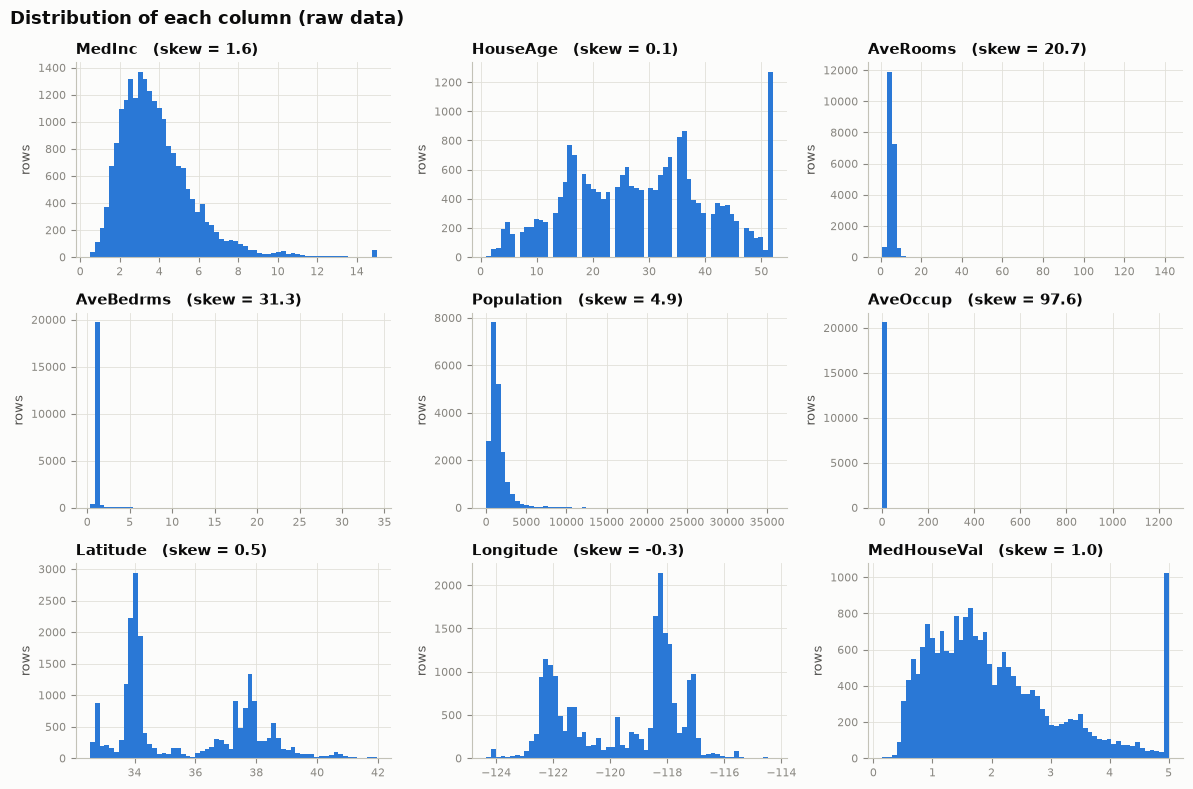

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(12, 8))
for ax, col in zip(axes.flat, df_raw.columns):
    ax.hist(df_raw[col], bins=60, color=BLUE)
    ax.set_title(f"{col}   (skew = {df_raw[col].skew():.1f})")
    ax.set_ylabel("rows")
fig.suptitle("Distribution of each column (raw data)", fontsize=13, fontweight="bold", x=0.01, ha="left")
plt.tight_layout()
plt.show()

**O que os histogramas nos dizem:**

- `MedInc`, `Population` e `MedHouseVal` têm uma **cauda longa à direita** (skew de 1,0 a 4,9). Isso é típico de dinheiro e de contagens: muitos valores pequenos e alguns muito grandes.
- `AveRooms`, `AveBedrms` e `AveOccup` são **extremamente** assimétricas (skew de 21 a 98). Quase todas as linhas caem numa única barra perto de zero, e um punhado de valores enormes estica o eixo x. Essas três colunas merecem um olhar mais atento.
- `HouseAge` não tem cauda, mas tem um **pico alto em 52**. `MedHouseVal` tem o mesmo tipo de pico em 5,0, e `MedInc` um pico pequeno em 15.
- `Latitude` e `Longitude` têm **dois picos**: a região de Los Angeles (cerca de 34°N) e a San Francisco Bay Area (cerca de 38°N). Isso é geografia, não outliers.

## 1.2 Método 1 — Boxplot e a regra do IQR

**Como funciona:**

- `Q1` = o valor abaixo do qual ficam 25% das linhas. `Q3` = o valor abaixo do qual ficam 75%.
- `IQR = Q3 − Q1` é a largura da "metade do meio" dos dados.
- Um valor é outlier se cair fora dos **limites** (as "cercas"):
  - limite inferior = `Q1 − 1.5 × IQR`
  - limite superior = `Q3 + 1.5 × IQR`
- Um boxplot desenha exatamente isso: a caixa vai de Q1 a Q3, os bigodes param nos limites, e os pontos são os outliers.

**Por que IQR e não o z-score?** O z-score usa a média e o desvio padrão. Os dois são puxados pelos próprios outliers, e ele supõe uma curva em forma de sino. Os quartis não são puxados por valores extremos, então a regra do IQR é mais **robusta** para dados assimétricos como os nossos.

In [7]:
def iqr_bounds(series, k=1.5):
    """Return the (lower, upper) fences of the IQR rule for one column."""
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


rows = []
for col in df_raw.columns:
    low, high = iqr_bounds(df_raw[col])
    rows.append({
        "column": col,
        "lower_fence": low,
        "upper_fence": high,
        "n_below": (df_raw[col] < low).sum(),
        "n_above": (df_raw[col] > high).sum(),
    })
iqr_table = pd.DataFrame(rows).set_index("column")
iqr_table["pct_outliers"] = 100 * (iqr_table["n_below"] + iqr_table["n_above"]) / len(df_raw)
iqr_table

,lower_fence,upper_fence,n_below,n_above,pct_outliers
column,,,,,
MedInc,-0.706,8.013,0,681,3.299
HouseAge,-10.500,65.500,0,0,0.000
AveRooms,2.023,8.470,45,466,2.476
AveBedrms,0.866,1.240,188,1236,6.899
Population,-620.000,"3,132.000",0,1196,5.795
AveOccup,1.151,4.561,7,704,3.445
Latitude,28.260,43.380,0,0,0.000
Longitude,-127.485,-112.325,0,0,0.000
MedHouseVal,-0.981,4.824,0,1071,5.189


In [8]:
# One True/False column per feature: True = outlier by the IQR rule
iqr_flags = pd.DataFrame({
    col: ~df_raw[col].between(*iqr_bounds(df_raw[col])) for col in df_raw.columns
})
iqr_any = iqr_flags.any(axis=1)
print(f"Rows flagged in at least one column: {iqr_any.sum():,} ({iqr_any.mean():.1%} of all rows)")

Rows flagged in at least one column: 4,328 (21.0% of all rows)


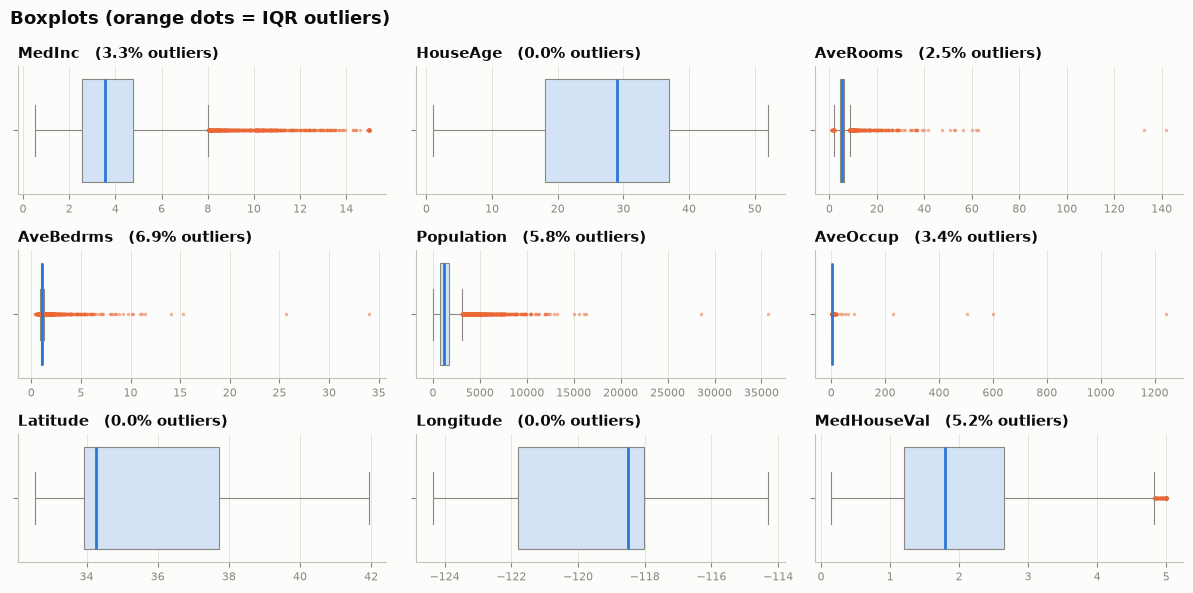

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(12, 6))
for ax, col in zip(axes.flat, df_raw.columns):
    sns.boxplot(x=df_raw[col], ax=ax, color="#cde2fb", linecolor=GRAY, linewidth=0.8,
                fliersize=2.5, flierprops={"markerfacecolor": ORANGE, "markeredgecolor": "none", "alpha": 0.5},
                medianprops={"color": BLUE, "linewidth": 2})
    ax.set_title(f"{col}   ({iqr_table.loc[col, 'pct_outliers']:.1f}% outliers)")
    ax.set_xlabel("")
fig.suptitle("Boxplots (orange dots = IQR outliers)", fontsize=13, fontweight="bold", x=0.01, ha="left")
plt.tight_layout()
plt.show()

**O que a regra do IQR nos diz:**

- Ela marca **4.328 linhas (21%)**. Remover todas jogaria fora 1 em cada 5 vizinhanças. Então a regra do IQR é um **alarme**, não uma decisão.
- `HouseAge`, `Latitude` e `Longitude` não têm nenhum outlier.
- `AveBedrms` tem mais outliers (6,9%). Mas olhe os limites: **0,87 a 1,24**. A metade do meio dos dados é muito estreita (IQR ≈ 0,09 quarto). Então um block group com 1,3 quarto por domicílio, que é perfeitamente normal, é marcado.
  - **Lição:** numa coluna muito concentrada, a regra do IQR é rígida demais.
- `MedHouseVal`: todos os 1.071 outliers estão acima de US\$ 482 mil. A maioria fica no teto de US\$ 500 mil (próxima seção).
- Nos boxplots de `AveRooms`, `AveBedrms` e `AveOccup`, a caixa fica espremida numa linha fina. Alguns valores gigantescos (como 1.243 pessoas por domicílio) esticam o eixo inteiro.

## 1.3 Um tipo especial de outlier: valores de "teto"

- Alguns datasets gravam todo valor acima de um limite **como o próprio limite**. Isso se chama **capping** (ou *censura*).
- Um jeito simples de encontrar: contar quantas linhas têm **exatamente** o valor máximo. Numa coluna normal, só uma ou duas linhas chegam ao máximo.

In [10]:
ceiling = pd.DataFrame({
    "max_value": df_raw.max(),
    "rows_at_max": (df_raw == df_raw.max()).sum(),
})
ceiling["pct_at_max"] = 100 * ceiling["rows_at_max"] / len(df_raw)
ceiling.sort_values("rows_at_max", ascending=False)

,max_value,rows_at_max,pct_at_max
HouseAge,52.000,1273,6.168
MedHouseVal,5.000,965,4.675
MedInc,15.000,49,0.237
Latitude,41.950,2,0.010
AveRooms,141.909,1,0.005
Population,"35,682.000",1,0.005
AveBedrms,34.067,1,0.005
AveOccup,"1,243.333",1,0.005
Longitude,-114.310,1,0.005


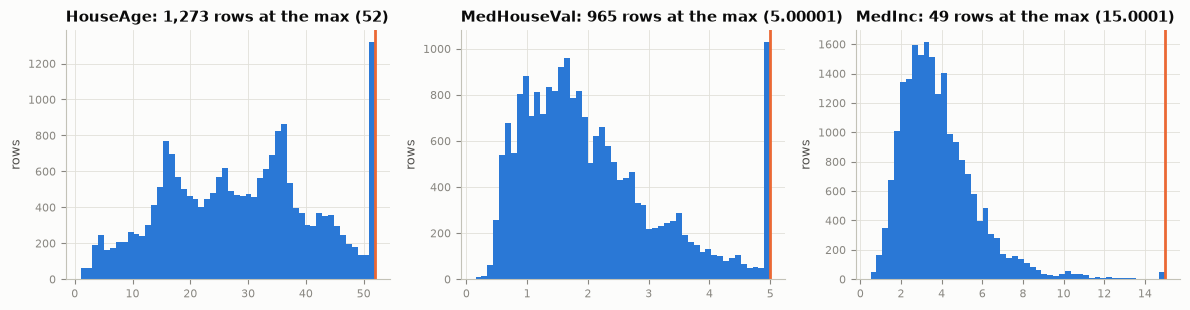

In [11]:
capped_cols = ["HouseAge", "MedHouseVal", "MedInc"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, col in zip(axes, capped_cols):
    ax.hist(df_raw[col], bins=50, color=BLUE)
    n_at_max = ceiling.loc[col, "rows_at_max"]
    ax.axvline(df_raw[col].max(), color=ORANGE, linewidth=2)
    ax.set_title(f"{col}: {n_at_max:,} rows at the max ({df_raw[col].max():g})")
    ax.set_ylabel("rows")
plt.tight_layout()
plt.show()

**Três colunas têm teto:**

- `HouseAge`: 1.273 linhas (6,2%) valem exatamente **52**. Os dados gravam "52 anos ou mais" como 52.
- `MedHouseVal`: 965 linhas (4,7%) valem exatamente **5,00001**, o que significa "US\$ 500.000 ou mais".
- `MedInc`: 49 linhas valem exatamente **15,0001**, o que significa "US\$ 150.000 ou mais".

**O que isso significa:**

- Esses valores **não são erros**. O valor real é *no mínimo* o teto; só não sabemos quanto a mais.
- Para clustering, o efeito é pequeno. Essas linhas ficam todas na borda da distribuição, então vão simplesmente cair no grupo "mais antigo" ou "mais caro". Só precisamos lembrar que "mais caro" na verdade significa "US\$ 500 mil ou mais".
- Repare que a regra do IQR marca o teto de US\$ 500 mil, mas **não enxerga** o teto de `HouseAge`: 52 está dentro da faixa normal. Tetos se escondem dentro dos dados. Você os encontra procurando picos, não com uma regra de outliers.

## 1.4 A regra do IQR em escala log

- A regra do IQR funciona melhor em dados **simétricos**.
- Numa coluna assimétrica, a cauda longa à direita é *normal*, mas a regra a marca mesmo assim.
- Uma **transformação log** comprime a cauda longa. Depois aplicamos a mesma regra de novo.
- Se um valor **continua** sendo outlier na escala log, ele é de fato extremo.
- Só fazemos isso nas colunas assimétricas (skewness acima de 0,5). Um log numa coluna simétrica como `HouseAge` criaria outliers falsos no lado esquerdo.

In [12]:
skewed_cols = [col for col in df_raw.columns if df_raw[col].skew() > 0.5]
print("Skewed columns:", skewed_cols)

log_compare = pd.DataFrame(index=skewed_cols)
log_compare["outliers_raw_scale"] = [iqr_flags[col].sum() for col in skewed_cols]
log_compare["outliers_log_scale"] = [
    (~np.log(df_raw[col]).between(*iqr_bounds(np.log(df_raw[col])))).sum() for col in skewed_cols
]
log_compare["change_pct"] = 100 * (log_compare["outliers_log_scale"] / log_compare["outliers_raw_scale"] - 1)
log_compare

Skewed columns: ['MedInc', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'MedHouseVal']


,outliers_raw_scale,outliers_log_scale,change_pct
MedInc,681,277,-59.325
AveRooms,511,571,11.742
AveBedrms,1424,1379,-3.160
Population,1196,847,-29.181
AveOccup,711,510,-28.270
MedHouseVal,1071,26,-97.572


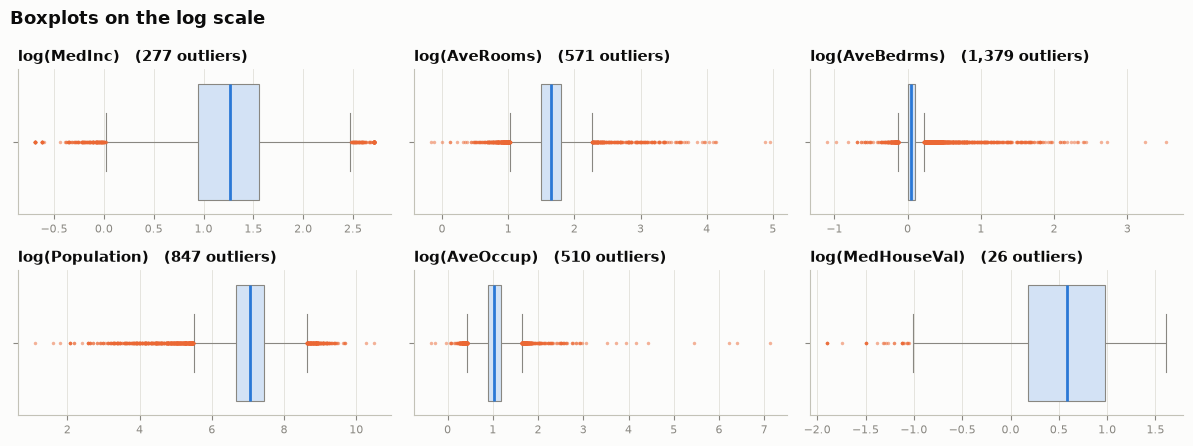

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(12, 4.5))
for ax, col in zip(axes.flat, skewed_cols):
    sns.boxplot(x=np.log(df_raw[col]), ax=ax, color="#cde2fb", linecolor=GRAY, linewidth=0.8,
                fliersize=2.5, flierprops={"markerfacecolor": ORANGE, "markeredgecolor": "none", "alpha": 0.5},
                medianprops={"color": BLUE, "linewidth": 2})
    ax.set_title(f"log({col})   ({log_compare.loc[col, 'outliers_log_scale']:,} outliers)")
    ax.set_xlabel("")
fig.suptitle("Boxplots on the log scale", fontsize=13, fontweight="bold", x=0.01, ha="left")
plt.tight_layout()
plt.show()

**A escala log muda bastante o quadro:**

- `MedHouseVal`: de 1.071 outliers para **26** (−98%). Os valores de US\$ 500 mil eram só o topo natural de uma distribuição assimétrica.
- `MedInc` (−59%), `Population` (−29%) e `AveOccup` (−28%) também caem bastante.
- Agora aparecem outliers dos **dois lados**. Por exemplo, `log(Population)` mostra, à esquerda, muitos block groups com **pouquíssimas pessoas**. Eles eram invisíveis na escala original.
- `AveRooms` e `AveBedrms` continuam com muitos outliers mesmo depois do log. As caudas delas são muito mais longas que uma assimetria "normal". Essas são as linhas a investigar.

**Lição:** em dados assimétricos, uma transformação log separa a **cauda longa** (normal) do **realmente extremo** (que merece atenção). Isso vai guiar a etapa 2.

## 1.5 Método 2 — Isolation Forest

**A ideia, em palavras simples:**

- O algoritmo constrói muitas árvores aleatórias. Cada árvore vai cortando os dados com divisões aleatórias (coluna aleatória, valor aleatório).
- Um ponto **normal** fica no meio da multidão. Ele precisa de **muitos** cortes para ficar isolado.
- Um ponto **incomum** fica sozinho. Ele fica isolado depois de **poucos** cortes.
- O número médio de cortes vira um **anomaly score**. Menos cortes significa uma linha mais incomum.

**Por que ele complementa a regra do IQR:**

- Ele olha **todas as colunas juntas**. Pode pegar linhas que são normais em cada coluna isolada, mas estranhas como combinação.
- Ele **não precisa de scaling** e **não supõe uma curva em sino**. Cada corte usa uma única coluna, então as unidades não importam.

**A única decisão que precisamos tomar: `contamination`.** É a fração de linhas que *esperamos* que sejam anomalias. Não existe valor "correto"; é uma suposição de negócio. Começamos olhando os scores.

In [14]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(n_estimators=300, contamination=0.01, random_state=RANDOM_STATE, n_jobs=-1)
iso.fit(df_raw)

anomaly_score = -iso.score_samples(df_raw)   # between 0 and 1: higher = more unusual
if_flag = pd.Series(iso.predict(df_raw) == -1, index=df_raw.index, name="IF anomaly")
threshold = -iso.offset_                     # the score above which a row is flagged

print(f"Rows flagged with contamination = 1%: {if_flag.sum():,}")
print(f"Rows flagged by the default rule (score > 0.5): {(anomaly_score > 0.5).sum():,} "
      f"({(anomaly_score > 0.5).mean():.1%})")

Rows flagged with contamination = 1%: 207
Rows flagged by the default rule (score > 0.5): 1,808 (8.8%)


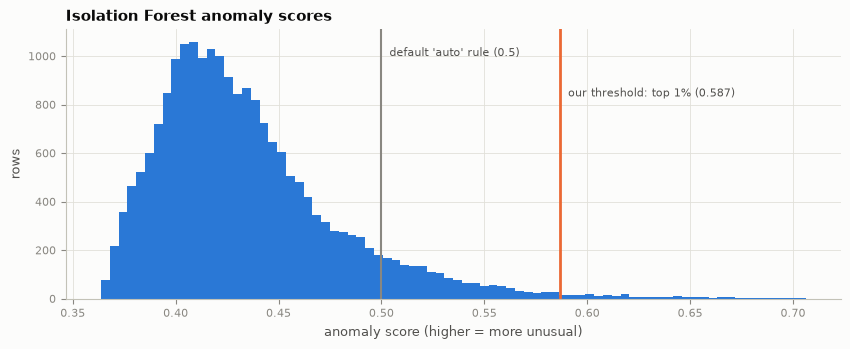

In [15]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.hist(anomaly_score, bins=80, color=BLUE)
ax.axvline(0.5, color=GRAY, linewidth=1.5)
ax.axvline(threshold, color=ORANGE, linewidth=2)
ax.text(0.5, ax.get_ylim()[1] * 0.9, "  default 'auto' rule (0.5)", color="#52514e", fontsize=8)
ax.text(threshold, ax.get_ylim()[1] * 0.75, f"  our threshold: top 1% ({threshold:.3f})", color="#52514e", fontsize=8)
ax.set_title("Isolation Forest anomaly scores")
ax.set_xlabel("anomaly score (higher = more unusual)")
ax.set_ylabel("rows")
plt.show()

**Lendo o histograma dos scores:**

- A maioria das linhas tem score em torno de 0,40–0,45: são "normais".
- A cauda direita é longa e fina. Um pequeno grupo de linhas é muito mais fácil de isolar que o resto.
- A regra padrão (`contamination="auto"`, score > 0,5) marcaria **1.808 linhas (8,8%)**. Esse valor vem do artigo original; não é uma regra para os *nossos* dados.
- Escolhemos **1% (207 linhas)**. Depois de um score de ~0,59, o histograma fica quase plano: essas linhas estão claramente isoladas. É uma suposição, e podemos mudá-la depois.

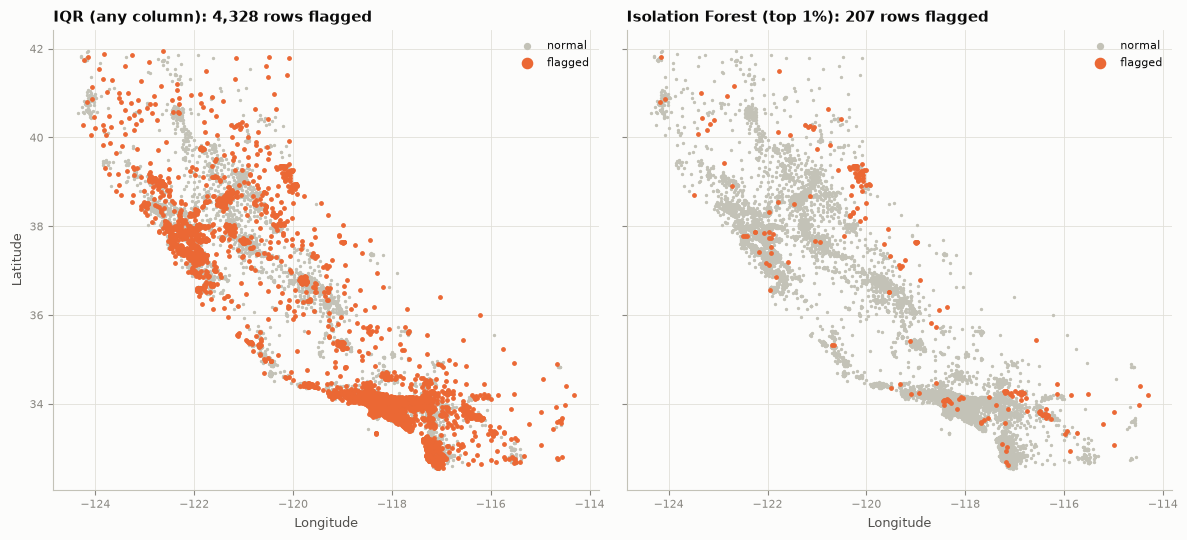

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True, sharey=True)
for ax, flag, name in [(axes[0], iqr_any, "IQR (any column)"), (axes[1], if_flag, "Isolation Forest (top 1%)")]:
    ax.scatter(df_raw.loc[~flag, "Longitude"], df_raw.loc[~flag, "Latitude"], s=2, color=LIGHT_GRAY, label="normal")
    ax.scatter(df_raw.loc[flag, "Longitude"], df_raw.loc[flag, "Latitude"], s=6, color=ORANGE, label="flagged")
    ax.set_title(f"{name}: {flag.sum():,} rows flagged")
    ax.set_xlabel("Longitude")
    ax.legend(loc="upper right", markerscale=3)
axes[0].set_ylabel("Latitude")
plt.tight_layout()
plt.show()

In [17]:
profile = pd.DataFrame({
    "median (normal rows)": df_raw[~if_flag].median(),
    "median (IF anomalies)": df_raw[if_flag].median(),
})
profile["ratio"] = profile["median (IF anomalies)"] / profile["median (normal rows)"]
profile

,median (normal rows),median (IF anomalies),ratio
MedInc,3.534,3.631,1.027
HouseAge,29.000,17.000,0.586
AveRooms,5.217,15.511,2.973
AveBedrms,1.048,3.013,2.874
Population,"1,171.000",337.000,0.288
AveOccup,2.821,2.579,0.914
Latitude,34.250,37.250,1.088
Longitude,-118.490,-119.570,1.009
MedHouseVal,1.800,1.545,0.858


**Os dois mapas contam histórias diferentes:**

- O IQR marca linhas **em todo lugar**, principalmente nas grandes cidades, onde populações grandes e casas caras são comuns.
- O Isolation Forest marca **poucas** linhas, a maioria **longe das cidades**: as montanhas de Sierra Nevada (perto do Lake Tahoe), os desertos do sudeste e alguns outros pontos.

**O perfil das anomalias do Isolation Forest (comparado com as linhas normais):**

- cerca de **3× mais cômodos e quartos** por domicílio;
- cerca de **3,5× menos pessoas**;
- casas **mais novas** (17 vs 29 anos).

Isso parece **casas de veraneio**: muitos cômodos, poucos moradores permanentes. A documentação do scikit-learn nos avisou exatamente sobre isso.

## 1.6 Comparando os dois métodos

In [18]:
pd.crosstab(iqr_any.rename("IQR outlier (any column)"), if_flag, margins=True)

IF anomaly,False,True,All
IQR outlier (any column),,,
False,16312,0,16312
True,4121,207,4328
All,20433,207,20640


In [19]:
# How many columns are flagged by IQR, for the rows that Isolation Forest flags?
n_iqr_cols = iqr_flags.sum(axis=1)
print("Number of IQR-flagged columns among the Isolation Forest anomalies:")
print(n_iqr_cols[if_flag].value_counts().sort_index().to_string())

print("\nIQR flags among the rows flagged ONLY by IQR (share of those rows):")
only_iqr = iqr_any & ~if_flag
print((iqr_flags[only_iqr].mean() * 100).round(1).sort_values(ascending=False).to_string())

Number of IQR-flagged columns among the Isolation Forest anomalies:
1      6
2    158
3     32
4      9
5      2

IQR flags among the rows flagged ONLY by IQR (share of those rows):
AveBedrms     30.300
Population    28.500
MedHouseVal   25.300
AveOccup      16.400
MedInc        15.700
AveRooms       8.200
HouseAge       0.000
Latitude       0.000
Longitude      0.000


**Como os dois métodos se relacionam:**

- **Toda** linha marcada pelo Isolation Forest também é marcada pelo IQR (a célula "IQR = False, IF = True" é 0).
- O Isolation Forest é mais seletivo: 201 das suas 207 anomalias são extremas em **2 ou mais colunas ao mesmo tempo**. Ele procura linhas que são estranhas *de várias formas*.
- As 4.121 linhas marcadas **só** pelo IQR são, na maioria, casos moderados de uma coluna só: `AveBedrms` um pouco acima de 1,24 (30%), `Population` alta (28%) e o teto de US\$ 500 mil em `MedHouseVal` (25%).

**Conclusão prática:**

- O IQR é uma **rede larga**: pega tudo que é incomum, com muitos alarmes falsos em dados assimétricos.
- O Isolation Forest é uma **rede estreita**: pega as anomalias mais fortes, de várias colunas.
- Nenhum dos dois diz **por que** uma linha é estranha. Esse é o assunto da próxima seção.

## 1.7 Quem são os outliers? Dando um significado de negócio

Os detectores dizem **quais** linhas são estranhas. Eles não dizem **por quê**. É aqui que entra o conhecimento do domínio.

Primeiro reconstruímos uma coluna escondida: o **número de domicílios** em cada block group.

- `AveOccup` = pessoas por domicílio, então `households = Population / AveOccup`.
- Uma média por domicílio calculada sobre pouquíssimos domicílios não é confiável.

In [20]:
households = (df_raw["Population"] / df_raw["AveOccup"]).round()
households.describe()

count   20,640.000
mean       499.540
std        382.330
min          1.000
25%        280.000
50%        409.000
75%        605.000
max      6,082.000
dtype: float64

Agora olhamos as linhas mais extremas das colunas que chamaram nossa atenção.

In [21]:
show_cols = ["MedInc", "HouseAge", "AveRooms", "AveBedrms", "Population", "AveOccup",
             "Latitude", "Longitude", "MedHouseVal"]
print("Top 8 rows by AveOccup (people per household)")
display(df_raw.assign(households=households).nlargest(8, "AveOccup")[show_cols + ["households"]])

print("Top 8 rows by AveRooms (rooms per household)")
display(df_raw.assign(households=households).nlargest(8, "AveRooms")[show_cols + ["households"]])

print("Top 5 rows by Population")
display(df_raw.assign(households=households).nlargest(5, "Population")[show_cols + ["households"]])

Top 8 rows by AveOccup (people per household)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,households
19006,10.226,45.000,3.167,0.833,"7,460.000","1,243.333",38.320,-121.980,1.375,6.000
3364,5.518,36.000,5.143,1.143,"4,198.000",599.714,40.410,-120.510,0.675,7.000
16669,4.264,46.000,9.077,1.308,"6,532.000",502.462,35.320,-120.700,3.500,13.000
13034,6.136,52.000,8.276,1.517,"6,675.000",230.172,38.690,-121.150,2.250,29.000
9172,4.239,5.000,5.124,0.933,"8,733.000",83.171,34.470,-118.590,1.546,105.000
12104,1.625,8.000,7.600,0.950,"1,275.000",63.750,33.970,-117.330,1.625,20.000
16420,5.748,26.000,5.367,0.900,"1,542.000",51.400,37.890,-121.290,1.625,30.000
8874,9.337,52.000,7.286,1.214,"1,154.000",41.214,34.060,-118.450,5.000,28.000


Top 8 rows by AveRooms (rooms per household)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,households
1914,1.875,33.000,141.909,25.636,30.000,2.727,38.910,-120.100,5.000,11.000
1979,4.625,34.000,132.533,34.067,36.000,2.400,38.800,-120.080,1.625,15.000
12447,1.615,17.000,62.422,14.111,83.000,1.844,33.970,-114.490,0.875,45.000
1913,4.071,19.000,61.812,11.000,112.000,2.333,39.010,-120.060,4.375,48.000
11862,2.625,25.000,59.875,15.312,28.000,1.750,40.270,-121.250,0.675,16.000
1912,4.975,16.000,56.269,10.154,54.000,2.077,39.010,-120.160,2.063,26.000
9676,3.243,14.000,52.848,11.411,265.000,2.366,37.640,-119.020,2.214,112.000
11707,1.191,22.000,52.690,8.857,98.000,2.333,39.150,-120.060,1.700,42.000


Top 5 rows by Population


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,households
15360,2.573,14.000,5.270,1.010,"35,682.000",7.482,33.350,-117.420,1.344,"4,769.000"
9880,2.309,11.000,5.365,1.060,"28,566.000",4.697,36.640,-121.790,1.188,"6,082.000"
13139,4.952,3.000,7.339,1.159,"16,305.000",3.043,38.430,-121.440,1.537,"5,358.000"
10309,7.495,4.000,7.311,1.054,"16,122.000",3.107,33.890,-117.740,3.663,"5,189.000"
6057,6.019,8.000,6.347,1.048,"15,507.000",3.071,34.030,-117.780,2.539,"5,050.000"


Procuramos essas coordenadas num mapa (qualquer mapa online serve). Elas apontam para **lugares reais**:

| Linha | O que os dados dizem | Localização (lat, lon) | O que existe lá |
|---|---|---|---|
| 19006 | 7.460 pessoas em 6 domicílios | 38.32, −121.98 | Vacaville: duas prisões estaduais |
| 3364 | 4.198 pessoas em 7 domicílios | 40.41, −120.51 | Susanville: duas prisões estaduais |
| 16669 | 6.532 pessoas em 13 domicílios | 35.32, −120.70 | California Men's Colony, uma prisão estadual perto de San Luis Obispo |
| 13034 | 6.675 pessoas em 29 domicílios | 38.69, −121.15 | Folsom State Prison |
| 12104, 8874 | ~1.200 pessoas em 20–28 domicílios | 33.97, −117.33 e 34.06, −118.45 | UC Riverside e UCLA: alojamentos estudantis |
| 1914, 1979, 1913, 1912 | 56 a 142 cômodos por domicílio | por volta de 38.9, −120.1 | Lake Tahoe: casas de veraneio |
| 9676 | 53 cômodos por domicílio | 37.64, −119.02 | Mammoth Lakes: uma estação de esqui |
| 15360 | 35.682 pessoas, 7,5 por domicílio | 33.35, −117.42 | Camp Pendleton, uma base do Corpo de Fuzileiros Navais |
| 9880 | 28.566 pessoas | 36.64, −121.79 | Fort Ord, uma base do Exército em 1990 |

**Então cada extremo tem uma causa clara:**

- **`AveOccup` enorme = domicílios coletivos (group quarters).** O Censo conta as pessoas que vivem em prisões, alojamentos estudantis, quartéis e hospitais na *população*, mas não como *domicílios* particulares. Por isso "pessoas por domicílio" explode.
- **`AveRooms` enorme = casas de veraneio.** Os cômodos são contados em todas as casas, mas os domicílios só nas casas ocupadas. Um resort cheio de casas de veraneio vazias tem muitos cômodos e pouquíssimos domicílios.
- **`Population` enorme = bases militares e subúrbios novos.** Alguns block groups são simplesmente muito grandes, como os novos loteamentos em Elk Grove e Yorba Linda (casas com apenas 3–4 anos).

In [22]:
# Simple, explainable rules for each kind of outlier we found
outlier_types = pd.DataFrame(index=df_raw.index)
outlier_types["group_quarters"] = df_raw["AveOccup"] > 10                 # not private households
outlier_types["tiny_block"] = households < 10                             # averages over < 10 households
outlier_types["impossible_value"] = df_raw["AveOccup"] < 1                # fewer people than households
outlier_types["vacation_homes"] = (df_raw["AveRooms"] > 10) & ~outlier_types["tiny_block"]
outlier_types["very_large_block"] = df_raw["Population"] > 10_000
outlier_types["capped_value"] = (
    (df_raw["HouseAge"] == df_raw["HouseAge"].max())
    | (df_raw["MedHouseVal"] == df_raw["MedHouseVal"].max())
    | (df_raw["MedInc"] == df_raw["MedInc"].max())
)

summary = pd.DataFrame({
    "rows": outlier_types.sum(),
    "pct_of_data": 100 * outlier_types.mean(),
    "pct_caught_by_IQR": [100 * iqr_any[outlier_types[c]].mean() for c in outlier_types],
    "pct_caught_by_IF": [100 * if_flag[outlier_types[c]].mean() for c in outlier_types],
})
summary

,rows,pct_of_data,pct_caught_by_IQR,pct_caught_by_IF
group_quarters,37,0.179,100.000,43.243
tiny_block,51,0.247,74.510,25.490
impossible_value,3,0.015,100.000,33.333
vacation_homes,218,1.056,100.000,62.844
very_large_block,23,0.111,100.000,8.696
capped_value,2070,10.029,53.816,1.884


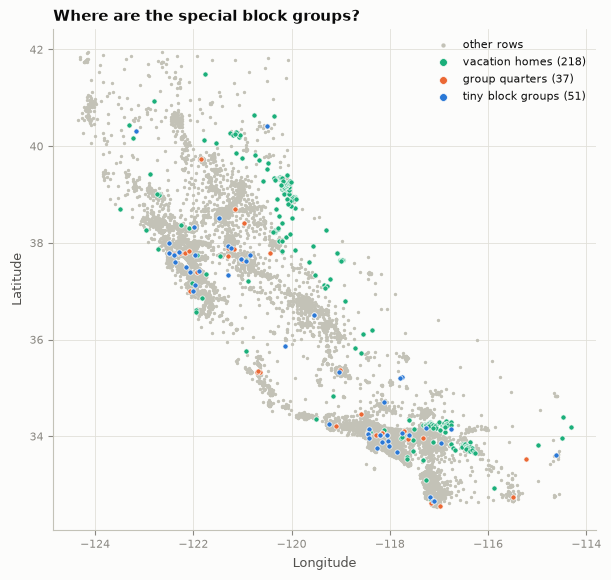

In [23]:
fig, ax = plt.subplots(figsize=(7, 6.5))
ax.scatter(df_raw["Longitude"], df_raw["Latitude"], s=2, color=LIGHT_GRAY, label="other rows")
for col, color, label in [("vacation_homes", AQUA, "vacation homes"),
                          ("group_quarters", ORANGE, "group quarters"),
                          ("tiny_block", BLUE, "tiny block groups")]:
    sel = outlier_types[col]
    ax.scatter(df_raw.loc[sel, "Longitude"], df_raw.loc[sel, "Latitude"], s=14, color=color,
               edgecolor="#fcfcfb", linewidth=0.5, label=f"{label} ({sel.sum()})")
ax.set_title("Where are the special block groups?")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(loc="upper right", markerscale=1.5)
plt.show()

In [24]:
# Which group quarters does Isolation Forest catch? (split by how extreme AveOccup is)
gq = outlier_types["group_quarters"]
pd.crosstab(pd.cut(df_raw.loc[gq, "AveOccup"], bins=[10, 20, 50, 1300]), if_flag[gq])

IF anomaly,False,True
AveOccup,,
"(10, 20]",17,10
"(20, 50]",2,1
"(50, 1300]",2,5


**O que as regras e o mapa mostram:**

- **Domicílios coletivos (37 linhas):** o IQR pega todos, o Isolation Forest só 43% (veja a tabela acima). Perto de um valor de 1.243, um valor de 15 pessoas por domicílio não parece especial para cortes aleatórios espalhados pela faixa de 0 a 1.243.
- **Block groups minúsculos (51 linhas):** o Isolation Forest pega só 25%. Um block group minúsculo com médias comuns parece perfeitamente normal para *qualquer* detector. O problema (uma média sobre 1 a 9 domicílios) só é visível porque **sabemos como os dados foram construídos**.
- **Valores impossíveis (3 linhas):** menos pessoas que domicílios. É um erro nos dados.
- **Casas de veraneio (218 linhas, 1%):** o grupo de que o Isolation Forest mais gosta (63%). No mapa, elas ficam nas montanhas (Lake Tahoe, Big Bear) e nos resorts do deserto (região de Palm Springs). São **vizinhanças reais com um perfil próprio**.
- **Block groups muito grandes (23 linhas):** lugares reais, só que grandes.
- **Valores com teto (2.070 linhas, 10%):** não são anomalias no sentido multivariado (o Isolation Forest marca só 2% deles).

## Etapa 1 — Conclusão

Encontramos **vários tipos** de outliers. Cada tipo precisa da sua própria decisão:

| Tipo de outlier | Linhas | Real ou erro? | Plano para a etapa 2 |
|---|---|---|---|
| Domicílios coletivos (`AveOccup` > 10) | 37 | Real, mas **não são domicílios** | Remover do clustering de vizinhanças |
| Block groups minúsculos (< 10 domicílios) | 51 | Real, mas as médias são **ruído** | Remover |
| Valores impossíveis (`AveOccup` < 1) | 3 | **Erro nos dados** | Remover |
| Casas de veraneio (`AveRooms` > 10) | 218 | Real, um grupo **distinto** | Manter; reduzir sua influência (log + capping) |
| Block groups muito grandes | 23 | Real | Manter; transformação log |
| Caudas longas à direita (renda, população, valor) | muitas | Assimetria natural | Transformação log |
| Valores de teto (52 anos, US\$ 500 mil, US\$ 150 mil) | 2.070 | Real, mas **censurado** | Manter; marcar com flags |
| "Outliers" de `AveBedrms` entre 1,24 e ~2 | muitas | Artefato de um IQR estreito | Nada de especial |

**Principais lições:**

- **Nunca remova todos os outliers do IQR.** Aqui isso seria 21% dos dados, na maioria linhas normais de uma cauda longa.
- **Use vários métodos.** O IQR é uma rede larga; o Isolation Forest, uma rede estreita. Juntos, eles dão uma boa lista curta.
- **O conhecimento do domínio decide.** Os detectores encontram linhas *estranhas*; só o contexto nos diz *o que elas são*. Alguns problemas (como os block groups minúsculos) são invisíveis para os detectores: você só os encontra se entende como os dados foram construídos.

---
# Etapa 2 — Tratamento de outliers

Na etapa 1 encontramos **tipos diferentes** de outliers. Então não usamos uma regra só para tudo. Escolhemos a ferramenta certa para cada tipo:

| Ferramenta | O que faz | Quando usar |
|---|---|---|
| **Remover a linha** | Tira a linha do dataset | Só com um motivo forte: um erro, ou uma linha que não pertence à população que estudamos |
| **Transformação log** | Comprime valores grandes, mantém a ordem | Caudas longas à direita (dinheiro, contagens). Todos os valores precisam ser > 0 |
| **Winsorização (clipping)** | Substitui os valores além de um limite pelo próprio limite | Valores reais, mas extremos, que puxariam demais os clusters |
| **Flag** | Adiciona uma marcação True/False à linha | Coisas que queremos lembrar, como os valores com teto |
| **Não fazer nada** | — | Colunas que já estão boas |

**Importante:** nunca sobrescrevemos o `df_raw`. As linhas removidas ficam guardadas à parte, e as transformações ficam numa função que podemos aplicar de novo depois.

## 2.1 Remover as linhas que não pertencem aos dados

Removemos três grupos (da etapa 1):

- **Domicílios coletivos** (`AveOccup` > 10): prisões, alojamentos estudantis, quartéis. O "pessoas por domicílio" deles não descreve domicílios de jeito nenhum.
- **Block groups minúsculos** (menos de 10 domicílios): uma média sobre 1 a 9 domicílios é ruído, não um perfil de vizinhança.
- **Valores impossíveis** (`AveOccup` < 1): menos pessoas que domicílios. Um erro nos dados.

In [25]:
removal_reason = pd.Series("", index=df_raw.index)
removal_reason[outlier_types["group_quarters"]] = "group quarters"
removal_reason[outlier_types["tiny_block"]] = "tiny block group"
removal_reason[outlier_types["impossible_value"]] = "impossible value"

to_remove = removal_reason != ""
df_removed = df_raw[to_remove].assign(reason=removal_reason[to_remove])   # kept aside, not lost
df_clean = df_raw[~to_remove].copy()

print(f"Rows removed: {to_remove.sum()} ({to_remove.mean():.2%} of the data)")
print(f"Rows kept:    {len(df_clean):,}")
print()
print(df_removed["reason"].value_counts().to_string())
# Note: a few rows match two rules (e.g. a prison with only 6 households); each row gets one label.

Rows removed: 85 (0.41% of the data)
Rows kept:    20,555

reason
tiny block group    50
group quarters      32
impossible value     3


**Por que remover é a decisão certa aqui (e não uma perda):**

- **Elas não são o que queremos agrupar.** Nosso objetivo é agrupar *vizinhanças residenciais*. Uma prisão não é um tipo de vizinhança.
- **Os números delas estão quebrados, não apenas extremos.** 1.243 pessoas por domicílio não é uma "família grande"; é outro tipo de lugar.
- **Elas são muito poucas.** 85 linhas de 20.640 (0,4%). Mantê-las poderia nos custar um cluster inteiro, ou puxar os centros dos clusters para longe.
- **Não perdemos essas linhas.** Elas ficam no `df_removed`. Num projeto real, nós as reportaríamos como um grupo "institucional" separado.

> Repare no que **não** removemos: casas de veraneio, block groups muito grandes e valores com teto. São vizinhanças reais. Nós as mantemos e reduzimos sua influência.

## 2.2 Escolher uma transformação para cada coluna

Uma transformação muda o **formato** de uma distribuição. Comparamos quatro opções usando a skewness (0 = simétrica):

- **raw**: sem mudança;
- **log**: `log(x)`. Efeito forte. Fácil de explicar: passos iguais na escala log são *razões* iguais (de US\$ 20 mil para US\$ 40 mil é o mesmo passo que de US\$ 50 mil para US\$ 100 mil);
- **raiz quadrada**: `√x`. Um efeito mais suave;
- **Yeo-Johnson**: encontra automaticamente a "melhor" potência (`PowerTransformer` no scikit-learn). Poderoso, mas mais difícil de explicar.

In [26]:
from sklearn.preprocessing import PowerTransformer

shape_cols = ["MedInc", "HouseAge", "AveRooms", "AveBedrms", "Population", "AveOccup", "MedHouseVal"]
skew_table = pd.DataFrame(index=shape_cols)
skew_table["raw"] = [df_clean[c].skew() for c in shape_cols]
skew_table["log"] = [np.log(df_clean[c]).skew() for c in shape_cols]
skew_table["sqrt"] = [np.sqrt(df_clean[c]).skew() for c in shape_cols]
skew_table["yeo_johnson"] = [
    pd.Series(PowerTransformer().fit_transform(df_clean[[c]]).ravel()).skew() for c in shape_cols
]
skew_table.round(2)

,raw,log,sqrt,yeo_johnson
MedInc,1.630,-0.120,0.690,-0.000
HouseAge,0.060,-1.280,-0.470,-0.110
AveRooms,21.040,0.880,4.910,-0.170
AveBedrms,31.680,6.620,13.010,-0.910
Population,4.980,-0.760,1.270,0.080
AveOccup,1.360,0.130,0.670,-0.020
MedHouseVal,0.980,-0.170,0.440,0.030


In [27]:
# The "largest z-score" shows how far the most extreme row sits from the mean,
# counted in standard deviations. For clustering we want this to be small.
def max_abs_z(series):
    return ((series - series.mean()) / series.std()).abs().max()


z_table = pd.DataFrame(index=shape_cols)
z_table["max_z_raw"] = [max_abs_z(df_clean[c]) for c in shape_cols]
z_table["max_z_log"] = [max_abs_z(np.log(df_clean[c])) for c in shape_cols]
z_table["max_z_yeo_johnson"] = [
    max_abs_z(pd.Series(PowerTransformer().fit_transform(df_clean[[c]]).ravel())) for c in shape_cols
]
z_table.round(1)

,max_z_raw,max_z_log,max_z_yeo_johnson
MedInc,5.900,4.100,3.500
HouseAge,2.200,5.700,2.500
AveRooms,55.500,12.100,7.800
AveBedrms,69.800,21.200,16.100
Population,30.400,5.700,7.100
AveOccup,9.300,5.100,4.400
MedHouseVal,2.500,4.300,3.000


**Lendo as duas tabelas:**

- **O log funciona bem** para `MedInc` (skew −0,12), `AveOccup` (0,13) e `Population` (−0,76).
- **O log não é suficiente** para `AveRooms` e `AveBedrms`: depois do log, a linha mais extrema ainda está a 12 e 21 desvios padrão de distância. Elas também precisam de clipping (próxima seção).
- **O log é uma má ideia** para `HouseAge` e `MedHouseVal`. Ele cria novos extremos do lado *baixo* (`HouseAge`: max z de 2,2 para 5,7). As duas colunas já são limitadas (de 1 a 52 anos, de US\$ 15 mil a US\$ 500 mil), então as deixamos como estão.
- **O Yeo-Johnson** tem a melhor skewness em todas as colunas... mas olhe `AveBedrms`: uma linha ainda está a **16** desvios padrão. O Yeo-Johnson fez a coluna *parecer* simétrica comprimindo os valores grandes e esticando os *pequenos*, então o extremo só mudou de lado. Ele também é pior que o log em `Population` (7,1 vs 5,7).
  - **Lição:** um bom número de skewness pode enganar. Sempre confira os extremos também.

**Decisão:** log para `MedInc`, `AveRooms`, `AveBedrms`, `Population` e `AveOccup`. É simples, fácil de explicar e se comporta bem. Nenhuma transformação para `HouseAge`, `MedHouseVal`, `Latitude` e `Longitude`.

## 2.3 Winsorização: cortar o que ainda está extremo

- Depois do log, alguns valores ainda estão longe (as casas de veraneio em `AveRooms` e `AveBedrms`, por exemplo).
- A **winsorização** substitui todo valor abaixo de um limite inferior pelo limite, e todo valor acima de um limite superior pelo limite.
- Usamos **percentis** como limites. Vimos na etapa 1 que os limites do IQR são rígidos demais em colunas estreitas como `AveBedrms`.
- A linha continua nos dados. Uma casa de veraneio continua sendo "o maior `AveRooms`", mas não fica mais a 12 desvios padrão de distância.

**Quais percentis?** Testamos duas opções e olhamos o maior z-score depois do log.

In [28]:
log_cols = ["MedInc", "AveRooms", "AveBedrms", "Population", "AveOccup"]

rows = []
for col in log_cols:
    logged = np.log(df_clean[col])
    row = {"column": col, "max_z_no_clip": max_abs_z(logged)}
    for pct in [0.5, 1.0]:
        low, high = logged.quantile([pct / 100, 1 - pct / 100])
        row[f"max_z_clip_{pct}%"] = max_abs_z(logged.clip(low, high))
        row[f"limits_{pct}%"] = f"{np.exp(low):,.2f} to {np.exp(high):,.2f}"
    rows.append(row)
pd.DataFrame(rows).set_index("column").round(1)

,max_z_no_clip,max_z_clip_0.5%,limits_0.5%,max_z_clip_1.0%,limits_1.0%
column,,,,,
MedInc,4.100,2.800,0.93 to 12.21,2.500,1.10 to 10.57
AveRooms,12.100,4.200,2.34 to 15.04,2.800,2.62 to 10.18
AveBedrms,21.200,7.600,0.84 to 3.00,5.700,0.88 to 2.09
Population,5.700,4.100,"65.00 to 7,222.61",3.400,"112.54 to 5,767.49"
AveOccup,5.100,2.900,1.45 to 5.73,2.500,1.54 to 5.24


**Escolhendo os limites:**

- Cortar em **0,5% / 99,5%** mexe em apenas 1% das linhas de cada coluna, e deixa a maioria das colunas abaixo de ~4 desvios padrão.
- `AveRooms`: os limites viram 2,34 a 15,04 cômodos. As casas de veraneio continuam no topo (15 cômodos), mas não mais a 12 desvios padrão.
- `AveBedrms` precisa de mais: com 0,5% ainda fica em 7,6. Com **1% / 99%** (0,88 a 2,09 quartos) cai para 5,7. Continua sendo a coluna mais difícil, porque o centro dela é extremamente estreito. Voltaremos a ela na etapa 6 (uma feature de quartos melhor) e na etapa 7.
- **Por que não 1% em todas?** Em `MedInc`, isso limitaria a renda em US\$ 105 mil e misturaria as vizinhanças mais ricas com a classe média alta. Em `AveRooms`, limitaria em 10 cômodos e apagaria boa parte da diferença entre casas de veraneio e casas grandes de família. Preferimos o **corte mais leve que resolve o problema**.

## 2.4 Colocar as decisões numa função reutilizável

Escrevemos nossas decisões **uma vez só**, numa função. Assim podemos aplicar exatamente o mesmo tratamento nas etapas seguintes (por exemplo, nos dados imputados da etapa 4 e na tabela final da etapa 7).

In [29]:
# Decisions (per column) -------------------------------------------------------
LOG_COLS = ["MedInc", "AveRooms", "AveBedrms", "Population", "AveOccup"]
CLIP_PCT = {"MedInc": 0.5, "AveRooms": 0.5, "AveBedrms": 1.0, "Population": 0.5, "AveOccup": 0.5}

# The clipping limits are learned ONCE, on the clean data, in natural units
CLIP_LIMITS = {
    col: tuple(df_clean[col].quantile([pct / 100, 1 - pct / 100])) for col, pct in CLIP_PCT.items()
}


def treat_outliers(df):
    """Apply the step-2 decisions: clip the extremes, then log the skewed columns."""
    out = df.copy()
    for col, (low, high) in CLIP_LIMITS.items():
        out[col] = out[col].clip(low, high)
    out[LOG_COLS] = np.log(out[LOG_COLS])
    return out


df_treated = treat_outliers(df_clean)

decisions = pd.DataFrame(index=df_clean.columns)
decisions["log"] = ["yes" if c in LOG_COLS else "-" for c in df_clean.columns]
decisions["clip"] = [f"{CLIP_PCT[c]}% / {100 - CLIP_PCT[c]}%" if c in CLIP_PCT else "-" for c in df_clean.columns]
decisions["clip limits (natural units)"] = [
    f"{CLIP_LIMITS[c][0]:,.2f} to {CLIP_LIMITS[c][1]:,.2f}" if c in CLIP_LIMITS else "-"
    for c in df_clean.columns
]
decisions

,log,clip,clip limits (natural units)
MedInc,yes,0.5% / 99.5%,0.93 to 12.21
HouseAge,-,-,-
AveRooms,yes,0.5% / 99.5%,2.34 to 15.04
AveBedrms,yes,1.0% / 99.0%,0.88 to 2.09
Population,yes,0.5% / 99.5%,"65.00 to 7,222.61"
AveOccup,yes,0.5% / 99.5%,1.45 to 5.73
Latitude,-,-,-
Longitude,-,-,-
MedHouseVal,-,-,-


## 2.5 Flags para os valores com teto

- Mantemos os valores com teto, mas anotamos quais linhas estão no teto.
- Essas flags **não** são features para o clustering: uma coluna True/False dividiria os dados por um artefato de como eles foram gravados.
- Vamos usá-las depois para **descrever** os clusters (por exemplo: "30% deste cluster vale US\$ 500 mil ou mais").

In [30]:
cap_flags = pd.DataFrame({
    "HouseAge_capped": df_clean["HouseAge"] == df_raw["HouseAge"].max(),
    "MedHouseVal_capped": df_clean["MedHouseVal"] == df_raw["MedHouseVal"].max(),
    "MedInc_capped": df_clean["MedInc"] == df_raw["MedInc"].max(),
})
cap_flags.sum()

HouseAge_capped       1258
MedHouseVal_capped     959
MedInc_capped           45
dtype: int64

## 2.6 Funcionou? Antes vs depois

Comparamos os dados antes e depois do tratamento:

- o número de outliers pelo IQR;
- a skewness;
- o maior z-score (a que distância da média está a linha mais extrema).

In [31]:
check = pd.DataFrame(index=df_clean.columns)
check["iqr_outliers_before"] = [(~df_raw[c].between(*iqr_bounds(df_raw[c]))).sum() for c in df_clean.columns]
check["iqr_outliers_after"] = [(~df_treated[c].between(*iqr_bounds(df_treated[c]))).sum() for c in df_clean.columns]
check["skew_before"] = df_raw.skew()
check["skew_after"] = df_treated.skew()
check["max_z_before"] = [max_abs_z(df_raw[c]) for c in df_clean.columns]
check["max_z_after"] = [max_abs_z(df_treated[c]) for c in df_clean.columns]
check.round(2)

,iqr_outliers_before,iqr_outliers_after,skew_before,skew_after,max_z_before,max_z_after
MedInc,681,263,1.650,-0.100,5.860,2.840
HouseAge,0,0,0.060,0.060,2.200,2.200
AveRooms,511,549,20.700,0.160,55.160,4.180
AveBedrms,1424,1349,31.320,2.930,69.570,5.710
Population,1196,797,4.940,-0.670,30.250,4.100
AveOccup,711,469,97.640,0.060,119.420,2.880
Latitude,0,0,0.470,0.470,2.960,2.960
Longitude,0,0,-0.300,-0.300,2.630,2.630
MedHouseVal,1071,1066,0.980,0.980,2.540,2.540


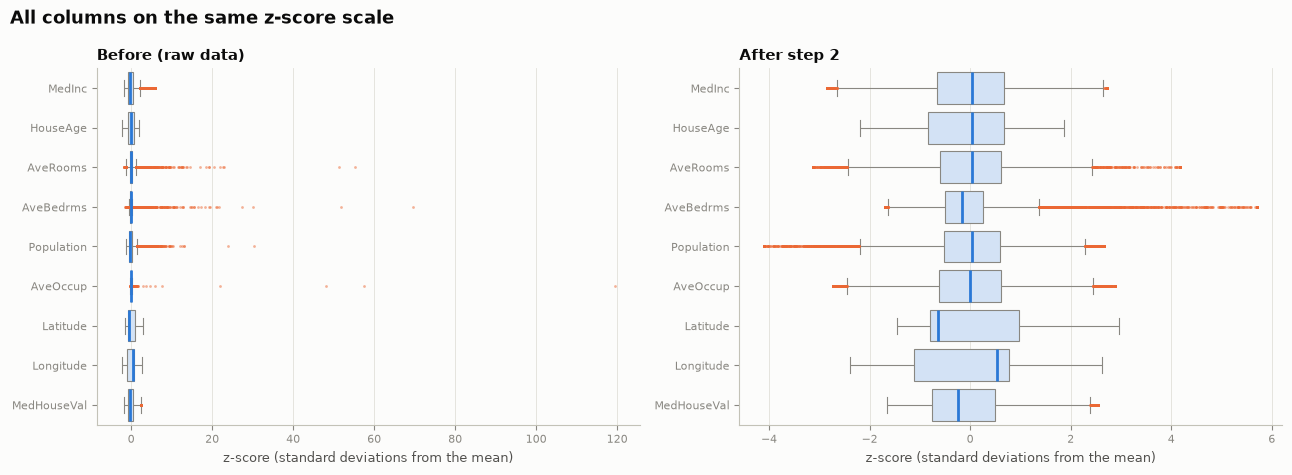

In [32]:
def standardize(df):
    return (df - df.mean()) / df.std()


fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, data, title in [(axes[0], standardize(df_raw), "Before (raw data)"),
                        (axes[1], standardize(df_treated), "After step 2")]:
    long = data.melt(var_name="column", value_name="z")
    sns.boxplot(data=long, x="z", y="column", ax=ax, color="#cde2fb", linecolor=GRAY, linewidth=0.8,
                fliersize=2, flierprops={"markerfacecolor": ORANGE, "markeredgecolor": "none", "alpha": 0.5},
                medianprops={"color": BLUE, "linewidth": 2})
    ax.set_title(title)
    ax.set_xlabel("z-score (standard deviations from the mean)")
    ax.set_ylabel("")
fig.suptitle("All columns on the same z-score scale", fontsize=13, fontweight="bold", x=0.01, ha="left")
plt.tight_layout()
plt.show()

**O tratamento funcionou:**

- **Os extremos estão sob controle.** O maior z-score caiu de 119 para 2,9 (`AveOccup`), de 70 para 5,7 (`AveBedrms`), de 55 para 4,2 (`AveRooms`) e de 30 para 4,1 (`Population`). Nenhuma linha fica a mais de ~6 desvios padrão da média. No gráfico do "antes", uma única prisão espremia todas as outras colunas numa linha fina.
- **Os formatos estão perto de simétricos.** A skewness agora está perto de 0 em todas as colunas transformadas, exceto `AveBedrms` (2,9): 86% dos block groups têm entre 0,95 e 1,2 quarto por domicílio, então qualquer outro valor parece distante.
- **As contagens do IQR quase não mudaram em algumas colunas, e tudo bem.** A regra do IQR também marca outliers *leves*. Até uma curva em sino perfeita tem algumas linhas fora dos limites. Para clustering, o que importa é **a que distância** estão os extremos, e isso foi resolvido.
- `MedHouseVal`, `HouseAge`, `Latitude` e `Longitude` não mudaram, **de propósito**. Os 1.066 "outliers" do IQR que sobraram em `MedHouseVal` são as linhas com teto de US\$ 500 mil que decidimos manter.

## Etapa 2 — Conclusão

**O que fizemos:**

- **Removemos 85 linhas (0,4%)**, cada uma com um motivo documentado (domicílios coletivos, block groups minúsculos, valores impossíveis). Elas ficam guardadas no `df_removed`, não perdidas.
- **Aplicamos log** nas cinco colunas assimétricas (`MedInc`, `AveRooms`, `AveBedrms`, `Population`, `AveOccup`).
- **Cortamos** os extremos restantes nos percentis 0,5% / 99,5% (1% / 99% para `AveBedrms`).
- **Deixamos como estavam** `HouseAge`, `MedHouseVal`, `Latitude` e `Longitude`, onde uma transformação faria mais mal do que bem.
- **Marcamos** os valores com teto em `cap_flags`, para descrever os clusters depois.

**O que temos agora:**

- `df_clean`: 20.555 linhas em **unidades naturais** (só as linhas ruins removidas). Guardamos essa tabela para a etapa 6, onde as novas features precisam de unidades naturais.
- `treat_outliers()`: uma função que aplica todas as nossas decisões. Vamos reutilizá-la nas etapas 3, 4 e 7.
- `df_treated`: o resultado de `treat_outliers(df_clean)`. Nenhuma linha fica a mais de ~6 desvios padrão da média.

**Principais lições:**

- Uma ferramenta para cada **tipo** de outlier: remover o que não pertence, transformar a assimetria, cortar o resto.
- Não confie num único número. O Yeo-Johnson "ganhou" na skewness, mas criou um novo extremo.
- Mantenha as decisões em código (`treat_outliers`) para que sejam **repetíveis**.

---
# Etapa 3 — Scaling

**O problema:** nossas colunas usam unidades muito diferentes. `Population` chega aos milhares; `AveOccup` fica em torno de 3. Numa distância, a coluna com os maiores números vence.

**Um jeito simples de medir isso.** Na distância euclidiana, a parcela de cada coluna na **variância total** é exatamente a sua parcela na distância média (ao quadrado) entre duas linhas. Então:

> **peso de uma coluna nas distâncias = sua variância / soma de todas as variâncias**

Usamos esse número para comparar os scalers. O ideal é que nenhuma coluna domine *por acidente*.

In [33]:
def weight_in_distance(df):
    """Share (%) of each column in the average squared Euclidean distance between rows."""
    variances = df.var()
    return 100 * variances / variances.sum()


weights_no_scaling = pd.DataFrame({
    "raw data": weight_in_distance(df_raw),
    "treated data (after step 2)": weight_in_distance(df_treated),
})
weights_no_scaling.round(2)

,raw data,treated data (after step 2)
MedInc,0.000,0.130
HouseAge,0.010,93.630
AveRooms,0.000,0.040
AveBedrms,0.000,0.010
Population,99.980,0.290
AveOccup,0.010,0.040
Latitude,0.000,2.700
Longitude,0.000,2.380
MedHouseVal,0.000,0.790


**Sem scaling, uma coluna decide tudo:**

- Nos dados brutos, `Population` fica com **99,98%** da distância. Dois block groups seriam "próximos" ou "distantes" só pela população.
- Nos dados tratados, `HouseAge` fica com **94%**. Depois do log, as outras colunas viraram números pequenos, e agora quem vence é a coluna com os maiores números (de 1 a 52 anos).
- **Lição:** sem scaling, os clusters são decididos pelas **unidades**, não pela informação.

## 3.1 Três scalers comuns

| Scaler | Fórmula | Resultado | Ponto fraco |
|---|---|---|---|
| `StandardScaler` | `(x − mean) / std` | média 0, desvio padrão 1 | a média e o desvio padrão são puxados pelos outliers |
| `MinMaxScaler` | `(x − min) / (max − min)` | valores entre 0 e 1 | um único valor extremo define a faixa inteira |
| `RobustScaler` | `(x − median) / IQR` | mediana 0, IQR 1 | a faixa não é limitada; os pesos dependem do formato das caudas |

Testamos cada scaler duas vezes:

1. nos **dados brutos** (como se tivéssemos pulado a etapa 2);
2. nos **dados tratados** (depois da etapa 2).

In [34]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

scalers = {
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "RobustScaler": RobustScaler(),
}


def apply_scaler(scaler, df):
    """Fit a scaler and return the result as a DataFrame (same columns and index)."""
    return pd.DataFrame(scaler.fit_transform(df), columns=df.columns, index=df.index)


weights = {}
for name, scaler in scalers.items():
    weights[("raw data", name)] = weight_in_distance(apply_scaler(scaler, df_raw))
    weights[("treated data", name)] = weight_in_distance(apply_scaler(scaler, df_treated))
weights = pd.DataFrame(weights)
weights.round(1)

,raw data,treated data,raw data,treated data,raw data,treated data
,StandardScaler,StandardScaler,MinMaxScaler,MinMaxScaler,RobustScaler,RobustScaler
MedInc,11.100,11.100,7.500,9.800,0.400,9.200
HouseAge,11.100,11.100,26.800,18.300,0.200,7.100
AveRooms,11.100,11.100,0.100,5.700,1.300,11.000
AveBedrms,11.100,11.100,0.100,5.500,14.300,28.800
Population,11.100,11.100,0.400,6.600,0.800,13.000
AveOccup,11.100,11.100,0.000,9.600,82.300,10.900
Latitude,11.100,11.100,22.600,15.500,0.200,5.200
Longitude,11.100,11.100,17.500,12.000,0.200,4.500
MedHouseVal,11.100,11.100,24.900,17.000,0.400,10.300


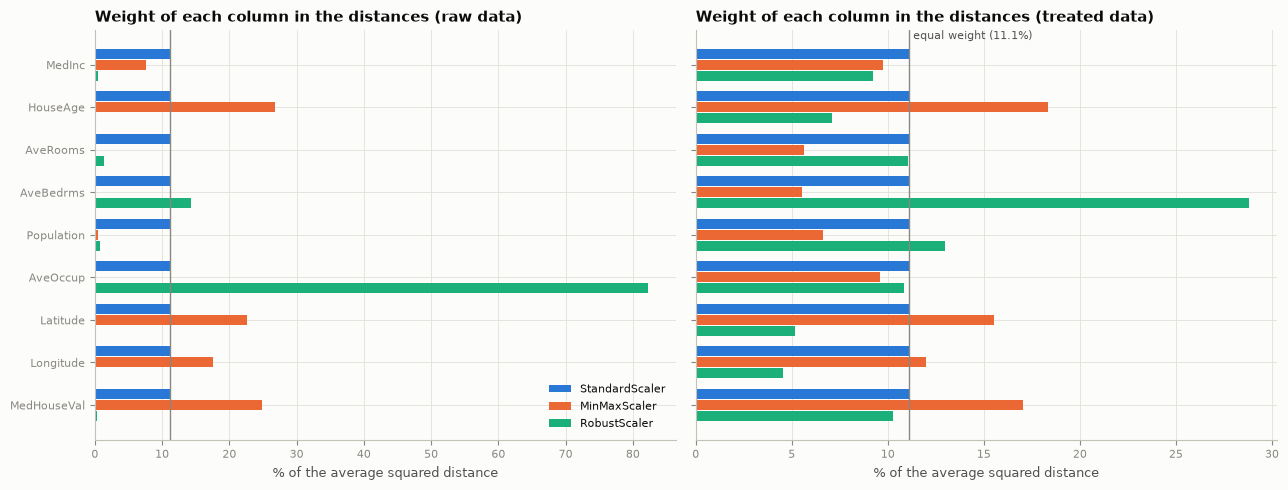

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
cols = df_treated.columns[::-1]           # same order as the table, top to bottom
y = np.arange(len(cols))
bar_h = 0.26
for ax, data_name in zip(axes, ["raw data", "treated data"]):
    for i, (name, color) in enumerate(zip(scalers, [BLUE, ORANGE, AQUA])):
        values = weights[(data_name, name)].reindex(cols)
        ax.barh(y + (1 - i) * bar_h, values, height=bar_h * 0.9, color=color, label=name)
    ax.axvline(100 / len(cols), color=GRAY, linewidth=1)
    ax.set_yticks(y, cols)
    ax.set_title(f"Weight of each column in the distances ({data_name})")
    ax.set_xlabel("% of the average squared distance")
axes[0].legend(loc="lower right")
axes[1].text(100 / len(cols), len(cols) - 0.4, " equal weight (11.1%)", color="#52514e", fontsize=8)
plt.tight_layout()
plt.show()

**Nos dados brutos, cada scaler falha do seu jeito:**

- `MinMaxScaler`: `AveOccup`, `AveRooms`, `AveBedrms` e `Population` ficam com **quase 0%** do peso. Uma única prisão (1.243 pessoas por domicílio) define a faixa, então todo valor normal é espremido perto de 0.
- `RobustScaler`: `AveOccup` fica com **82%** do peso. O IQR dela é pequeno, então os valores extremos viram números enormes (a prisão cai em ~1.460).
- `StandardScaler`: 11,1% para cada coluna. Parece justo, mas veja a próxima tabela.

**Nos dados tratados:**

- `StandardScaler`: pesos exatamente **iguais** (11,1% cada), por construção.
- `MinMaxScaler`: `HouseAge` e `MedHouseVal` ficam com cerca de **3×** o peso de `AveRooms` e `AveBedrms`. As colunas cujos valores preenchem toda a faixa do mínimo ao máximo contam mais.
- `RobustScaler`: `AveBedrms` fica com **29%**, cerca de 6× o peso de `Longitude`. O IQR dela é muito estreito, então dividir por ele deixa os valores grandes. `Latitude` e `Longitude` ficam com só ~5%: o IQR delas é largo (duas regiões metropolitanas), então elas encolhem.

**O `StandardScaler` é mesmo justo nos dados brutos?** Variância igual nem sempre significa influência igual. A tabela abaixo mostra quanto da variância de cada coluna vem do seu **1% de linhas mais extremas**. Numa curva em sino perfeita, esse número fica em torno de 8,5%.

In [36]:
def variance_from_top_1pct(series):
    """Share (%) of a column's variance produced by its 1% most extreme rows."""
    squared_dev = (series - series.mean()) ** 2
    n_top = int(len(series) * 0.01)
    return 100 * squared_dev.nlargest(n_top).sum() / squared_dev.sum()


concentration = pd.DataFrame({
    "raw data": [variance_from_top_1pct(df_raw[c]) for c in df_raw.columns],
    "treated data": [variance_from_top_1pct(df_treated[c]) for c in df_raw.columns],
}, index=df_raw.columns)
concentration.round(1)

,raw data,treated data
MedInc,22.000,7.800
HouseAge,4.100,4.100
AveRooms,74.900,14.400
AveBedrms,93.100,32.500
Population,41.000,15.200
AveOccup,99.500,7.900
Latitude,6.500,6.500
Longitude,5.100,5.100
MedHouseVal,6.400,6.400


**O problema escondido do `StandardScaler` nos dados brutos:**

- Nos dados brutos, **99,5%** da variância de `AveOccup` vem de 1% das linhas (principalmente prisões e alojamentos estudantis). `AveBedrms` (93%) e `AveRooms` (75%) não estão muito melhores.
- Então os "11,1% de peso" de `AveOccup` são gastos quase todos em ~200 linhas. Para os outros 99% das linhas, a coluna quase não conta: elas ficam todas espremidas perto de 0.
- Depois da etapa 2, esses números ficam perto de uma curva em sino (~8%). Só `AveBedrms` (33%) ainda tem uma cauda pesada.
- **Lição:** o `StandardScaler` só é justo **depois** que os outliers são tratados. É por isso que a etapa 2 veio primeiro.

## 3.2 Como ficam os valores depois do scaling

Boxplots dos dados **tratados** depois de cada scaler. Observe a faixa de cada coluna.

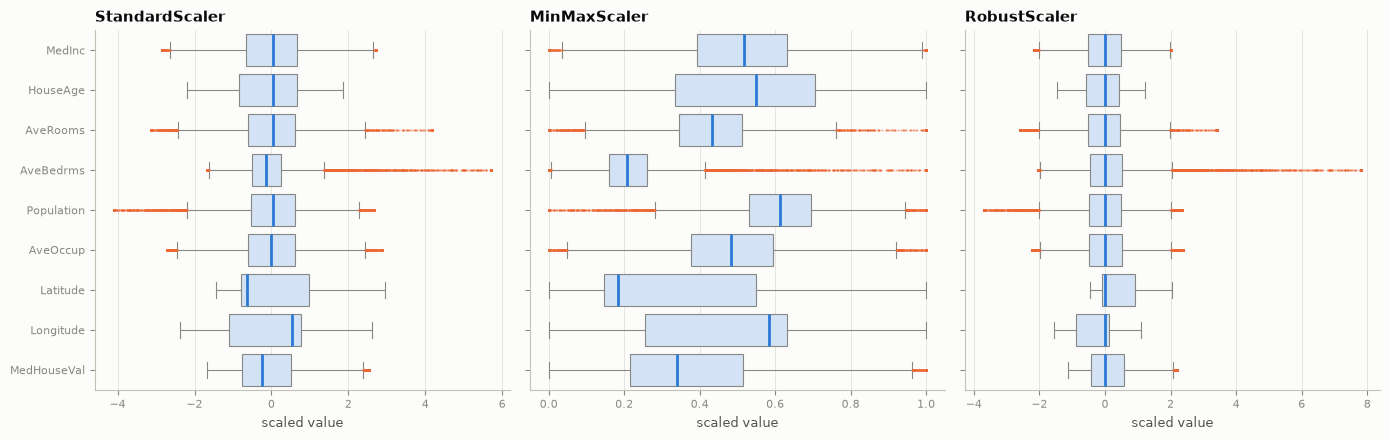

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
for ax, (name, scaler) in zip(axes, scalers.items()):
    long = apply_scaler(scaler, df_treated).melt(var_name="column", value_name="value")
    sns.boxplot(data=long, x="value", y="column", ax=ax, color="#cde2fb", linecolor=GRAY, linewidth=0.8,
                fliersize=1.5, flierprops={"markerfacecolor": ORANGE, "markeredgecolor": "none", "alpha": 0.5},
                medianprops={"color": BLUE, "linewidth": 2})
    ax.set_title(name)
    ax.set_xlabel("scaled value")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

**O que vemos:**

- `StandardScaler`: todas as colunas ficam centradas em 0, com caixas de largura parecida. Os valores vão de cerca de −4 a +6.
- `MinMaxScaler`: todas as colunas cabem em [0, 1], mas as caixas têm larguras muito diferentes. A caixa estreita de `AveBedrms` significa que a maioria das linhas é quase idêntica nessa coluna, então ela quase não afeta as distâncias.
- `RobustScaler`: todas as caixas têm a mesma largura (o IQR é 1 por construção), mas as caudas são muito diferentes. `AveBedrms` chega a ~8.

## 3.3 Decisão

**Escolhemos o `StandardScaler`, aplicado depois do tratamento de outliers da etapa 2.**

- A etapa 2 já removeu e cortou os extremos, então a média e o desvio padrão agora são confiáveis. O principal ponto fraco do `StandardScaler` desapareceu.
- Ele dá a todas as colunas **o mesmo peso** nas distâncias. Nenhuma coluna domina por acidente, por causa das suas unidades ou das suas caudas.
- Se quisermos que algumas colunas contem mais (ou menos), vamos decidir isso **de propósito** na etapa 7. Não é o scaler que deve decidir por nós.
- Unidades padronizadas também são fáceis de ler: um raio do DBSCAN (`eps`) de 0,5 significa "meio desvio padrão".

**Por que não os outros?**

- `MinMaxScaler`: o peso de cada coluna depende dos seus dois valores mais extremos. Ele daria a `HouseAge` 3× o peso de `AveRooms` sem nenhum motivo de negócio.
- `RobustScaler`: uma ótima escolha quando os outliers **ainda estão nos dados**, porque a mediana e o IQR os ignoram. Nós o usaríamos num pipeline automatizado em que ninguém confere cada novo lote. Aqui os outliers já foram tratados, e ele daria a `AveBedrms` 6× o peso de `Longitude`.

In [38]:
def scale(df):
    """Standardize every column (mean 0, std 1). Returns a DataFrame."""
    return apply_scaler(StandardScaler(), df)


df_scaled = scale(df_treated)
df_scaled.describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
MedInc,0.000,1.000,-2.840,2.710
HouseAge,-0.000,1.000,-2.200,1.860
AveRooms,-0.000,1.000,-3.130,4.180
AveBedrms,-0.000,1.000,-1.680,5.710
Population,-0.000,1.000,-4.100,2.650
AveOccup,-0.000,1.000,-2.730,2.880
Latitude,0.000,1.000,-1.450,2.960
Longitude,-0.000,1.000,-2.390,2.630
MedHouseVal,0.000,1.000,-1.660,2.540


**Um detalhe sobre latitude e longitude.** Fazer o scaling delas separadamente poderia distorcer o mapa: 1 unidade de latitude deixaria de valer 1 unidade de longitude. Aqui os desvios padrão delas são quase iguais (2,1° vs 2,0°), então a distorção é desprezível. Com dispersões muito diferentes, dividiríamos as duas pelo *mesmo* número.

## Etapa 3 — Conclusão

- **Scaling é obrigatório para clustering.** Sem ele, uma coluna (`Population`, ou `HouseAge` depois do log) decide tudo.
- **O melhor scaler depende do que veio antes.** Nos dados brutos, os três scalers falham de jeitos diferentes. Depois da etapa 2, o `StandardScaler` dá pesos iguais e confiáveis.
- Guardamos a função `scale()`. Vamos aplicá-la de novo na **etapa 7**, sobre o conjunto final de colunas, incluindo as novas e as codificadas.
- Ajustamos (fit) o scaler em todas as linhas: clustering não tem divisão treino/teste. Se novos block groups chegarem depois, nós os transformamos com o **mesmo scaler já ajustado**, para que uma linha receba sempre os mesmos valores padronizados.

---
# Etapa 4 — Tratamento de nulos

Nosso dataset **não tem nulos**, então criamos alguns de propósito. Isso tem uma grande vantagem para o aprendizado: **conhecemos os valores reais**, então podemos medir o quão bom é cada método de preenchimento.

**Por que nulos importam para clustering:**

- A maioria dos algoritmos de clustering (K-Means, DBSCAN, ...) **não roda** com nulos.
- Remover toda linha com um nulo pode jogar fora muitos dados, e pode **enviesar** o resultado se os nulos não forem aleatórios.
- Um método de preenchimento ruim pode criar **estrutura falsa**. Por exemplo, 2.000 linhas com exatamente o mesmo valor formam um ponto denso artificial que um algoritmo de clustering pode "descobrir".

**Três tipos de valores faltantes** (o tipo decide o que funciona):

| Tipo | Significado | Exemplo |
|---|---|---|
| **MCAR** (Missing Completely At Random, ausente completamente ao acaso) | puro acaso | uma falha no sistema apaga células aleatórias |
| **MAR** (Missing At Random, ausente ao acaso) | depende de **outras** colunas que conseguimos ver | a renda falta com mais frequência nas áreas caras |
| **MNAR** (Missing Not At Random, ausente não ao acaso) | depende do **próprio valor que falta** | pessoas ricas se recusam a informar a renda |

O MNAR é o caso mais difícil: nenhum método consegue corrigir totalmente sem informação extra.

## 4.1 Criar os valores faltantes

Escolhemos três colunas com perfis diferentes:

| Coluna | Tipo de nulos | Por que esta coluna |
|---|---|---|
| `HouseAge` | MCAR, 10% | coluna simétrica; casas da mesma área costumam ser construídas na mesma época, então os **vizinhos** devem ajudar |
| `MedInc` | MAR, ~10% | coluna assimétrica; os nulos são mais frequentes nas áreas **caras** (2% nas mais baratas → 18% nas mais caras) |
| `AveOccup` | MCAR, 10% | coluna assimétrica; ligada à renda e à localização |

In [39]:
rng = np.random.default_rng(RANDOM_STATE)
n_rows = len(df_clean)

# HouseAge and AveOccup: 10% missing, completely at random (MCAR)
mask_age = rng.random(n_rows) < 0.10
mask_occup = rng.random(n_rows) < 0.10

# MedInc: the more expensive the area, the more likely the income is missing (MAR)
value_rank = df_clean["MedHouseVal"].rank(pct=True).to_numpy()   # 0 = cheapest, 1 = most expensive
mask_income = rng.random(n_rows) < 0.02 + 0.16 * value_rank

missing_masks = {"HouseAge": mask_age, "MedInc": mask_income, "AveOccup": mask_occup}

df_missing = df_clean.copy()
for col, mask in missing_masks.items():
    df_missing.loc[mask, col] = np.nan

print(df_missing.isna().sum().to_string())
print(f"\nRows with at least one null: {df_missing.isna().any(axis=1).sum():,} "
      f"({df_missing.isna().any(axis=1).mean():.1%})")

MedInc         2022
HouseAge       2011
AveRooms          0
AveBedrms         0
Population        0
AveOccup       2024
Latitude          0
Longitude         0
MedHouseVal       0

Rows with at least one null: 5,497 (26.7%)


**Um primeiro alerta.** Se simplesmente removêssemos toda linha com um nulo, perderíamos quase 27% dos dados. Vamos também conferir se os nulos de `MedInc` realmente não são aleatórios.

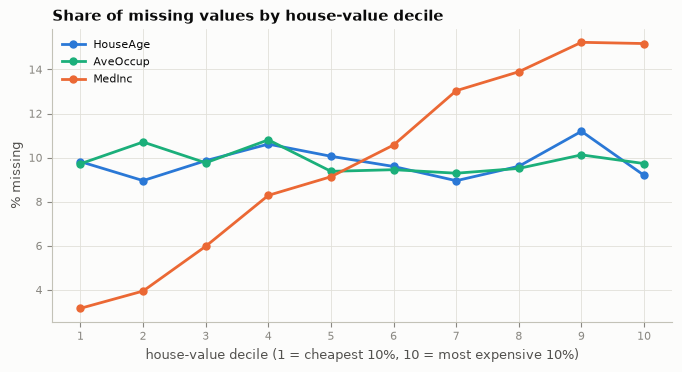

True mean income (all rows):         3.871
Mean income of the rows we can see:  3.809


In [40]:
value_decile = pd.qcut(df_clean["MedHouseVal"], 10, labels=range(1, 11))
missing_rate = df_missing.isna().groupby(value_decile, observed=True).mean() * 100

fig, ax = plt.subplots(figsize=(8, 3.8))
for col, color in zip(["HouseAge", "AveOccup", "MedInc"], [BLUE, AQUA, ORANGE]):
    ax.plot(missing_rate.index.astype(int), missing_rate[col], marker="o", markersize=5,
            linewidth=2, color=color, label=col)
ax.set_title("Share of missing values by house-value decile")
ax.set_xlabel("house-value decile (1 = cheapest 10%, 10 = most expensive 10%)")
ax.set_ylabel("% missing")
ax.set_xticks(range(1, 11))
ax.legend(loc="upper left")
plt.show()

print(f"True mean income (all rows):         {df_clean['MedInc'].mean():.3f}")
print(f"Mean income of the rows we can see:  {df_missing['MedInc'].mean():.3f}")

**O que vemos:**

- `HouseAge` e `AveOccup`: a parcela de nulos é plana (~10%) em todos os decis. Isso é **MCAR**.
- `MedInc`: a parcela sobe de ~3% nas áreas mais baratas para ~15% nas mais caras. Isso é **MAR**: as rendas que faltam são, na maioria, de áreas **mais ricas**.
- Então as rendas que *conseguimos* ver são um pouco mais baixas que a realidade (média 3,809 vs 3,871). Qualquer método que ignore as outras colunas vai preencher áreas ricas com uma renda "média" e **subestimá-la**.
- **Remover as linhas não é uma opção:** perderíamos 27% dos dados, e as linhas perdidas seriam principalmente de áreas caras. Os clusters ficariam enviesados para as vizinhanças mais baratas.

## 4.2 Os métodos candidatos

| Método | Como preenche um nulo | Ponto forte | Ponto fraco |
|---|---|---|---|
| **Média** | a média da coluna | simples | ignora todo o resto; cria um pico; enviesada sob MAR |
| **Mediana** | o valor do meio da coluna | robusta a outliers | os mesmos problemas da média |
| **KNN imputer** | a média das *k* linhas mais parecidas | usa as outras colunas; mantém padrões locais | precisa de dados com scaling; mais lento |
| **Iterative imputer** | prevê cada coluna a partir das outras com um modelo, em algumas rodadas | consegue aprender relações complexas | mais complexo; mais lento |

**Dois detalhes práticos:**

- Os imputers KNN e iterativo trabalham no espaço **tratado e padronizado** das etapas 2 e 3. Só lá as distâncias fazem sentido. Depois de preencher, voltamos para as unidades naturais (desfazemos o scaling e o log).
- Só substituímos as células **faltantes**. Os valores conhecidos nunca são alterados.

In [41]:
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer  # noqa: F401 (unlocks IterativeImputer)
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge
from sklearn.ensemble import HistGradientBoostingRegressor

# The space where KNN and the iterative imputer work: treated (step 2) + standardized (step 3)
missing_treated = treat_outliers(df_missing)          # nulls stay null
imputation_scaler = StandardScaler().fit(missing_treated)   # the scaler simply ignores nulls
missing_scaled = pd.DataFrame(imputation_scaler.transform(missing_treated),
                              columns=df_missing.columns, index=df_missing.index)


def keep_known_values(filled):
    """Take only the filled cells from `filled`; every known value stays as it was."""
    result = df_missing.copy()
    for col, mask in missing_masks.items():
        result.loc[mask, col] = filled.loc[mask, col]
    return result


def impute_in_scaled_space(imputer):
    """Fill the nulls in the treated + scaled space, then go back to natural units."""
    filled = pd.DataFrame(imputer.fit_transform(missing_scaled),
                          columns=df_missing.columns, index=df_missing.index)
    filled = pd.DataFrame(imputation_scaler.inverse_transform(filled),   # undo the scaling
                          columns=df_missing.columns, index=df_missing.index)
    filled[LOG_COLS] = np.exp(filled[LOG_COLS])                          # undo the log
    return keep_known_values(filled)


def evaluate(filled, method):
    """Compare the filled cells with the true values (possible only because we created the nulls)."""
    rows = []
    for col, mask in missing_masks.items():
        truth, guess = df_clean.loc[mask, col], filled.loc[mask, col]
        rows.append({
            "method": method,
            "column": col,
            "MAE": (guess - truth).abs().mean(),          # typical error, in natural units
            "bias": (guess - truth).mean(),               # < 0 means we under-estimate
            "spread_kept_%": 100 * guess.std() / truth.std(),
        })
    return rows

**Primeiro, escolha o `k` do KNN imputer.** `k` é o número de vizinhos usados para preencher um nulo. Pequeno demais: ruidoso. Grande demais: todo nulo recebe uma média borrada.

In [42]:
k_results = []
for k in [5, 10, 20, 50]:
    filled = impute_in_scaled_space(KNNImputer(n_neighbors=k))
    k_results += evaluate(filled, f"KNN (k={k})")
pd.DataFrame(k_results).pivot(index="method", columns="column", values="MAE").round(3)

column,AveOccup,HouseAge,MedInc
method,,,
KNN (k=10),0.411,7.762,0.651
KNN (k=20),0.406,7.790,0.653
KNN (k=5),0.420,7.892,0.672
KNN (k=50),0.414,7.907,0.665


**Escolhendo o `k`:**

- O erro muda muito pouco entre k = 5 e k = 50. Isso é comum: o KNN não é muito sensível ao `k` nessa faixa.
- k = 10 é o melhor para `HouseAge` e `MedInc`, e fica a menos de 1% do melhor para `AveOccup`. **Ficamos com k = 10.**
- Um `k` pequeno (5) é um pouco mais ruidoso. Um `k` grande (50) começa a borrar os padrões locais.

**Agora todos os métodos lado a lado.** Também adicionamos duas versões de "controle" para aprender com elas:

- **KNN sem as etapas 2 e 3** (unidades brutas): para ver o que acontece quando as distâncias não estão preparadas.
- **Iterative imputer com um modelo linear** (`BayesianRidge`, o padrão): para comparar com um modelo não linear (gradient boosting).

In [43]:
filled_by_method = {
    "Mean": df_missing.fillna(df_missing.mean()),
    "Median": df_missing.fillna(df_missing.median()),
    "KNN (k=10), raw units": keep_known_values(pd.DataFrame(
        KNNImputer(n_neighbors=10).fit_transform(df_missing),
        columns=df_missing.columns, index=df_missing.index)),
    "KNN (k=10)": impute_in_scaled_space(KNNImputer(n_neighbors=10)),
    "Iterative (linear)": impute_in_scaled_space(
        IterativeImputer(estimator=BayesianRidge(), max_iter=10, random_state=RANDOM_STATE)),
}

# Tree models never "settle" exactly, so scikit-learn warns that its stopping rule was not met.
# The error is already stable after 1-2 rounds, so 3 rounds are enough and the warning is harmless.
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*Early stopping criterion not reached.*")
    filled_by_method["Iterative (gradient boosting)"] = impute_in_scaled_space(
        IterativeImputer(estimator=HistGradientBoostingRegressor(random_state=RANDOM_STATE),
                         max_iter=3, random_state=RANDOM_STATE))

results = pd.DataFrame([row for method, filled in filled_by_method.items()
                        for row in evaluate(filled, method)])
results.pivot(index="method", columns="column", values=["MAE", "bias", "spread_kept_%"]).round(2)

MAE                     bias           \
column                        AveOccup HouseAge MedInc AveOccup HouseAge   
method                                                                     
Iterative (gradient boosting)    0.360    6.350  0.600   -0.060   -0.040   
Iterative (linear)               0.490    9.020  0.680   -0.080    0.260   
KNN (k=10)                       0.410    7.760  0.650   -0.050    0.930   
KNN (k=10), raw units            0.560    9.700  1.360    0.020    0.740   
Mean                             0.560   10.660  1.500   -0.000    0.010   
Median                           0.560   10.650  1.570   -0.110    0.380   

                                     spread_kept_%                  
column                        MedInc      AveOccup HouseAge MedInc  
method                                                              
Iterative (gradient boosting) -0.090        65.700   71.030 88.270  
Iterative (linear)            -0.130        43.100   49.090 91.380  
KNN (k=10)                    -0.110        61.660   63.830 83.150  
KNN (k=10), raw units         -0.580        43.510   47.410 32.320  
Mean                          -0.620         0.000    0.000  0.000  
Median                        -0.950         0.000    0.000  0.000

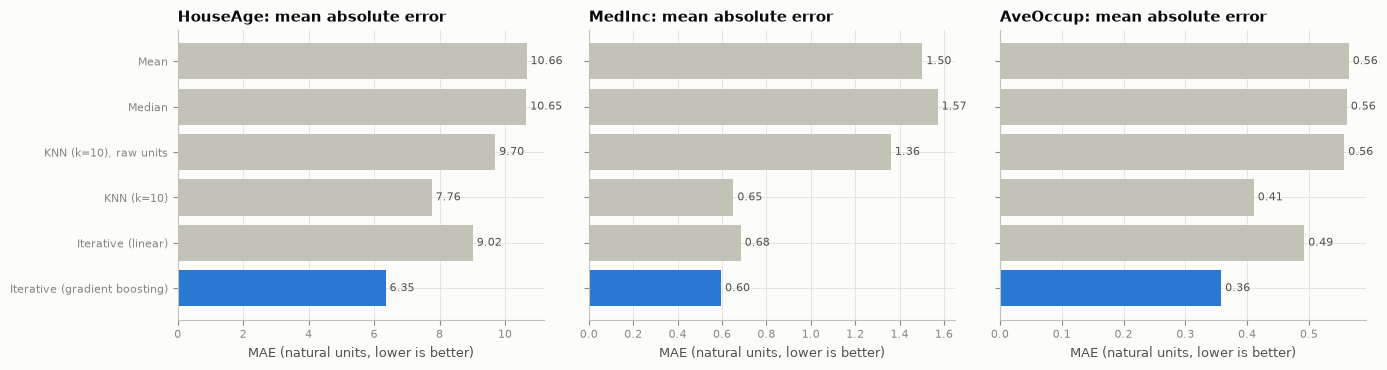

In [44]:
methods = list(filled_by_method)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, col in zip(axes, missing_masks):
    mae = results[results["column"] == col].set_index("method").loc[methods, "MAE"]
    colors = [BLUE if m == mae.idxmin() else LIGHT_GRAY for m in methods]
    ax.barh(methods, mae, color=colors)
    ax.invert_yaxis()
    for i, value in enumerate(mae):
        ax.text(value, i, f" {value:.2f}", va="center", fontsize=8, color="#52514e")
    ax.set_title(f"{col}: mean absolute error")
    ax.set_xlabel("MAE (natural units, lower is better)")
plt.tight_layout()
plt.show()

**Lendo os resultados:**

- **Média e mediana são as piores em tudo.** Elas também são **enviesadas** em `MedInc`: cada renda preenchida fica, em média, US\$ 6,2 mil (média) ou US\$ 9,5 mil (mediana) abaixo do valor real. A mediana é pior aqui porque as rendas que faltam são altas, e a mediana é menor que a média.
- **KNN em unidades brutas** (pulando as etapas 2 e 3) é quase tão ruim quanto a média em `MedInc` (1,36 vs 1,50). Sem scaling, a distância é dominada por `Population`, então os "vizinhos" são só block groups com população parecida. As etapas 2 e 3 fazem diferença de novo!
- **KNN nos dados preparados** reduz muito o erro em relação à média: −27% (`HouseAge`), −57% (`MedInc`), −27% (`AveOccup`). O viés da renda quase desaparece (−0,11 vs −0,62): o KNN olha o valor das casas e a localização, o que "corrige" o problema do MAR.
- **Iterative (linear)** vai bem em `MedInc` (uma relação quase em linha reta com o valor das casas), mas mal em `HouseAge` (9,02). A idade de uma vizinhança depende de *onde* ela fica, um padrão que uma linha reta não consegue capturar.
- **Iterative (gradient boosting)** é o melhor em todas as colunas: −40% (`HouseAge`), −60% (`MedInc`), −36% (`AveOccup`) em relação à média, quase sem viés.
- `spread_kept_%`: a média e a mediana mantêm **0%** da variação natural (todo nulo recebe o mesmo número). O gradient boosting mantém 66–88%; o KNN, 62–83%. Um pouco de encolhimento é normal: uma previsão é sempre um pouco mais "cautelosa" que a realidade.

## 4.3 Os dados preenchidos parecem reais?

Um erro baixo não basta. Os valores preenchidos também devem **parecer** valores reais: mesma dispersão, sem picos. Vamos comparar as rendas reais das linhas com nulo com três métodos.

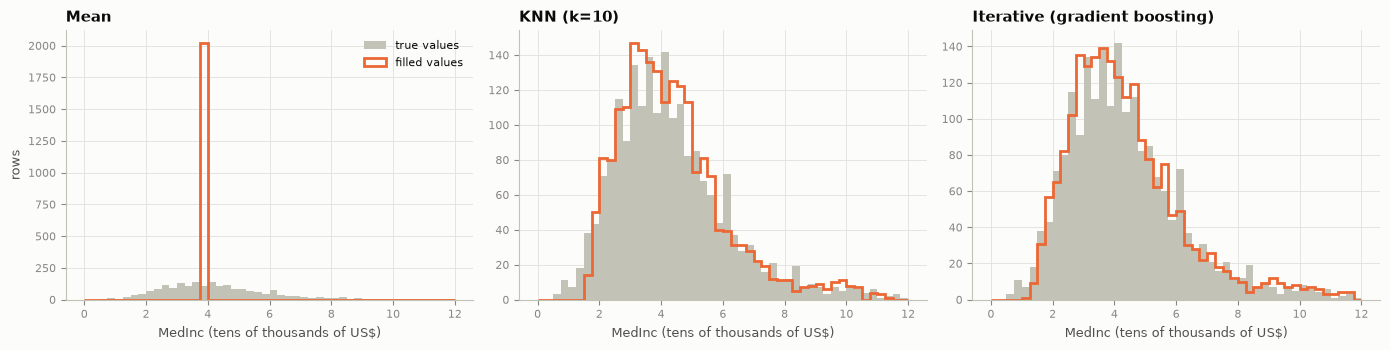

In [45]:
mask = missing_masks["MedInc"]
truth = df_clean.loc[mask, "MedInc"]
bins = np.linspace(0, 12, 49)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, method in zip(axes, ["Mean", "KNN (k=10)", "Iterative (gradient boosting)"]):
    ax.hist(truth, bins=bins, color=LIGHT_GRAY, label="true values")
    ax.hist(filled_by_method[method].loc[mask, "MedInc"], bins=bins, histtype="step",
            linewidth=2, color=ORANGE, label="filled values")
    ax.set_title(method)
    ax.set_xlabel("MedInc (tens of thousands of US$)")
axes[0].set_ylabel("rows")
axes[0].legend(loc="upper right")
plt.tight_layout()
plt.show()

**O que os histogramas mostram:**

- **Média:** todos os 2.022 nulos recebem o mesmo valor (3,8). Isso cria um **pico**: 2.000 linhas empilhadas num só ponto, um ponto denso falso. Um algoritmo baseado em densidade, como o DBSCAN, poderia "descobri-lo" como um cluster. E ele ainda está no lugar errado: os valores reais se espalham de 1 a 10.
- **KNN** e **gradient boosting** seguem de perto a distribuição real, incluindo a cauda mais rica à direita.

## 4.4 Decisão

**Escolhemos o iterative imputer com gradient boosting.**

- Ele tem o **menor erro** nas três colunas.
- Ele **quase não tem viés**, então lida bem com os nulos MAR de `MedInc`.
- Ele mantém a maior parte da **dispersão** natural: sem pico, sem densidade falsa.
- Ele usa todas as outras colunas (incluindo a localização) e consegue aprender padrões **não lineares**, como "as casas desta área foram construídas nos anos 1950".

**Segundo lugar: KNN (k = 10).** Mais simples de explicar, sem modelo para treinar, e também uma escolha muito boa. Nós o escolheríamos se a simplicidade importasse mais que os últimos 10–20% de precisão.

**Descartados:** a média e a mediana (enviesadas, criam um pico, ignoram as outras colunas), e remover linhas (27% dos dados, principalmente áreas caras).

In [46]:
df_imputed = filled_by_method["Iterative (gradient boosting)"]

# Remember which cells were filled (for transparency, not for clustering)
imputed_flags = pd.DataFrame({f"{col}_imputed": mask for col, mask in missing_masks.items()},
                             index=df_imputed.index)

print(f"Nulls left: {df_imputed.isna().sum().sum()}")
print(imputed_flags.sum().to_string())

Nulls left: 0
HouseAge_imputed    2011
MedInc_imputed      2022
AveOccup_imputed    2024


> **Como fazer isso na vida real (quando você não conhece os valores reais):** pegue as linhas *sem* nulos, esconda de propósito 10% dos valores conhecidos, preencha com cada método e meça o erro. Foi exatamente isso que fizemos aqui, e é o jeito honesto de escolher um imputer.

## Etapa 4 — Conclusão

- Criamos nulos em 3 colunas (dois MCAR, um MAR). Juntos, eles atingem 27% das linhas.
- Comparamos 6 métodos com os **valores reais** e escolhemos o **iterative imputer com gradient boosting**.
- `df_imputed` é o `df_clean` com os nulos preenchidos, em unidades naturais. **Daqui em diante seguimos com ele**, como se os nulos tivessem sido reais.
- `imputed_flags` guarda quais células foram preenchidas, por transparência. Não o usamos no clustering: nossos nulos são artificiais, então "estava faltando" não carrega nenhuma informação real.

**Principais lições:**

- Remover linhas é perigoso quando os nulos **não são aleatórios** (MAR): isso enviesa os dados.
- A média e a mediana criam **picos**, que parecem clusters falsos.
- O KNN só funciona bem com **distâncias preparadas**. As etapas 2 e 3 valeram a pena de novo.
- Escolha um imputer **medindo**: esconda valores conhecidos, preencha, compare.

---
# Etapa 5 — Encoding de variáveis

Os algoritmos precisam de **números**. Categorias de texto (como "Los Angeles County") precisam ser **codificadas** como números primeiro.

**Em clustering, o encoding é mais delicado que o normal.** Os números que escolhemos criam **distâncias entre as categorias**. Se codificarmos `Alameda = 1`, `Fresno = 2`, `Los Angeles = 3`, o algoritmo "acredita" que Alameda está mais perto de Fresno do que de Los Angeles. Isso é uma **distância falsa**.

Duas coisas decidem o encoding certo:

- **Tipo:** *nominal* (sem ordem: condado, região) ou *ordinal* (ordem natural: nova → antiga).
- **Cardinalidade:** quantos valores diferentes existem. *Baixa* (um punhado) ou *alta* (dezenas, centenas).

## 5.1 Criar colunas categóricas juntando dados externos

Nosso dataset não tem colunas de texto. Em vez de inventar categorias, fazemos o que um cientista de dados faz num projeto real: **juntamos (join)** nossos dados com outros datasets públicos. Praticamos três tipos de join:

| Nova coluna | Dados externos | Tipo de join | Cardinalidade |
|---|---|---|---|
| `county` | limites dos condados do Censo dos EUA (polígonos) | **spatial join**: qual polígono contém cada ponto? | 58 (alta) |
| `region` | uma pequena tabela condado → região | **join por chave**: casar pelo nome do condado | 10 (baixa) |
| `nearest_city` | tabela de cidades da Califórnia com coordenadas | **join por vizinho mais próximo**: a cidade mais perto | ~200 (muito alta) |

Também criamos uma coluna **ordinal** a partir de `HouseAge` (faixas de idade).

Os arquivos são baixados uma vez e salvos na pasta `data/`.

In [47]:
import urllib.request
import geopandas as gpd
from sklearn.neighbors import BallTree


def download(url, filename):
    """Download a file once and keep it in the local data folder."""
    path = DATA_DIR / filename
    if not path.exists():
        print(f"Downloading {filename} ...")
        urllib.request.urlretrieve(url, path)
    return path


df_cat = df_imputed.copy()   # we add the categorical columns to a copy

### (a) Spatial join: em qual condado fica cada block group?

- Os limites dos condados vêm do US Census Bureau (um arquivo GeoJSON com todos os condados dos EUA e seus códigos oficiais **FIPS**).
- O código do estado da Califórnia é `06`, então mantemos só esses 58 condados.
- Cada block group vira um **ponto** (longitude, latitude). Um spatial join encontra o polígono do condado que **contém** cada ponto.

In [48]:
counties_path = download(
    "https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json",
    "us_counties_fips.geojson")

ca_counties = (gpd.read_file(counties_path)
               .query("STATE == '06'")
               .rename(columns={"id": "county_fips", "NAME": "county"})
               [["county_fips", "county", "geometry"]])
print(f"California counties: {len(ca_counties)}")

points = gpd.GeoDataFrame(
    index=df_cat.index,
    geometry=gpd.points_from_xy(df_cat["Longitude"], df_cat["Latitude"]),
    crs="EPSG:4326")                     # EPSG:4326 = plain longitude / latitude

joined = gpd.sjoin(points, ca_counties, predicate="within", how="left")
joined = joined[~joined.index.duplicated(keep="first")]   # a point on a border can match twice
print(f"Points inside a county polygon: {joined['county'].notna().sum():,}")
print(f"Points outside every polygon:   {joined['county'].isna().sum():,}")

California counties: 58
Points inside a county polygon: 20,328
Points outside every polygon:   227


Alguns pontos caem logo **fora** de todos os polígonos. Os limites neste arquivo são simplificados, então um block group no litoral pode cair "no mar". Para esses pontos, usamos o condado **mais próximo**.

Para medir distâncias em metros, primeiro **projetamos** o mapa em `EPSG:3310` (California Albers, um mapa plano feito para a Califórnia).

In [49]:
outside = joined["county"].isna()
nearest = gpd.sjoin_nearest(points[outside].to_crs("EPSG:3310"), ca_counties.to_crs("EPSG:3310"),
                            how="left", distance_col="distance_m")
nearest = nearest[~nearest.index.duplicated(keep="first")]
joined.loc[outside, ["county", "county_fips"]] = nearest[["county", "county_fips"]]

print(f"Distance to the nearest county for those points: median {nearest['distance_m'].median():,.0f} m, "
      f"max {nearest['distance_m'].max():,.0f} m")

df_cat["county_fips"] = joined["county_fips"]
df_cat["county"] = joined["county"]
print(f"Block groups without a county: {df_cat['county'].isna().sum()}")
df_cat["county"].value_counts()

Distance to the nearest county for those points: median 1,969 m, max 8,727 m
Block groups without a county: 0


county
Los Angeles        5837
San Diego          1604
Orange             1584
Santa Clara         996
Alameda             956
San Bernardino      826
Sacramento          685
Contra Costa        650
Riverside           586
San Francisco       573
Fresno              521
San Mateo           451
San Joaquin         413
Ventura             382
Kern                366
Sonoma              314
Stanislaus          298
Santa Barbara       297
Tulare              257
Monterey            201
Solano              199
Santa Cruz          188
Marin               164
Butte               155
San Luis Obispo     146
Placer              134
Merced              128
Humboldt            127
Shasta              121
El Dorado           120
Imperial            117
Napa                103
Nevada               95
Kings                87
Lake                 87
Yolo                 80
Mendocino            79
Madera               78
Tuolumne             56
Sutter               55
Yuba                 53
Tehama   

### (b) Join por chave: do condado para a região

- A Califórnia costuma ser descrita em **10 regiões**. Usamos as regiões definidas pelo California Complete Count Office para o Censo de 2020.
- Escrevemos a tabela de consulta nós mesmos (58 linhas) e fazemos o join pelo nome do condado. É o tipo de join mais comum em projetos reais.

In [50]:
REGIONS = {
    "Superior California": ["Butte", "Colusa", "El Dorado", "Glenn", "Lassen", "Modoc", "Nevada", "Placer",
                            "Plumas", "Sacramento", "Shasta", "Sierra", "Siskiyou", "Sutter", "Tehama",
                            "Yolo", "Yuba"],
    "North Coast": ["Del Norte", "Humboldt", "Lake", "Mendocino", "Napa", "Sonoma", "Trinity"],
    "San Francisco Bay Area": ["Alameda", "Contra Costa", "Marin", "San Francisco", "San Mateo",
                               "Santa Clara", "Solano"],
    "Northern San Joaquin Valley": ["Alpine", "Amador", "Calaveras", "Madera", "Mariposa", "Merced", "Mono",
                                    "San Joaquin", "Stanislaus", "Tuolumne"],
    "Central Coast": ["Monterey", "San Benito", "San Luis Obispo", "Santa Barbara", "Santa Cruz", "Ventura"],
    "Southern San Joaquin Valley": ["Fresno", "Inyo", "Kern", "Kings", "Tulare"],
    "Inland Empire": ["Riverside", "San Bernardino"],
    "Los Angeles County": ["Los Angeles"],
    "Orange County": ["Orange"],
    "San Diego - Imperial": ["Imperial", "San Diego"],
}
region_lookup = pd.DataFrame(
    [(county, region) for region, counties in REGIONS.items() for county in counties],
    columns=["county", "region"]).set_index("county")
print(f"Counties in the lookup table: {len(region_lookup)}")

df_cat = df_cat.join(region_lookup, on="county", how="left")   # a left join keeps every row
print(f"Block groups without a region: {df_cat['region'].isna().sum()}")
df_cat["region"].value_counts()

Counties in the lookup table: 58
Block groups without a region: 0


region
Los Angeles County             5837
San Francisco Bay Area         3989
San Diego - Imperial           1721
Superior California            1699
Orange County                  1584
Inland Empire                  1412
Southern San Joaquin Valley    1249
Central Coast                  1242
Northern San Joaquin Valley    1070
North Coast                     752
Name: count, dtype: int64

### (c) Join por vizinho mais próximo: a cidade mais perto

- A tabela de cidades tem as coordenadas das ~1.000 maiores cidades dos EUA. Mantemos as 212 da Califórnia.
- Para cada block group, encontramos a cidade **mais próxima** com uma `BallTree` usando a distância **haversine** (a distância sobre uma esfera). Vamos usar a mesma ferramenta de novo na etapa 6.
- Observação: "centro de cidade mais próximo" não é o mesmo que "a cidade a que o block group pertence" (para isso, precisaríamos dos limites das cidades). Mesmo assim, é um rótulo de localização útil.

In [51]:
cities_path = download(
    "https://raw.githubusercontent.com/plotly/datasets/master/us-cities-top-1k.csv",
    "us_cities_top1k.csv")
ca_cities = pd.read_csv(cities_path).query("State == 'California'").reset_index(drop=True)
print(f"California cities in the table: {len(ca_cities)}")

EARTH_RADIUS_KM = 6371
city_tree = BallTree(np.radians(ca_cities[["lat", "lon"]]), metric="haversine")   # expects radians
distance, index = city_tree.query(np.radians(df_cat[["Latitude", "Longitude"]]), k=1)
df_cat["nearest_city"] = ca_cities.loc[index[:, 0], "City"].to_numpy()

print(f"Different nearest cities: {df_cat['nearest_city'].nunique()}")
print(f"Distance to the nearest city: median {np.median(distance) * EARTH_RADIUS_KM:.1f} km")

California cities in the table: 212
Different nearest cities: 212
Distance to the nearest city: median 4.1 km


### (d) Uma coluna ordinal: faixas de idade das casas

- Agrupamos `HouseAge` em 5 faixas com uma **ordem natural**.
- A última faixa guarda o valor com teto (52 significa "52 ou mais", veja a etapa 1).

In [52]:
AGE_BANDS = ["new (0-10)", "recent (11-20)", "established (21-35)", "old (36-51)", "very old (52+)"]
# the last band is open-ended: 52 means "52 or more"
df_cat["house_age_band"] = pd.cut(df_cat["HouseAge"], bins=[0, 10, 20, 35, 51, np.inf], labels=AGE_BANDS)
df_cat["house_age_band"].value_counts().reindex(AGE_BANDS)

house_age_band
new (0-10)             1420
recent (11-20)         4599
established (21-35)    8358
old (36-51)            5047
very old (52+)         1131
Name: count, dtype: int64

**Nossas novas colunas categóricas:**

In [53]:
cat_cols = ["county", "region", "nearest_city", "house_age_band"]
pd.DataFrame({
    "type": ["nominal", "nominal", "nominal", "ordinal"],
    "n_categories": [df_cat[c].nunique() for c in cat_cols],
    "most_common": [df_cat[c].value_counts().index[0] for c in cat_cols],
    "share_of_most_common_%": [100 * df_cat[c].value_counts(normalize=True).iloc[0] for c in cat_cols],
}, index=cat_cols).round(1)

,type,n_categories,most_common,share_of_most_common_%
county,nominal,58,Los Angeles,28.400
region,nominal,10,Los Angeles County,28.400
nearest_city,nominal,212,Burbank,2.900
house_age_band,ordinal,5,established (21-35),40.700


## 5.2 One-hot encoding (baixa cardinalidade: `region`)

- Uma nova coluna para cada categoria, com 1 se a linha pertence a ela e 0 caso contrário.
- Sem ordem falsa: toda categoria fica à mesma distância de todas as outras.
- **Em clustering, mantenha todas as colunas.** Em regressão, removemos uma coluna (`drop="first"`) para evitar redundância. Em clustering, remover uma faria essa categoria virar a "origem", e ela ficaria mais perto de todas as outras: uma distância falsa.

In [54]:
from sklearn.preprocessing import OneHotEncoder

onehot = OneHotEncoder(sparse_output=False)            # all categories kept (no drop)
region_onehot = pd.DataFrame(
    onehot.fit_transform(df_cat[["region"]]),
    columns=onehot.get_feature_names_out(["region"]),
    index=df_cat.index).astype(int)
print(f"{region_onehot.shape[1]} new columns")
region_onehot.head()

10 new columns


,region_Central Coast,region_Inland Empire,region_Los Angeles County,region_North Coast,region_Northern San Joaquin Valley,region_Orange County,region_San Diego - Imperial,region_San Francisco Bay Area,region_Southern San Joaquin Valley,region_Superior California
0,0,0,0,0,0,0,0,1,0,0
1,0,0,0,0,0,0,0,1,0,0
2,0,0,0,0,0,0,0,1,0,0
3,0,0,0,0,0,0,0,1,0,0
4,0,0,0,0,0,0,0,1,0,0


**Uma armadilha: colunas one-hot + `StandardScaler`.** Uma coluna one-hot de uma categoria *pequena* tem uma variância minúscula. Depois da padronização, os 1s dela viram números **muito grandes**, então as linhas das regiões pequenas ficariam longe de todo o resto.

In [55]:
share = region_onehot.mean()
onehot_check = pd.DataFrame({
    "share_of_rows_%": 100 * share,
    "value_of_a_member_after_scaling": (1 - share) / np.sqrt(share * (1 - share)),
}).sort_values("share_of_rows_%")
onehot_check.round(2)

,share_of_rows_%,value_of_a_member_after_scaling
region_North Coast,3.660,5.130
region_Northern San Joaquin Valley,5.210,4.270
region_Central Coast,6.040,3.940
region_Southern San Joaquin Valley,6.080,3.930
region_Inland Empire,6.870,3.680
region_Orange County,7.710,3.460
region_Superior California,8.270,3.330
region_San Diego - Imperial,8.370,3.310
region_San Francisco Bay Area,19.410,2.040
region_Los Angeles County,28.400,1.590


**Por que isso é um problema para clustering:**

- Depois do scaling, um membro da região North Coast (3,7% das linhas) recebe **5,13** na sua coluna. Um membro de Los Angeles County (28%) recebe só **1,59**.
- Então duas linhas em duas regiões *pequenas* ficam muito mais distantes que duas linhas em duas regiões *grandes*. A distância depende do **tamanho** da região, não de algo real.
- Com 10 colunas assim, as regiões podem facilmente **dominar** o clustering. O algoritmo só redescobriria as regiões que já conhecemos.

**O que fazer em vez disso:**

- Use one-hot só para **poucas** categorias.
- **Não** padronize as colunas 0/1, ou dê ao grupo inteiro de colunas um peso escolhido de propósito.
- Ou prefira um **encoding numérico com significado** (próximas seções).
- Para dados realmente mistos, alguns algoritmos lidam diretamente com categorias: K-Prototypes, ou uma distância de Gower com clustering hierárquico.

## 5.3 Ordinal encoding (categorias ordenadas: `house_age_band`)

- Cada categoria recebe um inteiro que segue a **ordem**: new = 0, recent = 1, ..., very old = 4.
- Agora a distância tem significado: "new" está a um passo de "recent" e a quatro passos de "very old".
- **Armadilha:** por padrão, os encoders ordenam as categorias em **ordem alfabética**. Sempre informe a ordem explicitamente.

In [56]:
from sklearn.preprocessing import OrdinalEncoder

wrong_encoder = OrdinalEncoder()                          # alphabetical order (the default)
right_encoder = OrdinalEncoder(categories=[AGE_BANDS])    # the order we give

age_example = pd.DataFrame({"house_age_band": AGE_BANDS})
age_example["alphabetical_code (wrong)"] = wrong_encoder.fit_transform(age_example[["house_age_band"]]).ravel()
age_example["ordered_code (right)"] = right_encoder.fit_transform(age_example[["house_age_band"]]).ravel()
age_example

,house_age_band,alphabetical_code (wrong),ordered_code (right)
0,new (0-10),1.000,0.000
1,recent (11-20),3.000,1.000
2,established (21-35),0.000,2.000
3,old (36-51),2.000,3.000
4,very old (52+),4.000,4.000


In [57]:
df_cat["house_age_band_code"] = right_encoder.fit_transform(df_cat[["house_age_band"]]).ravel()
df_cat[["HouseAge", "house_age_band", "house_age_band_code"]].sample(5, random_state=RANDOM_STATE)

,HouseAge,house_age_band,house_age_band_code
8272,38.000,old (36-51),3.000
11484,20.000,recent (11-20),1.000
18744,15.000,recent (11-20),1.000
17170,33.000,established (21-35),2.000
293,39.000,old (36-51),3.000


## 5.4 Frequency encoding (alta cardinalidade: `county`)

- One-hot para 58 condados adicionaria **58 colunas**, a maioria quase sempre 0. Para clustering, são muitas dimensões vazias.
- O **frequency encoding** substitui cada categoria por **o quão comum ela é** (sua fração das linhas). Uma única coluna.
- Aqui isso tem um significado real: os condados grandes (em número de block groups) são os mais **urbanos**. Então `county_frequency` funciona como um sinal de "urbanização".
- Ponto fraco: dois condados diferentes com a mesma frequência recebem o mesmo número.

In [58]:
county_share = df_cat["county"].value_counts(normalize=True)
df_cat["county_frequency"] = df_cat["county"].map(county_share)

df_cat.groupby("county")["county_frequency"].first().sort_values(ascending=False).head(8).round(4)

county
Los Angeles      0.284
San Diego        0.078
Orange           0.077
Santa Clara      0.049
Alameda          0.046
San Bernardino   0.040
Sacramento       0.033
Contra Costa     0.032
Name: county_frequency, dtype: float64

## 5.5 Target (mean) encoding (alta cardinalidade: `county`)

- Substitui cada categoria pela **média de uma coluna numérica** naquela categoria. Usamos `MedHouseVal`, então a nova coluna é o **nível de preço do condado**.
- Isso adiciona **contexto**: uma casa de US\$ 300 mil significa uma coisa num condado barato e outra num condado caro.
- **Suavização (smoothing):** um condado com só 3 block groups (Alpine) tem uma média pouco confiável. Puxamos os condados pequenos em direção à média do estado:

  `smoothed = (n × county_mean + m × state_mean) / (n + m)`

  onde `n` é o número de block groups no condado e `m` (aqui, 20) é a força com que puxamos.
- **Uma observação para aprendizado supervisionado:** quando a coluna codificada é o *target* de um modelo, isso vaza a resposta para as features, então você precisa usar cross-fitting (o `TargetEncoder` do scikit-learn faz isso). Em clustering não há target para vazar, então a média simples por grupo funciona bem.

In [59]:
def smoothed_mean_encoding(category, values, m=20):
    """Encode each category by the smoothed mean of `values` (pulled towards the overall mean)."""
    overall_mean = values.mean()
    stats = values.groupby(category).agg(["count", "mean"])
    stats["smoothed_mean"] = (stats["count"] * stats["mean"] + m * overall_mean) / (stats["count"] + m)
    return category.map(stats["smoothed_mean"]), stats


df_cat["county_price_level"], county_stats = smoothed_mean_encoding(df_cat["county"], df_cat["MedHouseVal"])

print(f"State average of MedHouseVal: {df_cat['MedHouseVal'].mean():.3f}")
county_stats.loc[["Alpine", "Sierra", "Modoc", "Marin", "Los Angeles", "Fresno"]].round(3)

State average of MedHouseVal: 2.069


,count,mean,smoothed_mean
county,,,
Alpine,3,1.187,1.954
Sierra,8,0.779,1.700
Modoc,8,0.512,1.624
Marin,164,3.569,3.406
Los Angeles,5837,2.388,2.387
Fresno,521,0.837,0.883


**Lendo a tabela de suavização:**

- **Alpine** tem só 3 block groups. Sua média bruta (1,19) é puxada fortemente em direção à média do estado (2,07), para **1,95**. Não confiamos numa média de 3 linhas.
- **Los Angeles** tem 5.837 block groups. A suavização não muda nada (2,388 → 2,387).
- **Marin**, o condado mais caro, se move só um pouco (3,57 → 3,41). **Fresno** é um dos mais baratos (0,84 → 0,88).
- Quanto mais linhas um condado tem, mais confiamos na sua própria média.

**Como os dois encodings numéricos ficam num mapa:**

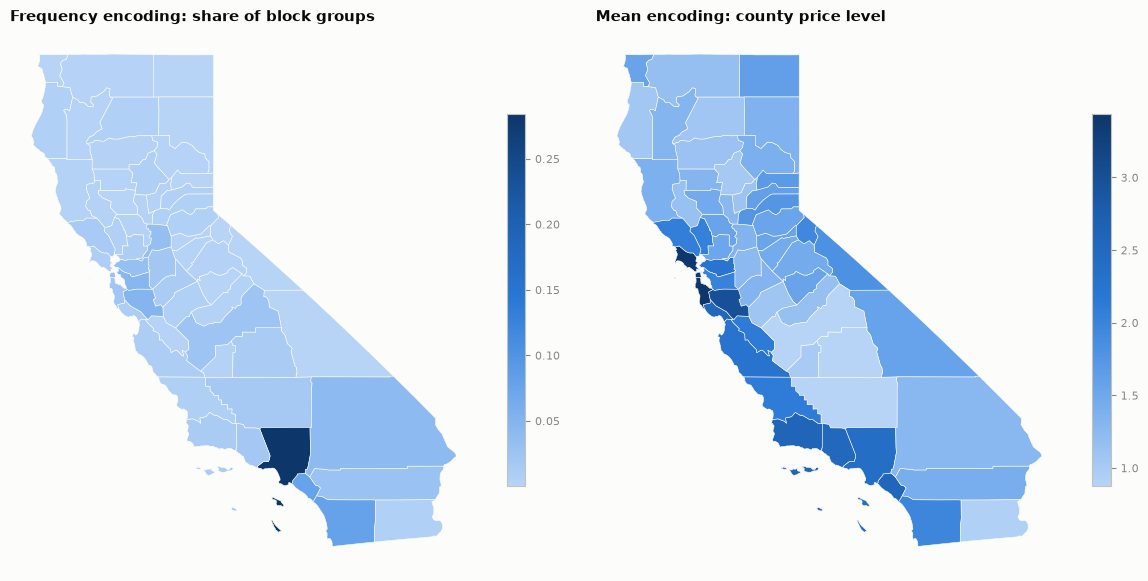

In [60]:
county_map = ca_counties.merge(
    df_cat.groupby("county")[["county_frequency", "county_price_level"]].first(), on="county")

fig, axes = plt.subplots(1, 2, figsize=(12, 6.5))
for ax, col, title in [(axes[0], "county_frequency", "Frequency encoding: share of block groups"),
                       (axes[1], "county_price_level", "Mean encoding: county price level")]:
    county_map.plot(column=col, cmap=BLUES, edgecolor="#fcfcfb", linewidth=0.4, ax=ax, legend=True,
                    legend_kwds={"shrink": 0.6})
    ax.set_title(title)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

## 5.6 Binary encoding (cardinalidade muito alta: `nearest_city`)

- Dê a cada cidade um código inteiro (de 0 a 211) e escreva o código em **binário** (base 2). Cada dígito binário vira uma coluna.
- 212 cidades precisam de apenas **8 colunas** (2⁸ = 256), em vez de 212 com one-hot. Muito compacto.
- **Mas as distâncias não têm significado.** Duas cidades ficam "próximas" se os códigos compartilham muitos dígitos, e os códigos são só alfabéticos. Vamos medir isso.

In [61]:
city_code = df_cat["nearest_city"].astype("category").cat.codes.to_numpy()   # alphabetical codes 0..211
n_bits = int(np.ceil(np.log2(city_code.max() + 1)))
bits = (city_code[:, None] >> np.arange(n_bits)[::-1]) & 1                   # one column per binary digit
city_binary = pd.DataFrame(bits, columns=[f"city_bit_{i}" for i in range(n_bits)], index=df_cat.index)
print(f"{df_cat['nearest_city'].nunique()} cities -> {n_bits} binary columns")
pd.concat([df_cat["nearest_city"], city_binary], axis=1).drop_duplicates("nearest_city").head(4)

212 cities -> 8 binary columns


,nearest_city,city_bit_0,city_bit_1,city_bit_2,city_bit_3,city_bit_4,city_bit_5,city_bit_6,city_bit_7
0,Berkeley,0,0,0,0,1,1,0,1
33,Oakland,0,1,1,1,0,1,1,1
140,Alameda,0,0,0,0,0,0,0,0
282,San Leandro,1,0,1,0,0,1,1,1


In [62]:
from scipy.stats import spearmanr
from sklearn.metrics.pairwise import haversine_distances

# For every pair of cities: distance between their binary codes vs. real distance in km
city_list = df_cat["nearest_city"].astype("category").cat.categories      # alphabetical, like the codes
city_xy = ca_cities.set_index("City").loc[city_list, ["lat", "lon"]]
city_bits = (np.arange(len(city_list))[:, None] >> np.arange(n_bits)[::-1]) & 1

km_matrix = haversine_distances(np.radians(city_xy)) * EARTH_RADIUS_KM       # real distances
bit_matrix = (city_bits[:, None, :] != city_bits[None, :, :]).sum(axis=2)   # number of different digits
upper = np.triu_indices(len(city_list), k=1)
rho, _ = spearmanr(bit_matrix[upper], km_matrix[upper])
print(f"Correlation between 'binary distance' and real distance: {rho:.3f}")

Correlation between 'binary distance' and real distance: 0.011


**Os códigos binários não conhecem geografia:**

- Berkeley, Oakland, Alameda e San Leandro são vizinhas, mas seus códigos binários são completamente diferentes.
- Em todos os pares de cidades, a correlação entre a "distância binária" e a distância real é **0,01**. Nenhuma relação.
- O binary encoding (e seu primo, o *hashing*) é um bom truque para **modelos de árvore**, que só precisam diferenciar as categorias. É uma **má escolha para clustering**, em que cada coluna precisa significar "mais parecido" ou "menos parecido".

## 5.7 Resumo: qual encoding usar em clustering?

| Encoding | Coluna (categorias) | Novas colunas | As distâncias fazem sentido? | Para clustering |
|---|---|---|---|---|
| One-hot | `region` (10) | 10 | todas as categorias à mesma distância, mas o scaling distorce isso | só para poucas categorias, e com cuidado |
| Ordinal | `house_age_band` (5) | 1 | sim, elas seguem a ordem | sim, quando a ordem é real |
| Frequency | `county` (58) | 1 | sim, se a frequência significa algo (aqui: urbanização) | sim |
| Target / mean | `county` (58) | 1 | sim: "nível de preço do condado" | sim (suavize as categorias pequenas) |
| Binary | `nearest_city` (212) | 8 | não (correlação 0,01) | não |

**O que levamos para a etapa 7:** `house_age_band_code`, `county_frequency`, `county_price_level` e as 10 colunas `region_*`. A etapa 7 vai julgá-las como qualquer outra coluna. Deixamos as colunas binárias de fora: já sabemos que as distâncias delas não têm significado.

As colunas de texto (`county`, `region`, `nearest_city`, `house_age_band`) continuam na tabela. Elas vão nos ajudar a **descrever** os clusters depois.

In [63]:
# Keep the useful encodings for step 7; the raw text columns stay for describing clusters later.
df_encoded = pd.concat([df_cat, region_onehot], axis=1)
encoded_cols = ["house_age_band_code", "county_frequency", "county_price_level"] + list(region_onehot.columns)
print(f"df_encoded: {df_encoded.shape[0]:,} rows, {df_encoded.shape[1]} columns")
print("Encoded columns we carry forward:", encoded_cols)

df_encoded: 20,555 rows, 27 columns
Encoded columns we carry forward: ['house_age_band_code', 'county_frequency', 'county_price_level', 'region_Central Coast', 'region_Inland Empire', 'region_Los Angeles County', 'region_North Coast', 'region_Northern San Joaquin Valley', 'region_Orange County', 'region_San Diego - Imperial', 'region_San Francisco Bay Area', 'region_Southern San Joaquin Valley', 'region_Superior California']


## Etapa 5 — Conclusão

- Criamos colunas categóricas realistas **juntando dados externos** com três tipos de join: espacial (polígonos dos condados), por chave (tabela condado → região) e por vizinho mais próximo (cidade mais perto).
- Demonstramos **cinco encodings** e medimos o que cada um faz com as distâncias.
- **Em clustering, prefira encodings que produzem um único número com significado:** ordinal (quando existe uma ordem real), frequency e mean encoding (para muitas categorias).
- Use one-hot só com **poucas** categorias, e lembre-se da armadilha do scaling. Evite binary encoding e hashing.
- O `df_encoded` agora guarda as colunas numéricas (unidades naturais), as categorias de texto (para descrever os clusters) e as colunas codificadas (candidatas para a etapa 7).

---
# Etapa 6 — Criação de features

As colunas brutas nem sempre expressam a ideia que nos interessa. A **criação de features** transforma conhecimento do domínio em novas colunas.

Em clustering, isso importa ainda mais: as features **definem o que significa "parecido"**. Se queremos agrupar vizinhanças por estilo de vida e acessibilidade financeira, precisamos de colunas que descrevam estilo de vida e acessibilidade financeira.

Vamos do simples ao criativo:

1. **Features simples:** uma linha de código, uma divisão ou uma multiplicação.
2. **Distância até a costa:** uma feature geográfica de verdade, construída com dados de mapa externos.
3. **Outras features criativas:** distância até grandes cidades, densidade populacional e "mais rico ou mais pobre que os vizinhos".

**Importante:** as novas features são calculadas em **unidades naturais** (`df_encoded`, construído a partir do `df_imputed`). A razão entre dois números já transformados em log ou padronizados não teria significado.

In [64]:
df_features = df_encoded.copy()

## 6.1 Features simples

| Nova feature | Fórmula | O que significa |
|---|---|---|
| `bedroom_share` | `AveBedrms / AveRooms` | fração dos cômodos que são quartos. Alta → apartamentos pequenos; baixa → casas com sala de estar e sala de jantar |
| `rooms_per_person` | `AveRooms / AveOccup` | espaço por pessoa. Baixo → casas lotadas |
| `households` | `Population / AveOccup` | o número de domicílios (uma coluna escondida que reconstruímos na etapa 1) |
| `price_to_income` | `(MedHouseVal × 100,000) / (MedInc × 10,000)` | quantos anos de renda custa uma casa típica. Uma medida clássica de acessibilidade financeira |

In [65]:
df_features["bedroom_share"] = df_features["AveBedrms"] / df_features["AveRooms"]
df_features["rooms_per_person"] = df_features["AveRooms"] / df_features["AveOccup"]
df_features["households"] = df_features["Population"] / df_features["AveOccup"]
df_features["price_to_income"] = (df_features["MedHouseVal"] * 100_000) / (df_features["MedInc"] * 10_000)

simple_features = ["bedroom_share", "rooms_per_person", "households", "price_to_income"]
df_features[simple_features].describe().T

,count,mean,std,min,25%,50%,75%,max
bedroom_share,"20,555.000",0.213,0.057,0.105,0.175,0.203,0.240,1.000
rooms_per_person,"20,555.000",1.975,1.105,0.270,1.531,1.938,2.289,55.222
households,"20,555.000",500.705,380.207,10.000,282.000,410.537,605.000,"6,082.000"
price_to_income,"20,555.000",5.621,3.016,0.714,3.880,4.953,6.579,100.020


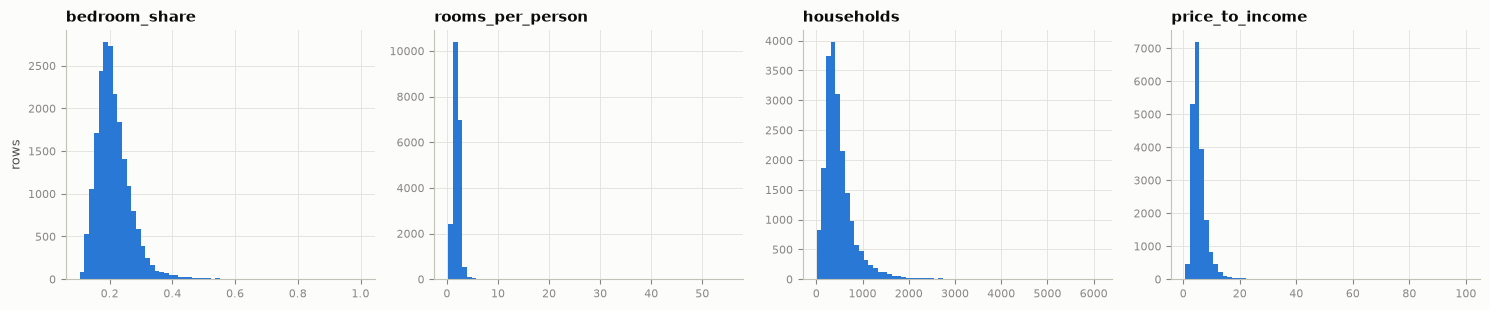

In [66]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, col in zip(axes, simple_features):
    ax.hist(df_features[col], bins=60, color=BLUE)
    ax.set_title(col)
axes[0].set_ylabel("rows")
plt.tight_layout()
plt.show()

**O que as features simples nos dizem:**

- `bedroom_share`: num block group típico, cerca de **1 em cada 5 cômodos** é um quarto (mediana 0,20). Alguns chegam a 50–100%: apartamentos minúsculos ou prédios só com quartos.
- `rooms_per_person`: cerca de **2 cômodos por pessoa** é o típico. O máximo (55) pertence às áreas de veraneio da etapa 1: muitos cômodos vazios, poucos moradores.
- `households`: o block group mediano tem ~410 domicílios, com a mesma cauda longa de `Population`.
- `price_to_income`: uma casa típica custa cerca de **5 anos de renda** (mediana 4,95). O máximo (100) é uma casa com teto de US\$ 500 mil e uma renda declarada muito baixa: um artefato que vamos cortar.
- Três das quatro têm caudas longas à direita, então também precisam do tratamento da etapa 2 (seção 6.4).

## 6.2 Uma feature criativa: distância até a costa

Na Califórnia, estar perto do oceano significa clima mais ameno, praias, vista e, muitas vezes, empregos. Esperamos que os preços das casas caiam conforme nos afastamos para o interior. Mas o dataset só tem latitude e longitude: **a costa não está nos dados**. Precisamos trazê-la de fora.

### Como as pessoas calculam isso? (uma pesquisa rápida na internet)

- **Distância até alguns pontos do litoral.** Uma versão popular deste dataset no Kaggle ([California Housing Prices Data, 5 new features](https://www.kaggle.com/datasets/fedesoriano/california-housing-prices-data-extra-features)) adiciona uma "distância até a costa" calculada com a fórmula **haversine**, além das distâncias até Los Angeles, San Diego, San Jose e San Francisco. Outro projeto ([MatthewBaggins no GitHub](https://github.com/MatthewBaggins/California-Housing-Dataset-Project)) relata uma correlação de cerca de **−0,49** entre a sua "distância do oceano" e o valor das casas.
- **Distância até um mapa do litoral com GeoPandas.** Carregue o formato do litoral (por exemplo, do US Census Bureau ou do Natural Earth), converta tudo para uma projeção de mapa em metros e meça a distância de cada ponto até a linha ([um tutorial de GeoPandas no Python-bloggers](https://python-bloggers.com/2024/10/determining-distance-to-coastline-for-policy-locations-using-geopandas/)).
- **Ponto do litoral mais próximo com uma `BallTree`.** Transforme o litoral em muitos pontos e encontre o mais próximo com a `BallTree` do scikit-learn e a métrica haversine ([curso AutoGIS](https://autogis-site.readthedocs.io/en/2019/notebooks/L3/nearest-neighbor-faster.html)). Ferramentas de pesquisa usam a mesma ideia em escala mundial ([artigo LIGHTHOUSE](https://arxiv.org/html/2506.18842v1)).

**Nosso plano:** implementar os três, compará-los e validar o melhor.

**Os dados do mapa:** o litoral do [Natural Earth](https://www.naturalearthdata.com/) na escala 1:10 milhões (gratuito, domínio público), a partir da sua cópia oficial no GitHub. É um mapa simplificado, com precisão de cerca de 1 km: bom o suficiente para vizinhanças, não para casas individuais.

In [67]:
import shapely
from shapely.geometry import box

coast_path = download(
    "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_10m_coastline.geojson",
    "ne_10m_coastline.geojson")
world_coast = gpd.read_file(coast_path)

# Keep only the coastline around California (a box: lon_min, lat_min, lon_max, lat_max)
coast = gpd.clip(world_coast, box(-125.0, 32.0, -114.0, 42.5))
coast_m = coast.to_crs("EPSG:3310")            # California Albers: a flat map in metres
print(f"Coastline pieces: {len(coast)}, total length: {coast_m.length.sum() / 1000:,.0f} km")

block_groups = gpd.GeoDataFrame(
    index=df_features.index,
    geometry=gpd.points_from_xy(df_features["Longitude"], df_features["Latitude"]),
    crs="EPSG:4326")

Coastline pieces: 9, total length: 2,879 km


### Método A — distância haversine até 9 cidades do litoral (o jeito rápido)

- A fórmula **haversine** dá a distância entre dois pontos numa esfera, a partir da latitude e da longitude.
- Pegamos 9 cidades do litoral na nossa tabela de cidades e guardamos, para cada block group, a distância até a mais próxima.

In [68]:
COASTAL_CITIES = ["San Diego", "Oceanside", "Huntington Beach", "Long Beach", "Santa Monica",
                  "Oxnard", "Santa Barbara", "Santa Cruz", "San Francisco"]
coastal_points = ca_cities[ca_cities["City"].isin(COASTAL_CITIES)]
assert len(coastal_points) == len(COASTAL_CITIES)

tree = BallTree(np.radians(coastal_points[["lat", "lon"]]), metric="haversine")
distance, _ = tree.query(np.radians(df_features[["Latitude", "Longitude"]]), k=1)
dist_method_a = pd.Series(distance[:, 0] * EARTH_RADIUS_KM, index=df_features.index)

### Método B — distância exata até o litoral com GeoPandas (o jeito GIS)

- Tanto os pontos quanto o litoral são **projetados** em `EPSG:3310`, então as distâncias saem em metros.
- O `sjoin_nearest` encontra o trecho de litoral mais próximo de cada ponto e mede a distância exata até a linha (não só até os seus vértices). Ele usa um índice espacial, então leva menos de um segundo.

In [69]:
nearest_coast = gpd.sjoin_nearest(block_groups.to_crs("EPSG:3310"), coast_m[["geometry"]],
                                  how="left", distance_col="distance_m")
nearest_coast = nearest_coast[~nearest_coast.index.duplicated(keep="first")]
dist_method_b = nearest_coast["distance_m"] / 1000

### Método C — ponto do litoral mais próximo com uma `BallTree` (o jeito rápido por vizinho mais próximo)

- Adicionamos pontos ao longo do litoral, no máximo a cada 500 m (`segmentize`), e guardamos todos eles.
- Uma `BallTree` com a métrica haversine encontra o ponto do litoral mais próximo de cada block group.

In [70]:
dense_coast = coast_m.segmentize(max_segment_length=500)            # a point at least every 500 m
xy = dense_coast.get_coordinates()
coast_points = gpd.GeoSeries(gpd.points_from_xy(xy["x"], xy["y"]), crs="EPSG:3310").to_crs("EPSG:4326")
print(f"Points along the coastline: {len(coast_points):,}")

tree = BallTree(np.radians(np.column_stack([coast_points.y, coast_points.x])), metric="haversine")
distance, _ = tree.query(np.radians(df_features[["Latitude", "Longitude"]]), k=1)
dist_method_c = pd.Series(distance[:, 0] * EARTH_RADIUS_KM, index=df_features.index)

Points along the coastline: 6,591


### Comparando os três métodos

In [71]:
methods_compare = pd.DataFrame({
    "|A - B| (km)": (dist_method_a - dist_method_b).abs(),
    "|C - B| (km)": (dist_method_c - dist_method_b).abs(),
})
display(methods_compare.describe(percentiles=[0.5, 0.9, 0.99]).T.round(2))

print("Median error of method A by region (km):")
print((dist_method_a - dist_method_b).abs().groupby(df_features["region"]).median()
      .sort_values(ascending=False).round(1).to_string())

,count,mean,std,min,50%,90%,99%,max
|A - B| (km),"20,555.000",24.450,43.760,0.000,6.810,71.090,222.800,481.640
|C - B| (km),"20,555.000",0.030,0.060,0.000,0.010,0.080,0.360,1.340


Median error of method A by region (km):
region
Northern San Joaquin Valley   72.100
Superior California           71.800
North Coast                   60.600
Southern San Joaquin Valley   24.500
San Francisco Bay Area        19.500
Central Coast                 12.300
San Diego - Imperial           3.200
Inland Empire                  3.000
Orange County                  2.900
Los Angeles County             1.000


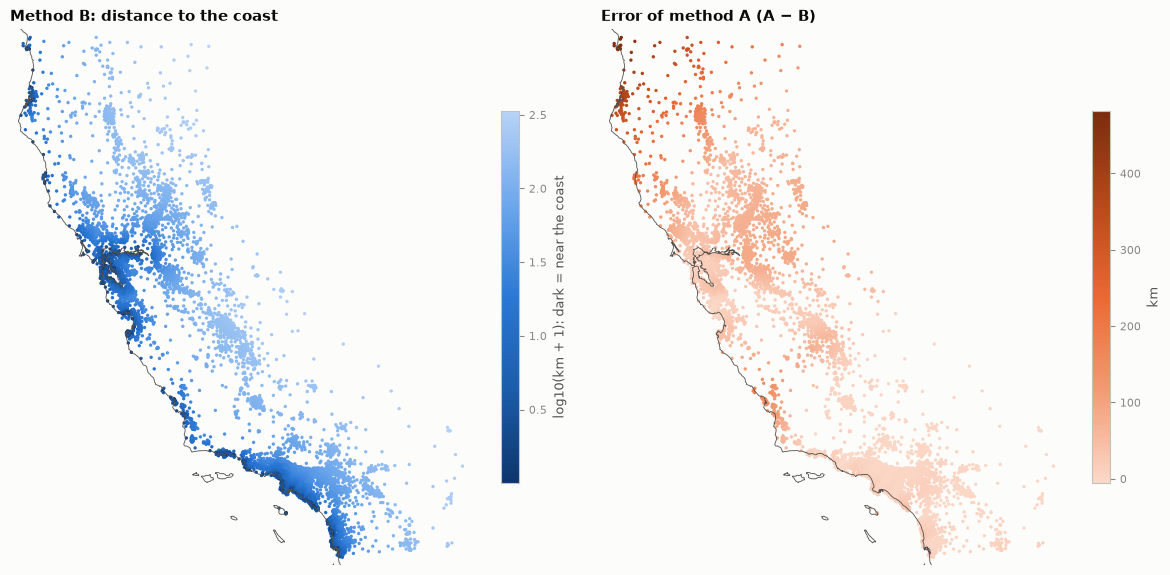

In [72]:
ORANGES = LinearSegmentedColormap.from_list("oranges", ["#fbd9c9", "#f29a73", ORANGE, "#b8481c", "#7a2c0e"])

fig, axes = plt.subplots(1, 2, figsize=(12, 6.5))
panels = [(axes[0], np.log10(dist_method_b + 1), BLUES.reversed(), "Method B: distance to the coast",
           "log10(km + 1): dark = near the coast"),
          (axes[1], dist_method_a - dist_method_b, ORANGES, "Error of method A (A − B)", "km")]
for ax, values, cmap, title, label in panels:
    coast.plot(ax=ax, color="#52514e", linewidth=0.6)
    sc = ax.scatter(df_features["Longitude"], df_features["Latitude"], c=values, cmap=cmap, s=2)
    fig.colorbar(sc, ax=ax, shrink=0.6, label=label)
    ax.set_title(title)
    ax.set_xlim(-124.6, -114.1)
    ax.set_ylim(32.4, 42.1)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

**Comparando os métodos:**

- **O método C concorda quase perfeitamente com o método exato B:** uma diferença mediana de 10 m, e de 1,3 km no pior caso. É uma ótima alternativa quando você tem milhões de pontos.
- **O método A erra 7 km no block group mediano, e até 480 km.** O mapa de erro mostra por quê: ele só "conhece" 9 pontos do litoral, e nenhum deles fica ao norte de San Francisco. Uma casa de praia na North Coast parece "longe da costa", porque a cidade *listada* mais próxima é San Francisco. O erro só é pequeno no sul da Califórnia, onde fica a maioria das 9 cidades.
- **Lição:** uma feature só é tão boa quanto os dados de referência por trás dela. A versão rápida serve para uma primeira tentativa, mas o litoral real é muito melhor, e não é mais difícil de programar.

### Validação 1: ela concorda com um rótulo independente?

- A versão do Kaggle deste dataset tem uma coluna `ocean_proximity`, feita à mão: `ISLAND`, `NEAR OCEAN`, `NEAR BAY`, `<1H OCEAN` (a menos de uma hora do oceano) e `INLAND`.
- Se a nossa feature estiver certa, as linhas `NEAR OCEAN` devem ficar perto da costa, e as `INLAND`, longe.
- Os dois arquivos **não têm coluna de ID**, então fazemos o join por várias colunas que, juntas, identificam um block group. Usamos os valores **originais** (`df_raw`), porque os valores imputados da etapa 4 não bateriam.

In [73]:
kaggle_path = download(
    "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv",
    "housing_kaggle.csv")
kaggle = pd.read_csv(kaggle_path)

join_keys = pd.DataFrame({
    "longitude": df_raw["Longitude"],
    "latitude": df_raw["Latitude"],
    "housing_median_age": df_raw["HouseAge"],
    "population": df_raw["Population"],
    "median_income": df_raw["MedInc"],
    "median_house_value": (df_raw["MedHouseVal"] * 100_000).round(),
}).loc[df_features.index]

labels = (join_keys.reset_index()
          .merge(kaggle[list(join_keys.columns) + ["ocean_proximity"]],
                 on=list(join_keys.columns), how="left", validate="one_to_one")
          .set_index("index")["ocean_proximity"])
print(f"Rows matched: {labels.notna().sum():,} of {len(labels):,}")

label_order = ["ISLAND", "NEAR OCEAN", "NEAR BAY", "<1H OCEAN", "INLAND"]
dist_method_b.groupby(labels).describe()[["count", "25%", "50%", "75%"]].reindex(label_order).round(1)

Rows matched: 20,555 of 20,555


,count,25%,50%,75%
ocean_proximity,,,,
ISLAND,5.000,0.600,0.600,1.200
NEAR OCEAN,"2,644.000",1.700,3.200,6.300
NEAR BAY,"2,280.000",2.300,3.800,5.800
<1H OCEAN,"9,116.000",11.600,17.900,25.000
INLAND,"6,510.000",51.800,79.100,140.900


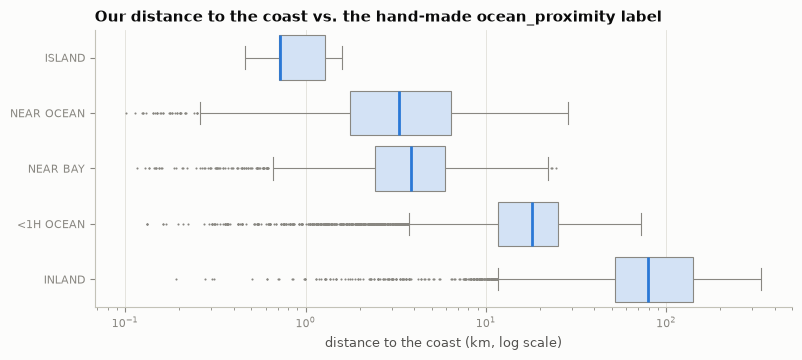

In [74]:
fig, ax = plt.subplots(figsize=(9, 3.6))
sns.boxplot(x=dist_method_b + 0.1, y=labels, order=label_order, ax=ax, color="#cde2fb", linecolor=GRAY,
            linewidth=0.8, fliersize=1.5, flierprops={"markerfacecolor": GRAY, "markeredgecolor": "none"},
            medianprops={"color": BLUE, "linewidth": 2}, log_scale=True)
ax.set_title("Our distance to the coast vs. the hand-made ocean_proximity label")
ax.set_xlabel("distance to the coast (km, log scale)")
ax.set_ylabel("")
plt.show()

### Validação 2: ela conta uma história de negócio?

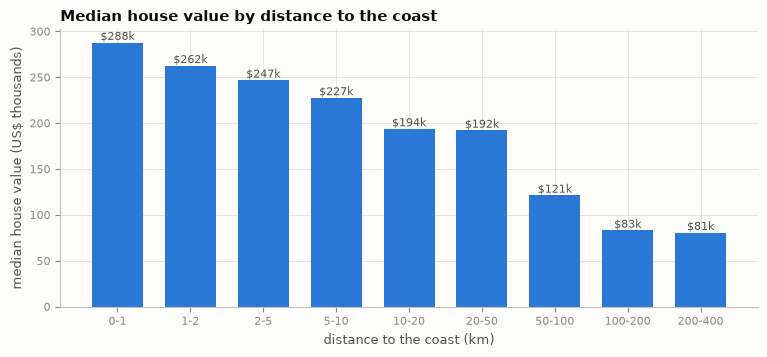

Correlation with MedHouseVal: -0.50 (using log(1 + km))


In [75]:
distance_bins = [0, 1, 2, 5, 10, 20, 50, 100, 200, 400]
value_by_distance = df_features.groupby(pd.cut(dist_method_b, distance_bins), observed=True)["MedHouseVal"].median()

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(range(len(value_by_distance)), value_by_distance * 100, color=BLUE, width=0.7)
ax.set_xticks(range(len(value_by_distance)), [f"{b.left:g}-{b.right:g}" for b in value_by_distance.index])
for i, v in enumerate(value_by_distance * 100):
    ax.text(i, v, f"${v:.0f}k", ha="center", va="bottom", fontsize=8, color="#52514e")
ax.set_title("Median house value by distance to the coast")
ax.set_xlabel("distance to the coast (km)")
ax.set_ylabel("median house value (US$ thousands)")
plt.show()

print(f"Correlation with MedHouseVal: {np.corrcoef(np.log1p(dist_method_b), df_features['MedHouseVal'])[0, 1]:.2f} "
      "(using log(1 + km))")

In [76]:
# Keep the exact method (B) as our feature
df_features["dist_coast_km"] = dist_method_b

**As duas validações passam:**

- **Validação 1:** as medianas seguem a ordem do rótulo feito à mão: `ISLAND` 0,6 km → `NEAR OCEAN` 3,2 km e `NEAR BAY` 3,8 km → `<1H OCEAN` 17,9 km → `INLAND` 79 km. Nossa feature concorda com o rótulo, e ainda carrega mais informação: um número preciso em vez de 5 classes. A sobreposição entre rótulos vizinhos é normal: "a menos de uma hora do oceano" é uma fronteira difusa.
- **Validação 2:** o valor mediano das casas cai de **US\$ 288 mil** no primeiro quilômetro para **US\$ 81 mil** além de 200 km. A correlação (−0,50 em escala log) está de acordo com os −0,49 relatados na internet.
- **Uma escolha a ter em mente:** a nossa "costa" inclui a baía de San Francisco, porque o Natural Earth trata a baía como mar. Por isso as linhas `NEAR BAY` ficam perto dela. Para imóveis, uma vista da baía vale quase tanto quanto uma vista do oceano, então é uma escolha razoável.
- Ficamos com o **método B** (exato) como `dist_coast_km`.

## 6.3 Mais features criativas

As mesmas ferramentas (a tabela de cidades, a `BallTree`, a distância haversine) nos dão mais três ideias:

| Nova feature | Como | O que significa |
|---|---|---|
| `dist_big_city_km` | distância até a cidade mais próxima com 400.000+ habitantes | acesso aos grandes polos de emprego |
| `pop_density_3km` | pessoas que moram num raio de 3 km ÷ área do círculo | o quão urbano é o entorno (pessoas por km²) |
| `income_vs_neighbors` | `log(renda ÷ renda média dos 10 block groups mais próximos)` | mais rico (> 0) ou mais pobre (< 0) que a área ao redor |

As duas últimas são features **espaciais**: descrevem o **contexto** de um block group, não só o block group em si. Não temos a área real de cada block group, mas ainda assim conseguimos medir a densidade ao redor dele.

In [77]:
lat_lon_radians = np.radians(df_features[["Latitude", "Longitude"]])

# (a) Distance to the nearest big city
big_cities = ca_cities[ca_cities["Population"] >= 400_000]
print("Big cities:", ", ".join(big_cities["City"]))
tree = BallTree(np.radians(big_cities[["lat", "lon"]]), metric="haversine")
distance, _ = tree.query(lat_lon_radians, k=1)
df_features["dist_big_city_km"] = distance[:, 0] * EARTH_RADIUS_KM

# (b) Population density within 3 km (the block group itself is included)
RADIUS_KM = 3
neighbour_tree = BallTree(lat_lon_radians, metric="haversine")
neighbours_within = neighbour_tree.query_radius(lat_lon_radians, r=RADIUS_KM / EARTH_RADIUS_KM)
population = df_features["Population"].to_numpy()
people_nearby = np.array([population[idx].sum() for idx in neighbours_within])
df_features["pop_density_3km"] = people_nearby / (np.pi * RADIUS_KM ** 2)

# (c) Income compared with the 10 nearest block groups
_, nearest_idx = neighbour_tree.query(lat_lon_radians, k=11)          # the first "neighbour" is itself
income = df_features["MedInc"].to_numpy()
neighbours_income = income[nearest_idx[:, 1:]].mean(axis=1)
df_features["income_vs_neighbors"] = np.log(income / neighbours_income)

creative_features = ["dist_big_city_km", "pop_density_3km", "income_vs_neighbors"]
df_features[creative_features].describe().T

Big cities: Sacramento, San Diego, Oakland, Long Beach, San Francisco, San Jose, Fresno, Los Angeles


,count,mean,std,min,25%,50%,75%,max
dist_big_city_km,"20,555.000",47.142,55.836,0.346,12.143,24.880,63.312,436.610
pop_density_3km,"20,555.000","2,225.036","1,925.234",0.920,758.975,"1,862.148","3,141.064","12,855.228"
income_vs_neighbors,"20,555.000",-0.021,0.286,-2.074,-0.183,-0.004,0.157,1.623


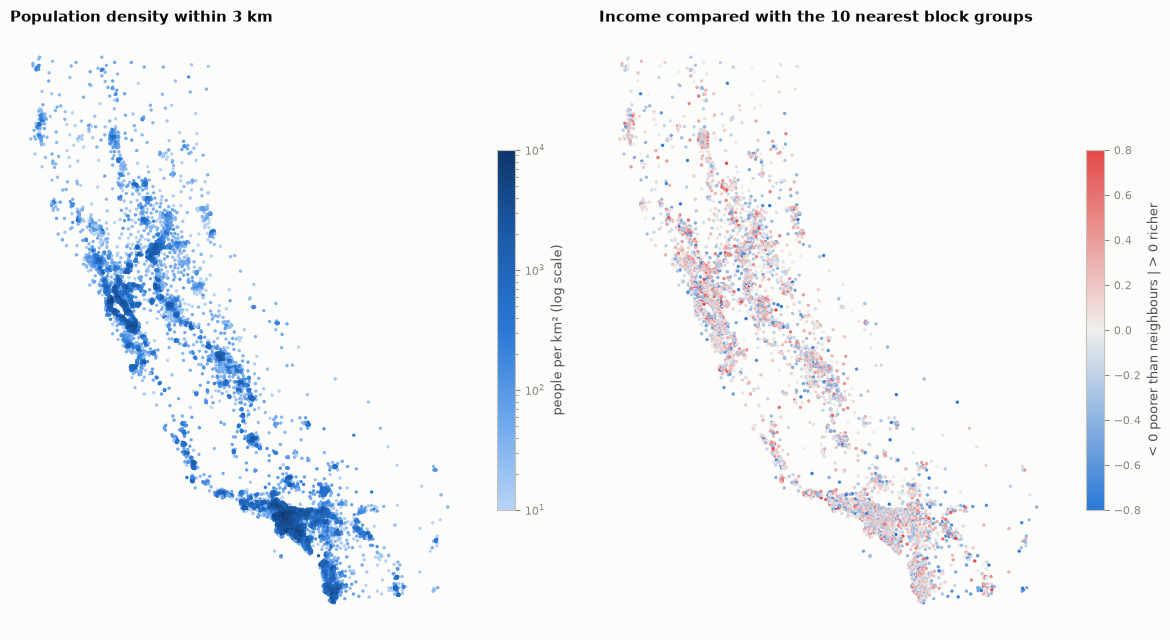

In [78]:
from matplotlib.colors import LogNorm, TwoSlopeNorm

fig, axes = plt.subplots(1, 2, figsize=(12, 6.5))
sc = axes[0].scatter(df_features["Longitude"], df_features["Latitude"], c=df_features["pop_density_3km"],
                     cmap=BLUES, norm=LogNorm(vmin=10, vmax=10_000), s=2)
fig.colorbar(sc, ax=axes[0], shrink=0.6, label="people per km² (log scale)")
axes[0].set_title("Population density within 3 km")

sc = axes[1].scatter(df_features["Longitude"], df_features["Latitude"], c=df_features["income_vs_neighbors"],
                     cmap=DIVERGING, norm=TwoSlopeNorm(vcenter=0, vmin=-0.8, vmax=0.8), s=2)
fig.colorbar(sc, ax=axes[1], shrink=0.6, label="< 0 poorer than neighbours | > 0 richer")
axes[1].set_title("Income compared with the 10 nearest block groups")
for ax in axes:
    ax.set_axis_off()
plt.tight_layout()
plt.show()

**O que os mapas mostram:**

- A **densidade populacional** é mais alta na bacia de Los Angeles, na San Francisco Bay Area e em San Diego, e mais baixa no norte rural e nos desertos. É um eixo **urbano ↔ rural** limpo que nenhuma coluna original mede diretamente (`Population` sozinha depende do tamanho do block group).
- A **renda vs. vizinhos** não tem padrão regional, por construção: dividimos pela média local. O que sobra são **contrastes locais**: bolsões ricos ao lado de áreas mais pobres, e vice-versa. Ela separa "um block group rico numa região rica" de "um block group rico numa região pobre".
- A **distância até uma grande cidade** (não mapeada) diz o quão longe cada block group fica dos 8 grandes polos de emprego. A mediana é 25 km.

## 6.4 As novas features também precisam da etapa 2

Novas features podem ter outliers e assimetria, assim como as originais. Nós as verificamos com as mesmas ferramentas da etapa 2 (skewness e o maior z-score).

In [79]:
new_features = simple_features + ["dist_coast_km"] + creative_features
new_check = pd.DataFrame({
    "min": df_features[new_features].min(),
    "median": df_features[new_features].median(),
    "max": df_features[new_features].max(),
    "skew": df_features[new_features].skew(),
    "max_z": [max_abs_z(df_features[c]) for c in new_features],
})
new_check.round(2)

,min,median,max,skew,max_z
bedroom_share,0.100,0.200,1.000,2.070,13.720
rooms_per_person,0.270,1.940,55.220,17.680,48.170
households,10.000,410.540,"6,082.000",3.430,14.680
price_to_income,0.710,4.950,100.020,5.400,31.300
dist_coast_km,0.000,18.870,333.780,1.930,5.870
dist_big_city_km,0.350,24.880,436.610,2.490,6.980
pop_density_3km,0.920,"1,862.150","12,855.230",1.410,5.520
income_vs_neighbors,-2.070,-0.000,1.620,-0.410,7.190


**Lendo a verificação:**

- `rooms_per_person` (max z 48), `price_to_income` (31), `households` (15) e `bedroom_share` (14) têm caudas fortes. Precisam de uma transformação **e** de clipping.
- As duas distâncias são assimétricas à direita (skew de 1,9 a 2,5), mas não têm valores absurdos. Um log basta. Usamos **log(1 + x)** (`log1p`), porque uma distância pode ser 0 e log(0) não existe.
- `income_vs_neighbors` já é uma razão em log. Ela só tem alguns valores extremos (max z 7,2), então apenas a cortamos.
- Para `pop_density_3km` e `bedroom_share`, a melhor transformação não é óbvia, então comparamos as opções abaixo.

In [80]:
# Log is a good default, but not always the best: compare transformations for two columns
for col in ["pop_density_3km", "bedroom_share"]:
    clipped = df_features[col].clip(*df_features[col].quantile([0.005, 0.995]))
    for name, values in [("no transform", clipped), ("log", np.log(clipped)), ("sqrt", np.sqrt(clipped))]:
        print(f"{col:16s} {name:13s} skew = {values.skew():5.2f}   max z = {max_abs_z(values):4.2f}")

pop_density_3km  no transform  skew =  1.28   max z = 4.01
pop_density_3km  log           skew = -1.44   max z = 3.59
pop_density_3km  sqrt          skew =  0.08   max z = 2.71
bedroom_share    no transform  skew =  1.28   max z = 4.52
bedroom_share    log           skew =  0.39   max z = 3.33
bedroom_share    sqrt          skew =  0.81   max z = 3.90


In [81]:
# Step-2 style decisions for the new features: clipping percentile and transformation
NEW_TREATMENT = {
    "bedroom_share":       {"clip_pct": 0.5, "transform": "log"},
    "rooms_per_person":    {"clip_pct": 0.5, "transform": "log"},
    "households":          {"clip_pct": 0.5, "transform": "log"},
    "price_to_income":     {"clip_pct": 0.5, "transform": "log"},
    "dist_coast_km":       {"clip_pct": None, "transform": "log1p"},   # log(1 + x) because x can be ~0
    "dist_big_city_km":    {"clip_pct": None, "transform": "log1p"},
    "pop_density_3km":     {"clip_pct": 0.5, "transform": "sqrt"},    # log over-corrects here (see below)
    "income_vs_neighbors": {"clip_pct": 0.5, "transform": None},      # already a log ratio
}
NEW_CLIP_LIMITS = {
    col: tuple(df_features[col].quantile([rule["clip_pct"] / 100, 1 - rule["clip_pct"] / 100]))
    for col, rule in NEW_TREATMENT.items() if rule["clip_pct"] is not None
}


def treat_new_features(df):
    """Apply the step-2 logic to the step-6 features: clip the extremes, then transform."""
    out = df.copy()
    for col, (low, high) in NEW_CLIP_LIMITS.items():
        out[col] = out[col].clip(low, high)
    for col, rule in NEW_TREATMENT.items():
        if rule["transform"] == "log":
            out[col] = np.log(out[col])
        elif rule["transform"] == "log1p":
            out[col] = np.log1p(out[col])
        elif rule["transform"] == "sqrt":
            out[col] = np.sqrt(out[col])
    return out


treated_new = treat_new_features(df_features[new_features])
pd.DataFrame({
    "skew_before": df_features[new_features].skew(),
    "skew_after": treated_new.skew(),
    "max_z_before": [max_abs_z(df_features[c]) for c in new_features],
    "max_z_after": [max_abs_z(treated_new[c]) for c in new_features],
}).round(2)

,skew_before,skew_after,max_z_before,max_z_after
bedroom_share,2.070,0.390,13.720,3.330
rooms_per_person,17.680,-0.440,48.170,3.510
households,3.430,-0.650,14.680,4.060
price_to_income,5.400,0.380,31.300,3.220
dist_coast_km,1.930,-0.050,5.870,2.350
dist_big_city_km,2.490,0.020,6.980,2.840
pop_density_3km,1.410,0.080,5.520,2.710
income_vs_neighbors,-0.410,-0.320,7.190,3.320


**Depois do tratamento:**

- Toda nova feature tem sua linha mais extrema a no máximo ~4 desvios padrão (max z ≤ 4,06), e uma skewness entre −0,65 e +0,39.
- **A densidade usa raiz quadrada, não log.** O log corrigiu demais (skew −1,44): os block groups rurais viraram uma longa cauda à esquerda. A raiz quadrada dá uma skewness de 0,08.
- **`bedroom_share` usa log** (skew de 1,28 para 0,39).
- **Lição:** o log é um bom padrão, não uma regra. Sempre confira o resultado.

## Etapa 6 — Conclusão

Criamos **8 novas features**, do simples ao criativo:

| Feature | Tipo | Significado |
|---|---|---|
| `bedroom_share` | razão simples | tipo de moradia (apartamentos vs casas) |
| `rooms_per_person` | razão simples | espaço por pessoa / superlotação |
| `households` | razão simples | tamanho do block group em domicílios |
| `price_to_income` | razão simples | acessibilidade financeira (anos de renda por casa) |
| `dist_coast_km` | geográfica, mapa externo | acesso à costa |
| `dist_big_city_km` | geográfica, tabela externa | acesso aos grandes polos de emprego |
| `pop_density_3km` | contexto espacial | urbano ↔ rural |
| `income_vs_neighbors` | contexto espacial | mais rico ou mais pobre que o entorno |

**Principais lições:**

- **Features simples podem ser muito poderosas.** Uma divisão transforma dois números brutos num conceito de negócio (acessibilidade financeira, superlotação).
- **As melhores features muitas vezes vêm de fora do dataset.** A costa não estava nos nossos dados, e deu uma das features mais fortes.
- **Valide uma nova feature** contra algo independente (o rótulo `ocean_proximity`) e confira se ela conta uma história coerente (os preços caem no interior).
- **Novas features precisam do mesmo cuidado** que as originais: verificamos e tratamos os outliers delas (`treat_new_features`).

Agora temos muitas colunas candidatas, e provavelmente várias delas dizem a mesma coisa. A etapa 7 decide quais delas o clustering deve usar.

---
# Etapa 7 — Seleção de features para clustering

Agora temos **dezenas de colunas**. Usar todas no clustering é uma má ideia:

- **A maldição da dimensionalidade.** Com muitas colunas, todas as linhas começam a parecer igualmente distantes umas das outras, e os clusters ficam difusos.
- **Contagem dupla.** Se três colunas dizem a mesma coisa (por exemplo, três versões de "qual o tamanho do block group"), essa ideia ganha **três vezes** o peso nas distâncias. Ninguém decidiu isso de propósito.
- **Ruído.** Uma coluna sem estrutura só borra os grupos.
- **Interpretação.** Um cluster descrito por 7 features claras é fácil de explicar. Com 30 features, não é.

Em clustering **não existe target**, então não dá para perguntar "qual feature prevê melhor?". Em vez disso, usamos métodos **não supervisionados**, cada um respondendo a uma pergunta diferente:

| # | Método | Pergunta |
|---|---|---|
| 0 | Filtro de negócio | Quais colunas combinam com o **objetivo** do clustering? |
| 1 | Filtro de quase-constantes | Quais colunas quase **não têm informação**? |
| 2 | Clustering de correlação | Quais colunas **dizem a mesma coisa**? |
| 3 | PCA | Quantas **dimensões** os dados realmente têm, e quais colunas as definem? |
| 4 | Laplacian score | Quais colunas respeitam a **estrutura de vizinhança** dos dados? |
| 5 | Wrapper (forward selection) | Quais colunas produzem **clusters bem separados**? |

Nenhum método decide sozinho. Combinamos as evidências no final.

In [82]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.neighbors import kneighbors_graph

## 7.1 Método 0 — Comece pelo objetivo

**Nosso objetivo:** agrupar vizinhanças por **tipo**: quem mora lá (renda, tamanho do domicílio), como é a moradia (valor, idade, tamanho) e o entorno (costa, densidade, acesso às cidades). Um "subúrbio rico no litoral" deve ser reconhecido como tal, esteja ele perto de Los Angeles ou de San Francisco.

Esse objetivo já nos diz o que deixar de fora:

- **Posição bruta** (`Latitude`, `Longitude`, as colunas `region_*`). Com elas, os clusters virariam principalmente **regiões do mapa**. Nós as guardamos à parte para mapear e descrever os clusters depois. *Se o objetivo fossem mercados regionais, nós as manteríamos.*
- **Rótulos de texto** (`county`, `region`, `nearest_city`, `house_age_band`): já codificados, ou úteis só para descrever.
- **Flags** (`cap_flags`, `imputed_flags`): anotações sobre como os dados foram gravados, não propriedades de uma vizinhança.

O **significado** da localização continua nas candidatas por meio de `dist_coast_km`, `dist_big_city_km`, `pop_density_3km`, `county_price_level` e `county_frequency`.

In [83]:
original_candidates = ["MedInc", "HouseAge", "AveRooms", "AveBedrms", "Population", "AveOccup", "MedHouseVal"]
encoded_candidates = ["house_age_band_code", "county_frequency", "county_price_level"]
candidates = original_candidates + encoded_candidates + new_features

left_out = ["Latitude", "Longitude"] + list(region_onehot.columns)
print(f"Candidates: {len(candidates)}")
print(f"Left out (kept only for describing the clusters): {len(left_out)} columns")

Candidates: 18
Left out (kept only for describing the clusters): 12 columns


## 7.2 Preparar as candidatas (etapas 2 e 3 de novo)

- Colunas originais: `treat_outliers()` (etapa 2).
- Colunas novas: `treat_new_features()` (etapa 6).
- `county_frequency` é muito assimétrica (só Los Angeles tem 28% das linhas), então também recebe um log.
- Depois, tudo é padronizado com `scale()`, o `StandardScaler` escolhido na etapa 3.

In [84]:
original_cols = ["MedInc", "HouseAge", "AveRooms", "AveBedrms", "Population", "AveOccup",
                 "Latitude", "Longitude", "MedHouseVal"]
X_candidates = pd.concat([
    treat_outliers(df_features[original_cols]),               # step 2 decisions
    df_features[encoded_candidates],
    treat_new_features(df_features[new_features]),            # step 6 decisions
], axis=1)[candidates]

print(f"county_frequency skew: {X_candidates['county_frequency'].skew():.2f} -> "
      f"{np.log(X_candidates['county_frequency']).skew():.2f} after the log")
X_candidates["county_frequency"] = np.log(X_candidates["county_frequency"])

Z_candidates = scale(X_candidates)                            # step 3 decision
print(f"Candidate matrix: {Z_candidates.shape[0]:,} rows x {Z_candidates.shape[1]} columns")

county_frequency skew: 0.84 -> -0.35 after the log
Candidate matrix: 20,555 rows x 18 columns


## 7.3 Método 1 — Colunas quase constantes

Uma coluna em que quase todas as linhas têm o **mesmo valor** não consegue separar grupos. (O `VarianceThreshold` do scikit-learn faz esse trabalho, mas precisa de dados sem scaling; a "fração do valor mais comum" funciona para qualquer coluna.)

In [85]:
information = pd.DataFrame({
    "distinct_values": [df_features[c].nunique() for c in candidates],
    "share_of_most_common_value_%": [100 * df_features[c].value_counts(normalize=True).iloc[0]
                                     for c in candidates],
}, index=candidates)
information.sort_values("share_of_most_common_value_%", ascending=False).head(6).round(1)

,distinct_values,share_of_most_common_value_%
house_age_band_code,5,40.700
county_frequency,52,28.400
county_price_level,58,28.400
HouseAge,2062,5.500
MedHouseVal,3842,4.700
AveBedrms,14212,1.300


**Nada para remover aqui:**

- A coluna mais repetitiva é `house_age_band_code` (5 valores; o mais comum cobre 41% das linhas). Os dois encodings de condado repetem o valor de Los Angeles em 28% das linhas.
- Nenhuma coluna está perto de ser constante, então este filtro não remove nada. Mesmo assim, vale a pena rodá-lo: leva um segundo e, em projetos reais, pega colunas constantes ou do tipo ID.
- Repare num detalhe: `county_frequency` tem só **52** valores diferentes para 58 condados. Alguns condados têm o mesmo número de block groups, então o frequency encoding os juntou (o ponto fraco que mencionamos na etapa 5).

## 7.4 Método 2 — Redundância: quais colunas dizem a mesma coisa?

- Calculamos a **correlação de Spearman** entre cada par de colunas. A Spearman trabalha com postos (ranks), então também pega relações curvas (não lineares).
- Depois, **agrupamos as colunas** (não as linhas!): colunas com correlação absoluta alta ficam no mesmo galho de uma árvore, chamada **dendrograma**.
- Cortamos a árvore em |correlação| = 0,8. Cada grupo abaixo do corte é um conjunto de quase-duplicatas, e mantemos **uma** coluna por grupo.

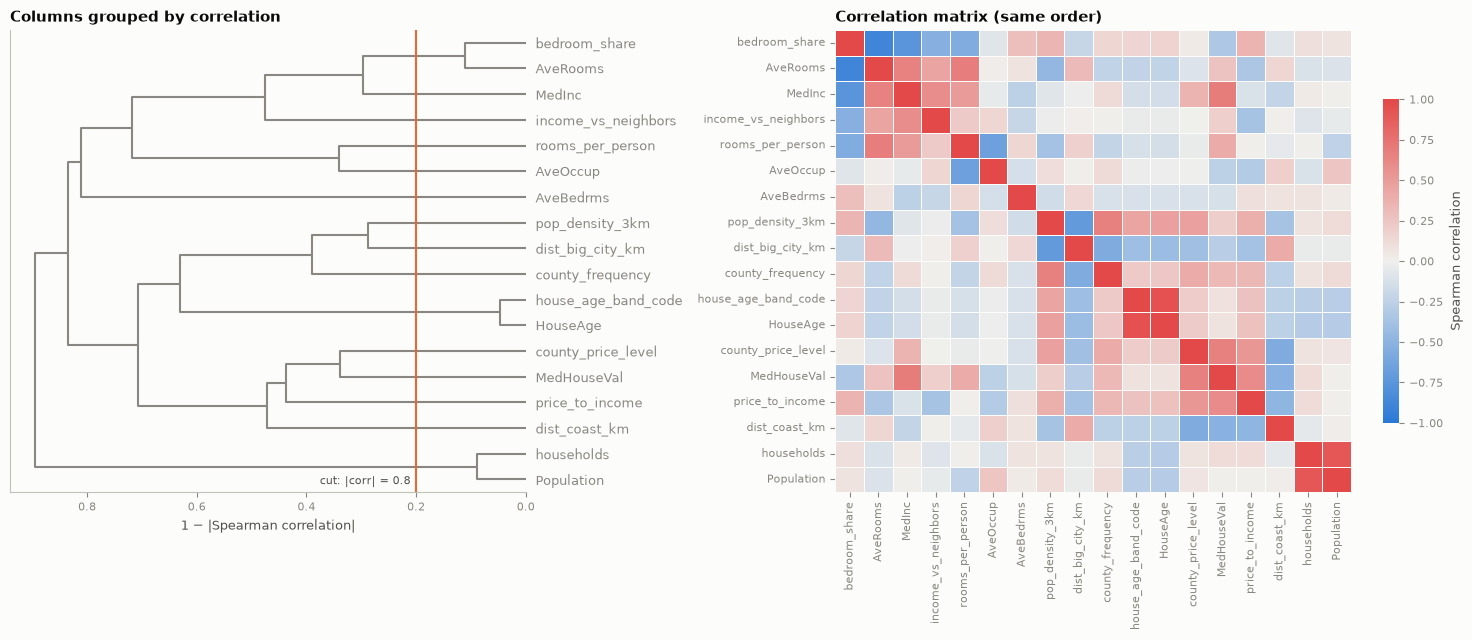

In [86]:
corr = Z_candidates.corr(method="spearman")
column_distance = 1 - corr.abs()                              # 0 = identical, 1 = unrelated
tree_links = linkage(squareform(column_distance.to_numpy(), checks=False), method="average")

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1, 1.25]})
tree = dendrogram(tree_links, labels=candidates, orientation="left", ax=axes[0], leaf_font_size=9,
                  color_threshold=0, above_threshold_color=GRAY)
axes[0].axvline(0.2, color=ORANGE, linewidth=1.5)
axes[0].text(0.21, 2, "cut: |corr| = 0.8", color="#52514e", fontsize=8, ha="right", va="bottom")
axes[0].set_title("Columns grouped by correlation")
axes[0].set_xlabel("1 − |Spearman correlation|")
axes[0].grid(False)

order = tree["ivl"][::-1]                                     # same order as the dendrogram, top to bottom
sns.heatmap(corr.loc[order, order], cmap=DIVERGING, vmin=-1, vmax=1, ax=axes[1],
            cbar_kws={"shrink": 0.7, "label": "Spearman correlation"}, linewidths=0.5, linecolor="#fcfcfb")
axes[1].set_title("Correlation matrix (same order)")
plt.tight_layout()
plt.show()

In [87]:
groups = pd.Series(fcluster(tree_links, t=0.2, criterion="distance"), index=candidates, name="group")
redundant_groups = [list(members.index) for _, members in groups.groupby(groups) if len(members) > 1]
for members in redundant_groups:
    pair_corr = corr.loc[members, members].abs().to_numpy()[np.triu_indices(len(members), 1)]
    print(f"{members}  ->  |corr| between {pair_corr.min():.2f} and {pair_corr.max():.2f}")

['Population', 'households']  ->  |corr| between 0.91 and 0.91
['HouseAge', 'house_age_band_code']  ->  |corr| between 0.95 and 0.95
['AveRooms', 'bedroom_share']  ->  |corr| between 0.89 and 0.89


**Três grupos de quase-duplicatas (|correlação| ≥ 0,8):**

- `Population` e `households` (0,91): as duas medem **o tamanho do block group**. Por enquanto, mantemos `Population` (uma coluna original).
- `HouseAge` e `house_age_band_code` (0,95): a faixa é só uma versão arredondada da idade. Mantemos `HouseAge`, que é mais precisa.
- `AveRooms` e `bedroom_share` (0,89, negativa): casas maiores têm mais salas, então uma fração menor de quartos. Mantemos `AveRooms`, que é mais fácil de explicar.

Alguns outros galhos estão próximos, mas não chegam ao corte (|correlação| < 0,8), então por enquanto mantemos as duas colunas: `pop_density_3km` com `dist_big_city_km` (0,71), e `MedHouseVal` com `MedInc` (0,68) e `county_price_level` (0,66).

In [88]:
# One column per group of near-duplicates (the reasons are in the text above)
duplicates_to_drop = ["households", "house_age_band_code", "bedroom_share"]
after_pairs = [c for c in candidates if c not in duplicates_to_drop]

**Correlações entre pares não bastam.** Uma coluna pode ser uma **combinação** quase perfeita de outras duas, mesmo que a correlação com cada uma delas sozinha seja só moderada. Lembre como construímos algumas features: `rooms_per_person = AveRooms / AveOccup`. Depois do log, isso vira `log(AveRooms) − log(AveOccup)`: uma combinação exata.

O **Variance Inflation Factor (VIF)** pega isso. Para cada coluna, ele pergunta: *o quão bem todas as outras colunas conseguem prevê-la?*

- `VIF = 1 / (1 − R²)`, onde R² é a qualidade dessa previsão (de 0 a 1).
- VIF = 1: a coluna é única. VIF acima de 10 (R² > 0,9): a coluna é quase uma cópia de uma mistura de outras colunas.

In [89]:
from sklearn.linear_model import LinearRegression


def vif(Z):
    """Variance Inflation Factor: how well the OTHER columns predict each column (1 / (1 - R²))."""
    result = {}
    for col in Z.columns:
        others = Z.drop(columns=col)
        r2 = LinearRegression().fit(others, Z[col]).score(others, Z[col])
        result[col] = 1 / (1 - r2)
    return pd.Series(result, name="VIF").sort_values(ascending=False)


vif(Z_candidates[after_pairs]).round(1)

rooms_per_person      263.000
AveRooms              143.300
AveOccup              124.200
MedInc                 13.400
MedHouseVal            10.800
price_to_income         8.100
pop_density_3km         3.500
county_price_level      3.300
income_vs_neighbors     2.300
dist_big_city_km        2.200
county_frequency        2.200
dist_coast_km           2.000
AveBedrms               1.900
HouseAge                1.700
Population              1.300
Name: VIF, dtype: float64

**Uma combinação escondida:**

- `rooms_per_person`, `AveRooms` e `AveOccup` têm VIFs enormes (de 124 a 263). É a combinação exata que construímos na etapa 6: cômodos por pessoa = cômodos ÷ pessoas. Quaisquer duas delas reconstroem a terceira.
- Olhando os pares, isso era invisível: as correlações entre pares eram só de cerca de 0,67.
- **Qual remover?** Mantemos as duas colunas **básicas** (tamanho da casa e tamanho do domicílio) e removemos a razão **derivada**. A superlotação ainda pode ser lida a partir das duas colunas básicas quando descrevermos os clusters.

In [90]:
after_vif_round_1 = [c for c in after_pairs if c != "rooms_per_person"]
vif(Z_candidates[after_vif_round_1]).round(1).head(4)

MedInc            13.400
MedHouseVal       10.800
price_to_income    8.100
AveRooms           3.900
Name: VIF, dtype: float64

**Uma segunda combinação:**

- `MedInc` ainda tem um VIF de 13,4. Mesma história: `price_to_income = MedHouseVal / MedInc`, então o valor das casas e a razão, juntos, quase reconstroem a renda.
- Uma regra mecânica ("remova o maior VIF") removeria `MedInc`, uma coluna básica e muito importante! Em vez disso, removemos a razão derivada, `price_to_income`.
- **Lição:** o VIF diz *quais* colunas estão emaranhadas. *Qual delas remover* é decisão sua. Prefira colunas básicas e fáceis de explicar.

In [91]:
representatives = [c for c in after_vif_round_1 if c != "price_to_income"]
Z_representatives = Z_candidates[representatives]
print(f"Largest VIF now: {vif(Z_representatives).max():.1f}")
print(f"{len(representatives)} columns left after the redundancy checks: {representatives}")

Largest VIF now: 7.3
13 columns left after the redundancy checks: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'MedHouseVal', 'county_frequency', 'county_price_level', 'dist_coast_km', 'dist_big_city_km', 'pop_density_3km', 'income_vs_neighbors']


## 7.5 Método 3 — PCA: quantas dimensões realmente temos?

- O **PCA** (Principal Component Analysis, ou Análise de Componentes Principais) constrói novos eixos, chamados componentes, que resumem as colunas. O primeiro componente captura a maior parte da variação, o segundo a maior parte do que sobrou, e assim por diante.
- Se poucos componentes explicam a maior parte da variação, os dados têm **poucas dimensões reais**. Isso nos diz, mais ou menos, de **quantas features** precisamos.
- Os **loadings** (cargas) mostram quais colunas constroem cada componente, então nos dizem o que significa cada "dimensão real".
- Aqui usamos o PCA só para **entender** os dados. Para o clustering, mantemos as features originais, porque são fáceis de explicar.

Components needed for 80% of the variation: 6 (out of 13 columns)


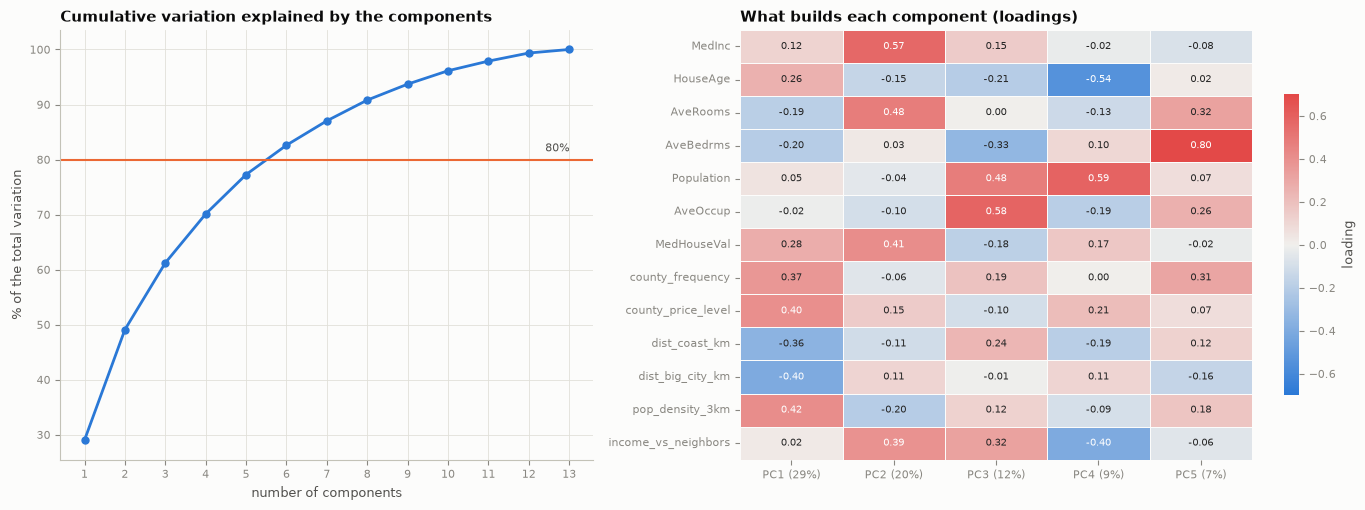

In [92]:
pca = PCA(random_state=RANDOM_STATE).fit(Z_representatives)
cumulative = np.cumsum(pca.explained_variance_ratio_)
n_80 = int(np.argmax(cumulative >= 0.80)) + 1
print(f"Components needed for 80% of the variation: {n_80} (out of {Z_representatives.shape[1]} columns)")

n_show = 5
loadings = pd.DataFrame(pca.components_[:n_show].T, index=Z_representatives.columns,
                        columns=[f"PC{i + 1} ({100 * r:.0f}%)"
                                 for i, r in enumerate(pca.explained_variance_ratio_[:n_show])])

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1, 1.2]})
axes[0].plot(range(1, len(cumulative) + 1), 100 * cumulative, marker="o", markersize=5, linewidth=2, color=BLUE)
axes[0].axhline(80, color=ORANGE, linewidth=1.5)
axes[0].text(len(cumulative), 81, "80%", color="#52514e", fontsize=8, ha="right", va="bottom")
axes[0].set_title("Cumulative variation explained by the components")
axes[0].set_xlabel("number of components")
axes[0].set_ylabel("% of the total variation")
axes[0].set_xticks(range(1, len(cumulative) + 1))

sns.heatmap(loadings, cmap=DIVERGING, vmin=-0.7, vmax=0.7, annot=True, fmt=".2f", annot_kws={"fontsize": 7},
            ax=axes[1], cbar_kws={"shrink": 0.7, "label": "loading"}, linewidths=0.5, linecolor="#fcfcfb")
axes[1].set_title("What builds each component (loadings)")
plt.tight_layout()
plt.show()

**O que o PCA nos diz:**

- **6 componentes explicam 80%** da variação das nossas 13 colunas. Então os dados têm cerca de 6 dimensões "reais", e um conjunto final de 6 a 8 features é razoável.
- O que significam os primeiros componentes, lendo os loadings:
  - **PC1 (29%) — urbano vs. rural:** `pop_density_3km`, `county_price_level` e `county_frequency` de um lado; `dist_big_city_km` e `dist_coast_km` do outro.
  - **PC2 (20%) — riqueza:** `MedInc`, `AveRooms`, `MedHouseVal`, `income_vs_neighbors`.
  - **PC3 (12%) — tamanho do domicílio:** `AveOccup` e `Population` para cima, `AveBedrms` para baixo.
  - **PC4 (9%) — block groups novos e grandes:** `Population` para cima, `HouseAge` para baixo.
  - **PC5 (7%) — quase só `AveBedrms` (0,80).** Uma coluna que forma um componente sozinha compartilha pouco com as outras: ou é informação única, ou é ruído.
- Um bom conjunto final deve **cobrir os eixos principais**: o entorno (urbano, costa), a riqueza, o tamanho do domicílio e a idade das moradias.

## 7.6 Método 4 — Laplacian score

Um método criado para seleção de features **não supervisionada** (He, Cai & Niyogi, 2005).

- Primeiro, conectamos cada linha às suas 10 linhas mais parecidas. Isso constrói um **grafo de vizinhança**: um mapa de "quem está perto de quem".
- Uma boa feature para clustering assume **valores parecidos em linhas conectadas** (respeita a estrutura local), mas ainda **varia** ao longo do dataset inteiro.
- O score é `variação local / variação global`. **Quanto menor, melhor.**
- Para ser rápido, usamos amostras aleatórias de 4.000 linhas e tiramos a média de 3 amostras.

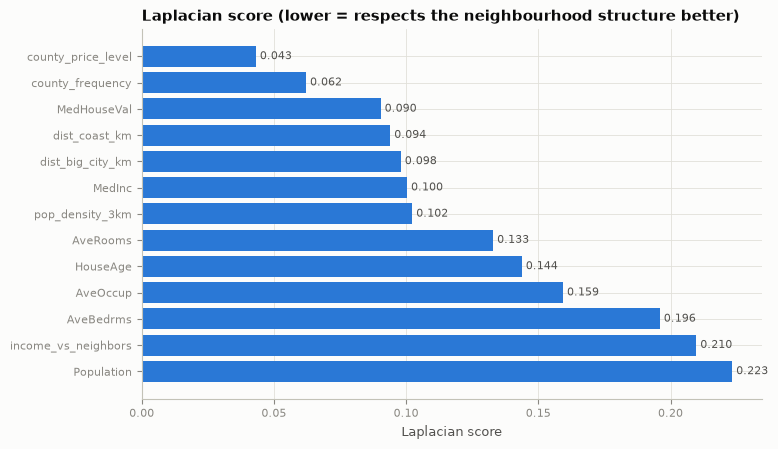

In [93]:
def laplacian_score(X, n_neighbors=10):
    """Laplacian score of each column of X (a scaled DataFrame). Lower = better for clustering."""
    W = kneighbors_graph(X, n_neighbors=n_neighbors, mode="distance")   # distances to the 10 neighbours
    W = W.maximum(W.T)                                                  # make the graph symmetric
    W.data = np.exp(-W.data ** 2 / (2 * np.median(W.data) ** 2))        # close neighbours -> weight near 1
    degree = np.asarray(W.sum(axis=1)).ravel()
    scores = {}
    for col in X.columns:
        f = X[col].to_numpy()
        f = f - (f @ degree) / degree.sum()                             # centre the feature
        global_variation = (f ** 2 * degree).sum()
        local_variation = global_variation - f @ (W @ f)                # small when neighbours agree
        scores[col] = local_variation / global_variation
    return pd.Series(scores)


laplacian = pd.concat([laplacian_score(Z_representatives.sample(4000, random_state=seed)) for seed in range(3)],
                      axis=1).mean(axis=1).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(laplacian.index, laplacian, color=BLUE)
ax.invert_yaxis()
for i, value in enumerate(laplacian):
    ax.text(value, i, f" {value:.3f}", va="center", fontsize=8, color="#52514e")
ax.set_title("Laplacian score (lower = respects the neighbourhood structure better)")
ax.set_xlabel("Laplacian score")
plt.show()

**Lendo o Laplacian score:**

- **Melhores scores:** `county_price_level` e `county_frequency`. Cuidado: essas colunas são **constantes dentro de cada condado**, e linhas parecidas muitas vezes ficam no mesmo condado. Elas parecem "suaves" por construção, então o score gosta delas pelo motivo errado.
- **Em seguida:** `MedHouseVal`, `dist_coast_km`, `dist_big_city_km`, `MedInc` e `pop_density_3km` (de 0,09 a 0,10). São sinais reais, no nível da vizinhança, com uma estrutura clara.
- **Piores scores:** `Population` (0,22), `income_vs_neighbors` (0,21) e `AveBedrms` (0,20). Elas mudam muito entre linhas parecidas: mais ruído do que estrutura.
- Isso reforça duas ideias anteriores: o tamanho de um block group (`Population`) não é uma característica da vizinhança, e `income_vs_neighbors` mede um *contraste local* por construção.

## 7.7 Método 5 — Wrapper: greedy forward selection

Um **wrapper** testa subconjuntos de features com o próprio algoritmo de clustering e fica com o subconjunto de melhor score.

- **Algoritmo:** K-Means com 5 clusters.
- **Score:** a **silhouette** (de −1 a 1). Para cada linha, ela compara a distância até o próprio cluster com a distância até o outro cluster mais próximo. Quanto maior, mais compactos e bem separados são os clusters.
- **Busca gulosa para frente (greedy forward):** comece sem nenhuma feature. A cada passo, adicione a feature que dá a melhor silhouette. Repita.
- **Viés conhecido:** a silhouette costuma **cair** quando adicionamos dimensões, mesmo as úteis. Então lemos a *ordem* em que as features são escolhidas, não só o score.

In [94]:
def silhouette_for(columns, k=5):
    """Silhouette of a K-Means clustering that uses only `columns` (on a 4,000-row sample for speed)."""
    labels = KMeans(n_clusters=k, n_init=3, random_state=RANDOM_STATE).fit_predict(Z_representatives[columns])
    return silhouette_score(Z_representatives[columns], labels, sample_size=4000, random_state=RANDOM_STATE)


selected, path = [], []
remaining = list(Z_representatives.columns)
for step in range(8):                                  # the first 8 steps are enough to see the pattern
    scores = {col: silhouette_for(selected + [col]) for col in remaining}
    best = max(scores, key=scores.get)
    selected.append(best)
    remaining.remove(best)
    path.append({"step": len(selected), "added_feature": best, "silhouette": scores[best]})
forward_path = pd.DataFrame(path).set_index("step")
forward_path.round(3)

,added_feature,silhouette
step,,
1,county_price_level,0.761
2,county_frequency,0.636
3,dist_coast_km,0.462
4,MedHouseVal,0.379
5,pop_density_3km,0.330
6,AveBedrms,0.281
7,dist_big_city_km,0.257
8,AveRooms,0.232


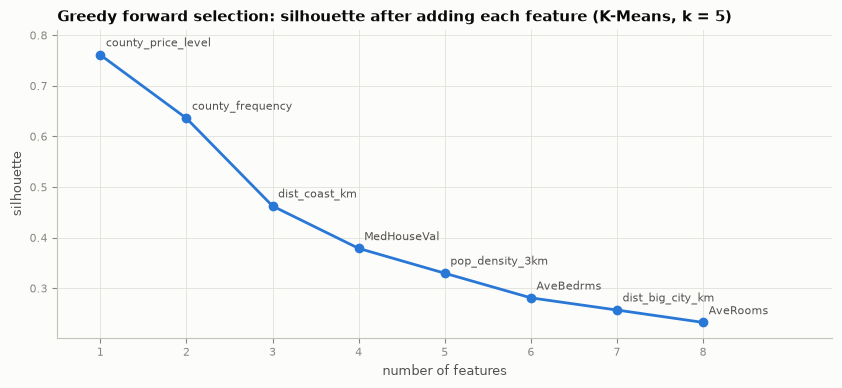

In [95]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(forward_path.index, forward_path["silhouette"], marker="o", markersize=6, linewidth=2, color=BLUE)
for step, row in forward_path.iterrows():
    ax.annotate(row["added_feature"], (step, row["silhouette"]), textcoords="offset points", xytext=(4, 4),
                ha="left", va="bottom", fontsize=8, color="#52514e")
ax.set_title("Greedy forward selection: silhouette after adding each feature (K-Means, k = 5)")
ax.set_xlabel("number of features")
ax.set_ylabel("silhouette")
ax.set_xticks(forward_path.index)
ax.set_xlim(0.5, len(forward_path) + 1.5)
ax.set_ylim(forward_path["silhouette"].min() - 0.03, forward_path["silhouette"].max() + 0.05)
plt.show()

In [96]:
# What if the discrete age band (5 values) were still among the candidates?
band = Z_candidates[["house_age_band_code"]]
band_labels = KMeans(n_clusters=5, n_init=3, random_state=RANDOM_STATE).fit_predict(band)
print(f"Silhouette with house_age_band_code alone (k = 5): "
      f"{silhouette_score(band, band_labels, sample_size=4000, random_state=RANDOM_STATE):.2f}")

Silhouette with house_age_band_code alone (k = 5): 1.00


**O wrapper pode ser enganado:**

- As primeiras escolhas são as duas colunas de **condado**, com uma silhouette muito alta (0,76). Por quê? Uma coluna de condado tem só de 52 a 58 valores diferentes, empilhados em platôs. O K-Means corta facilmente entre os platôs, então os clusters parecem "ótimos". Mas são só **grupos de condados**: o mapa de novo, pela porta dos fundos!
- A célula acima mostra um caso ainda mais claro: a faixa de idade, com 5 valores, dá sozinha uma silhouette **perfeita** de 1,00 com 5 clusters (um cluster por faixa). Um score perfeito, e um clustering inútil.
- Depois dos platôs, ele escolhe colunas de que os outros métodos também gostam: `dist_coast_km`, `MedHouseVal` e `pop_density_3km`.
- A silhouette cai a cada feature adicionada. É o viés conhecido: mais dimensões dão uma silhouette menor, mesmo quando a nova feature é útil.
- **Lição:** um wrapper otimiza um **número**. Colunas discretas ou agrupadas podem "trapacear" esse número. Sempre olhe *o que* ele escolhe.

## 7.8 Juntando as evidências

Cada método olhou para os dados de um ângulo diferente. A tabela coloca os veredictos lado a lado:

- `redundancy`: quase-duplicata (near-duplicate), VIF alto (high VIF) ou ok (método 2);
- `max_loading_PC1-5`: o quanto a coluna ajuda a construir um dos 5 componentes principais (método 3);
- `laplacian_rank`: 1 = melhor estrutura (método 4);
- `wrapper_step`: quando a forward selection a escolheu (método 5); vazio = não está entre as 8 primeiras escolhas.

A decisão final combina essas evidências **com o objetivo** (método 0). Nossas regras:

1. **Uma coluna por ideia:** sem quase-duplicatas, sem combinações emaranhadas.
2. **Cobrir as dimensões principais** encontradas pelo PCA: entorno, riqueza, tamanho do domicílio, idade das moradias.
3. **Preferir colunas no nível da vizinhança** a platôs no nível do condado, que trazem o mapa de volta.
4. **Preferir colunas com estrutura** (um bom Laplacian score) e um significado de negócio claro.

In [97]:
DECISIONS = {
    "MedInc":              ("keep", "wealth of the residents; the core of the 'wealth' component"),
    "MedHouseVal":         ("keep", "price level; best Laplacian score among neighbourhood-level columns"),
    "HouseAge":            ("keep", "age of the housing stock; unique information"),
    "AveOccup":            ("keep", "household size: families vs. singles"),
    "AveRooms":            ("keep", "home size: houses vs. flats"),
    "dist_coast_km":       ("keep", "access to the coast, a key driver of Californian housing"),
    "pop_density_3km":     ("keep", "urban vs. rural setting"),
    "households":          ("drop", "near-duplicate of Population"),
    "house_age_band_code": ("drop", "near-duplicate of HouseAge, and less precise"),
    "bedroom_share":       ("drop", "near-duplicate of AveRooms"),
    "rooms_per_person":    ("drop", "= AveRooms / AveOccup, both kept (VIF)"),
    "Population":          ("drop", "size of the block group (a Census artefact); worst Laplacian score"),
    "AveBedrms":           ("drop", "weak structure (poor Laplacian score); overlaps with AveRooms"),
    "price_to_income":     ("drop", "= MedHouseVal / MedInc, both kept (VIF)"),
    "county_price_level":  ("drop", "county plateau: methods 4-5 like it for the wrong reason"),
    "county_frequency":    ("drop", "county plateau: location through the back door"),
    "dist_big_city_km":    ("drop", "overlaps with pop_density_3km; only 8 cities"),
    "income_vs_neighbors": ("drop", "2nd-worst Laplacian score: local noise more than structure"),
}

evidence = pd.DataFrame(index=candidates)
evidence["redundancy"] = ["near-duplicate" if c in duplicates_to_drop
                          else "high VIF" if c in ["rooms_per_person", "price_to_income"] else "ok"
                          for c in candidates]
evidence["max_loading_PC1-5"] = loadings.abs().max(axis=1).reindex(candidates).round(2)
evidence["laplacian_rank"] = laplacian.rank().reindex(candidates)
evidence["wrapper_step"] = pd.Series(forward_path.index, index=forward_path["added_feature"]).reindex(candidates)
evidence["decision"] = [DECISIONS[c][0] for c in candidates]
evidence["reason"] = [DECISIONS[c][1] for c in candidates]

FINAL_FEATURES = [c for c in candidates if DECISIONS[c][0] == "keep"]
print(f"Final selection ({len(FINAL_FEATURES)} features): {FINAL_FEATURES}")
evidence.sort_values(["decision", "laplacian_rank"], ascending=[False, True])

Final selection (7 features): ['MedInc', 'HouseAge', 'AveRooms', 'AveOccup', 'MedHouseVal', 'dist_coast_km', 'pop_density_3km']


,redundancy,max_loading_PC1-5,laplacian_rank,wrapper_step,decision,reason
MedHouseVal,ok,0.410,3.000,4.000,keep,price level; best Laplacian score among neighb...
dist_coast_km,ok,0.360,4.000,3.000,keep,"access to the coast, a key driver of Californi..."
MedInc,ok,0.570,6.000,NaN,keep,wealth of the residents; the core of the 'weal...
pop_density_3km,ok,0.420,7.000,5.000,keep,urban vs. rural setting
AveRooms,ok,0.480,8.000,8.000,keep,home size: houses vs. flats
HouseAge,ok,0.540,9.000,NaN,keep,age of the housing stock; unique information
AveOccup,ok,0.580,10.000,NaN,keep,household size: families vs. singles
county_price_level,ok,0.400,1.000,1.000,drop,county plateau: methods 4-5 like it for the wr...
county_frequency,ok,0.370,2.000,2.000,drop,county plateau: location through the back door
dist_big_city_km,ok,0.400,5.000,7.000,drop,overlaps with pop_density_3km; only 8 cities


## 7.9 A seleção ajuda? Uma verificação rápida com K-Means

O teste de verdade da seleção de features é o próprio clustering. Rodamos o K-Means para vários números de clusters e comparamos:

- **as 18 candidatas** vs. **a seleção final**;
- dois scores de qualidade: a **silhouette** (quanto maior, melhor) e o **índice de Davies-Bouldin** (quanto menor, melhor).

*Isto é só uma verificação. Escolher o algoritmo de clustering e o número de clusters é trabalho do próximo notebook.*

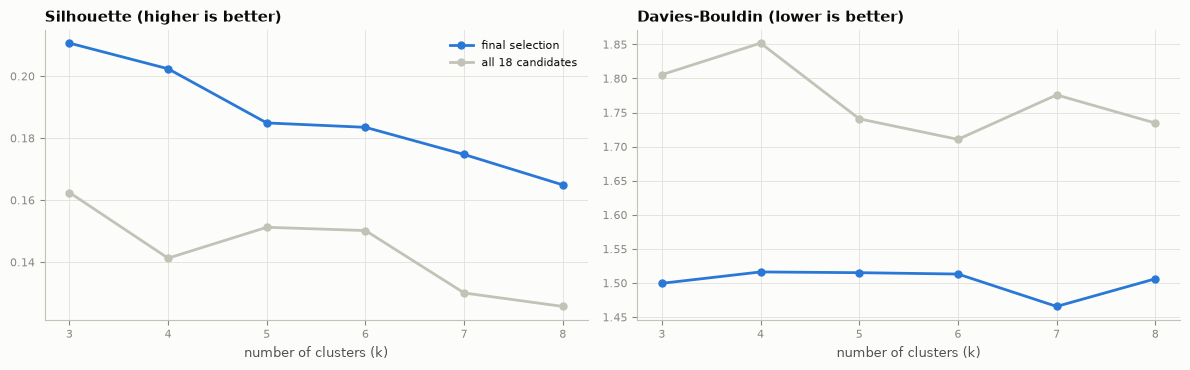

silhouette                    davies_bouldin                
features all 18 candidates final selection all 18 candidates final selection
k                                                                           
3                    0.162           0.211             1.806           1.500
4                    0.141           0.202             1.852           1.516
5                    0.151           0.185             1.741           1.515
6                    0.150           0.183             1.711           1.513
7                    0.130           0.175             1.776           1.466
8                    0.126           0.165             1.735           1.506

In [98]:
Z_final = scale(X_candidates[FINAL_FEATURES])

quality = []
for k in range(3, 9):
    for name, Z in [("all 18 candidates", Z_candidates), ("final selection", Z_final)]:
        labels = KMeans(n_clusters=k, n_init=5, random_state=RANDOM_STATE).fit_predict(Z)
        quality.append({
            "k": k, "features": name,
            "silhouette": silhouette_score(Z, labels, sample_size=5000, random_state=RANDOM_STATE),
            "davies_bouldin": davies_bouldin_score(Z, labels),
        })
quality = pd.DataFrame(quality)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, metric, note in [(axes[0], "silhouette", "higher is better"), (axes[1], "davies_bouldin", "lower is better")]:
    for name, color in [("final selection", BLUE), ("all 18 candidates", LIGHT_GRAY)]:
        data = quality[quality["features"] == name]
        ax.plot(data["k"], data[metric], marker="o", markersize=5, linewidth=2, color=color, label=name)
    ax.set_title(f"{metric.replace('_', '-').title()} ({note})")
    ax.set_xlabel("number of clusters (k)")
axes[0].legend(loc="upper right")
plt.tight_layout()
plt.show()

quality.pivot(index="k", columns="features", values=["silhouette", "davies_bouldin"]).round(3)

**A seleção ajuda:**

- A seleção final gera **clusters mais bem separados para todo k**: silhouette de 0,165 a 0,211 em vez de 0,126 a 0,162, e Davies-Bouldin de 1,47 a 1,52 em vez de 1,71 a 1,86.
- Sejamos honestos sobre o porquê. Parte do ganho vem de ter menos dimensões (o viés da silhouette que acabamos de ver). A outra parte é real: removemos duplicatas que contavam algumas ideias duas vezes, e colunas com mais ruído do que estrutura.
- Para a seleção final, os dois scores mudam pouco entre k = 3 e k = 8: não existe um número "óbvio" de clusters. Escolher o k é trabalho do próximo notebook.

**Uma primeira olhada nos grupos.** Um K-Means rápido com as features finais, só para conferir se os dados preparados levam a grupos que fazem sentido. Descrevemos cada grupo com as **unidades naturais** (não com os valores padronizados), e mapeamos cada grupo separadamente.

In [99]:
N_GROUPS = 6       # only for this preview
preview = KMeans(n_clusters=N_GROUPS, n_init=10, random_state=RANDOM_STATE).fit(Z_final)
group = pd.Series(preview.labels_, index=Z_final.index, name="group")

profile = df_features[FINAL_FEATURES].groupby(group).median()
profile.insert(0, "block_groups", group.value_counts().sort_index())
profile["value_capped_%"] = 100 * cap_flags["MedHouseVal_capped"].groupby(group).mean()
profile["main_region"] = df_features["region"].groupby(group).agg(lambda s: s.value_counts().index[0])
profile.round(2)

,block_groups,MedInc,HouseAge,AveRooms,AveOccup,MedHouseVal,dist_coast_km,pop_density_3km,value_capped_%,main_region
group,,,,,,,,,,
0,3934,5.070,17.000,6.310,3.020,2.220,23.600,"1,039.050",0.560,San Francisco Bay Area
1,4166,3.910,37.760,5.200,2.730,2.130,10.890,"2,938.050",0.170,Los Angeles County
2,4302,2.610,23.720,5.340,2.780,0.930,109.030,391.610,0.000,Superior California
3,2224,6.350,34.000,6.440,2.550,4.500,5.220,"1,739.950",39.300,San Francisco Bay Area
4,3197,2.340,35.000,4.090,3.780,1.440,18.640,"3,929.180",0.130,Los Angeles County
5,2732,2.940,23.890,4.130,2.150,2.040,7.070,"2,304.190",1.900,Los Angeles County


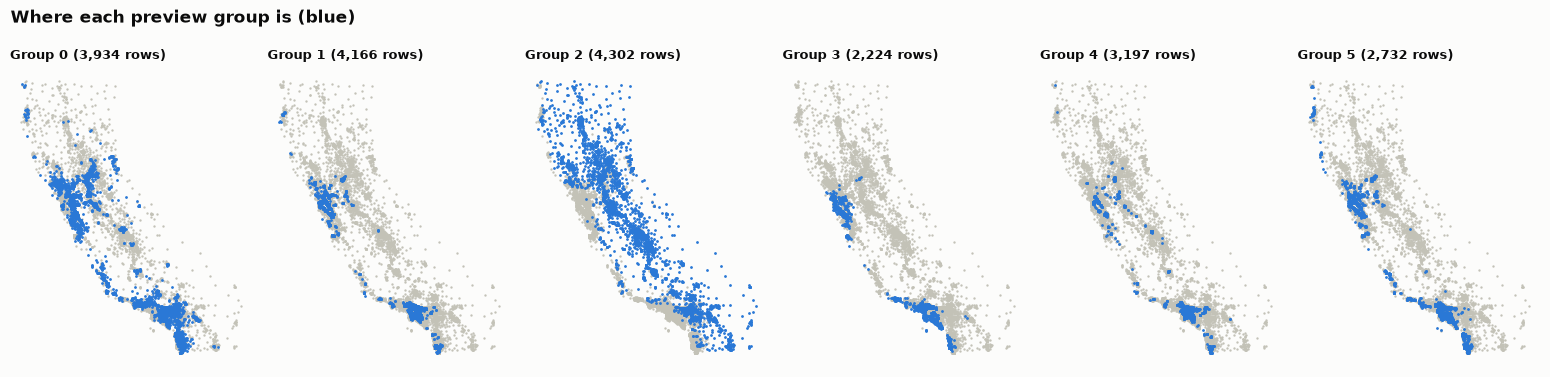

In [100]:
fig, axes = plt.subplots(1, N_GROUPS, figsize=(2.6 * N_GROUPS, 3.8), sharex=True, sharey=True)
for g, ax in enumerate(axes):
    inside = group == g
    ax.scatter(df_features.loc[~inside, "Longitude"], df_features.loc[~inside, "Latitude"], s=0.5, color=LIGHT_GRAY)
    ax.scatter(df_features.loc[inside, "Longitude"], df_features.loc[inside, "Latitude"], s=1, color=BLUE)
    ax.set_title(f"Group {g} ({inside.sum():,} rows)", fontsize=9)
    ax.set_axis_off()
fig.suptitle("Where each preview group is (blue)", fontsize=12, fontweight="bold", x=0.01, ha="left")
plt.tight_layout()
plt.show()

**Os grupos da prévia contam histórias claras** (rendas e valores convertidos a partir da tabela):

| Grupo | Perfil | Um nome possível |
|---|---|---|
| 0 | casas mais novas (17 anos) e grandes, famílias (3,0 pessoas), renda de US\$ 51 mil, a 24 km da costa | **subúrbios familiares mais novos** |
| 1 | casas antigas (38 anos), área densa (2.900 pessoas/km²), renda e preços médios, a 11 km da costa | **bairros urbanos consolidados** |
| 2 | casas mais baratas (US\$ 93 mil), renda de US\$ 26 mil, a 109 km da costa, baixa densidade | **Califórnia do interior e rural** |
| 3 | os mais ricos (US\$ 64 mil) e mais caros (US\$ 450 mil, 39% com US\$ 500 mil ou mais), casas grandes, a 5 km da costa | **áreas ricas do litoral** |
| 4 | renda mais baixa (US\$ 23 mil), casas pequenas com domicílios grandes (3,8 pessoas), os mais densos | **áreas urbanas lotadas e de baixa renda** |
| 5 | casas pequenas, os menores domicílios (2,2 pessoas), a 7 km da costa | **apartamentos perto da costa** |

- A maioria dos grupos aparece em **várias regiões**. Por exemplo, o grupo 3 acompanha o litoral de San Francisco até San Diego. É exatamente o nosso objetivo: **tipos** de vizinhança, não regiões do mapa.
- Esta é só uma prévia, com um k = 6 arbitrário. Mas ela mostra que as features preparadas levam a grupos que uma pessoa de negócios consegue entender.

## 7.10 Salvar o dataset pronto para clustering

- As features finais, **tratadas e padronizadas**, prontas para qualquer algoritmo de clustering.
- Mais as colunas que guardamos à parte para **descrever** os clusters: posição, rótulos de texto e flags.

In [101]:
clustering_ready = pd.concat([
    Z_final.add_prefix("feat_"),                                   # what the algorithm uses
    df_features[["Latitude", "Longitude", "county", "region", "nearest_city"]],   # to describe clusters
    df_features[FINAL_FEATURES].add_prefix("raw_"),                # natural units, for profiles
    cap_flags, imputed_flags,
], axis=1)

output_path = DATA_DIR / "california_clustering_ready.csv"
clustering_ready.to_csv(output_path, index_label="block_group_id")
print(f"Saved {clustering_ready.shape[0]:,} rows x {clustering_ready.shape[1]} columns to {output_path}")
clustering_ready.head(3)

Saved 20,555 rows x 25 columns to data\california_clustering_ready.csv


,feat_MedInc,feat_HouseAge,feat_AveRooms,feat_AveOccup,feat_MedHouseVal,feat_dist_coast_km,feat_pop_density_3km,Latitude,Longitude,county,region,nearest_city,raw_MedInc,raw_HouseAge,raw_AveRooms,raw_AveOccup,raw_MedHouseVal,raw_dist_coast_km,raw_pop_density_3km,HouseAge_capped,MedHouseVal_capped,MedInc_capped,HouseAge_imputed,MedInc_imputed,AveOccup_imputed
0,1.904,1.009,1.167,-0.420,2.131,-0.730,-0.426,37.880,-122.230,Contra Costa,San Francisco Bay Area,Berkeley,8.325,41.000,6.984,2.556,4.526,6.761,"1,099.230",False,False,False,False,False,False
1,1.346,-0.623,0.724,-0.167,1.315,-0.690,-0.434,37.860,-122.220,Contra Costa,San Francisco Bay Area,Berkeley,6.445,21.000,6.238,2.714,3.585,7.162,"1,087.417",False,False,False,False,True,True
2,1.438,1.907,1.838,-0.034,1.259,-0.904,0.624,37.850,-122.240,Alameda,San Francisco Bay Area,Berkeley,6.723,52.000,8.288,2.802,3.521,5.221,"3,055.457",True,False,False,False,True,False


## Etapa 7 — Conclusão

Começamos com **18 candidatas** e ficamos com **7 features**, uma por ideia:

| Feature | Ideia que representa |
|---|---|
| `MedInc` | riqueza dos moradores |
| `MedHouseVal` | nível de preço das moradias |
| `HouseAge` | idade das moradias |
| `AveRooms` | tamanho da casa (casas vs. apartamentos) |
| `AveOccup` | tamanho do domicílio (famílias vs. pessoas sozinhas) |
| `dist_coast_km` | acesso à costa |
| `pop_density_3km` | entorno urbano vs. rural |

**O que cada método trouxe:**

- **O objetivo (método 0)** removeu a posição bruta, os rótulos e as flags antes de qualquer estatística.
- **O clustering de correlação** encontrou três pares de quase-duplicatas.
- **O VIF** encontrou o que os pares não conseguiam ver: as features de razão eram combinações dos seus ingredientes.
- **O PCA** nos disse que os dados têm cerca de 6 dimensões reais, e o que elas significam.
- **O Laplacian score** apontou as colunas ruidosas.
- **O wrapper** mostrou como um score pode ser "trapaceado" por colunas discretas.

**Nenhum método bastou sozinho.** Dois deles favoreceram as colunas de condado pelo motivo errado. A decisão final combinou as evidências com o objetivo do clustering.

**Saída:** `data/california_clustering_ready.csv`, com as features padronizadas (`feat_*`), seus valores em unidades naturais (`raw_*`) e as colunas guardadas à parte para descrever os clusters.

---
# Resumo de todo o pipeline

| Etapa | O que fizemos | Decisão principal | Saída |
|---|---|---|---|
| 1. Detecção de outliers | IQR (escala original e log), verificação de tetos, Isolation Forest e uma explicação do mundo real para cada extremo | Os outliers têm causas diferentes: domicílios coletivos, block groups minúsculos, casas de veraneio, tetos | `outlier_types` |
| 2. Tratamento de outliers | Removemos 85 linhas com um motivo; log e clipping nas colunas assimétricas; flags para os tetos | Uma ferramenta para cada tipo de outlier | `df_clean`, `treat_outliers()` |
| 3. Scaling | Comparamos os scalers Standard, MinMax e Robust pelo peso que cada coluna recebe nas distâncias | `StandardScaler`, depois do tratamento de outliers | `scale()` |
| 4. Tratamento de nulos | Criamos nulos MCAR e MAR e comparamos 6 métodos com os valores reais | Iterative imputer com gradient boosting | `df_imputed` |
| 5. Encoding | Juntamos 3 datasets externos e comparamos 5 encodings | Encodings numéricos com significado; one-hot só com cuidado; nada de códigos binários | `df_encoded` |
| 6. Criação de features | 4 razões simples; distância até a costa (3 métodos, validada); 3 features espaciais | Distância GIS exata; tratar as features novas como as antigas | `df_features`, `treat_new_features()` |
| 7. Seleção de features | Objetivo, verificação de quase-constantes, correlação e VIF, PCA, Laplacian score, wrapper | 7 features cobrindo entorno, riqueza, domicílio e moradia | `california_clustering_ready.csv` |

**Três hábitos para levar com você:**

1. **Sempre pergunte o que uma decisão faz com as distâncias.** Um clustering só é tão bom quanto as suas distâncias.
2. **Entenda antes de transformar.** Cada outlier, cada nulo e cada coluna tinha uma história, e a história decidiu o tratamento.
3. **Meça as suas escolhas.** Comparamos as opções com números (z-scores, pesos na distância, erros de imputação, rótulos de validação, qualidade dos clusters) em vez de escolher por hábito.

**Próximo passo:** rodar os algoritmos de clustering (K-Means, DBSCAN, clustering hierárquico) no dataset salvo, escolher o número de clusters e descrever os segmentos com as colunas que guardamos à parte.